# Piloto fNIRS de Stroop — dois participantes

Participantes: sub-001 e sub-002, runs 1 e 2.

## Etapa 1 — Localização e leitura dos SNIRF

Localizar exatamente um SNIRF por participante e run.
Carregar o sinal bruto e registar a frequência de amostragem,
o número de canais, o número de amostras e o tempo da última amostra.
Inspecionar os códigos, as contagens, os inícios e as durações das
anotações tal como foram carregadas, sem as renomear.

Nesta etapa não se aplica pré-processamento, não se criam épocas,
não se ajusta um GLM e não se escrevem ficheiros.

In [1]:
from pathlib import Path
import re
import warnings

import mne
import pandas as pd

PASTA_ESTUDO = (
    Path(r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra")
    / "PhD_Project_ARDITI_Guilherme Saldanha"
    / "Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
)

SUJEITOS_STROOP = ("sub-001", "sub-002")
RUNS_STROOP = (1, 2)

if not PASTA_ESTUDO.is_dir():
    raise FileNotFoundError(f"Pasta do estudo não encontrada: {PASTA_ESTUDO}")

# 1. Localizar os quatro SNIRF sem escolher ficheiros pela ordem da pasta.
caminhos_stroop = {}

for sujeito in SUJEITOS_STROOP:
    pasta_nirs = PASTA_ESTUDO / sujeito / "nirs"
    if not pasta_nirs.is_dir():
        raise FileNotFoundError(f"Pasta nirs não encontrada: {pasta_nirs}")

    for run in RUNS_STROOP:
        padrao = rf"(?:^|_)tk-stroop_run-0*{run}(?:_|$)"
        pastas = sorted(
            p for p in pasta_nirs.iterdir()
            if p.is_dir() and re.search(padrao, p.name, flags=re.IGNORECASE)
        )
        if len(pastas) != 1:
            raise RuntimeError(
                f"{sujeito} | Stroop run {run}: esperava uma pasta; "
                f"encontrei {len(pastas)}: {pastas}"
            )

        ficheiros = sorted(
            p for p in pastas[0].iterdir()
            if p.is_file() and p.suffix.lower() == ".snirf"
        )
        if len(ficheiros) != 1:
            raise RuntimeError(
                f"{sujeito} | Stroop run {run}: esperava um SNIRF; "
                f"encontrei {len(ficheiros)}: {ficheiros}"
            )

        caminhos_stroop[(sujeito, run)] = ficheiros[0]

# 2. Carregar os sinais brutos e registar as anotações sem as alterar.
piloto_stroop_raw = {}
resumo_stroop = []
anotacoes_stroop = []

for (sujeito, run), caminho in caminhos_stroop.items():
    print(f"\nA ler {sujeito} | Stroop run {run}: {caminho.name}")

    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        raw = mne.io.read_raw_snirf(str(caminho), preload=True, verbose=False)

    piloto_stroop_raw[(sujeito, run)] = raw

    resumo_stroop.append({
        "sujeito": sujeito,
        "run": run,
        "ficheiro": caminho.name,
        "sfreq_hz": raw.info["sfreq"],
        "n_canais": len(raw.ch_names),
        "n_amostras": raw.n_times,
        "ultima_amostra_s": raw.times[-1],
        "n_anotacoes": len(raw.annotations),
        "avisos": " | ".join(dict.fromkeys(str(a.message) for a in avisos)),
    })

    for i, (codigo, inicio, duracao) in enumerate(zip(
        raw.annotations.description,
        raw.annotations.onset,
        raw.annotations.duration,
    ), start=1):
        anotacoes_stroop.append({
            "sujeito": sujeito,
            "run": run,
            "ordem": i,
            "codigo": str(codigo),
            "inicio_anotacao_s": float(inicio),
            "duracao_anotacao_s": float(duracao),
        })

df_stroop_01_runs = pd.DataFrame(resumo_stroop)
df_stroop_01_anotacoes = pd.DataFrame(
    anotacoes_stroop,
    columns=[
        "sujeito", "run", "ordem", "codigo",
        "inicio_anotacao_s", "duracao_anotacao_s",
    ],
)
df_stroop_01_contagens = (
    df_stroop_01_anotacoes
    .groupby(["sujeito", "run", "codigo"])
    .size()
    .rename("n")
    .reset_index()
)

print(f"\nMNE: {mne.__version__}")
print("\nETAPA 1 — RESUMO DAS QUATRO RUNS DE STROOP")
print(df_stroop_01_runs.round(3).to_string(index=False))

print("\nCONTAGEM POR CÓDIGO DE ANOTAÇÃO")
if df_stroop_01_contagens.empty:
    print("Não foram encontradas anotações.")
else:
    print(df_stroop_01_contagens.to_string(index=False))
    print("\nANOTAÇÕES ORIGINAIS — ORDEM, INÍCIO E DURAÇÃO")
    print(df_stroop_01_anotacoes.round(3).to_string(index=False))

print("\nSem pré-processamento. Nenhum ficheiro alterado.")


A ler sub-001 | Stroop run 1: sub-001_ses-01_tk-stroop_run-1_nirs_001.snirf

A ler sub-001 | Stroop run 2: sub-001_ses-01_tk-stroop_run-2_nirs_001.snirf

A ler sub-002 | Stroop run 1: sub-002_ses-01_tk-stroop_run-1_nirs_002.snirf

A ler sub-002 | Stroop run 2: sub-002_ses-01_tk-stroop_run-2_nirs_002.snirf

MNE: 1.12.1

ETAPA 1 — RESUMO DAS QUATRO RUNS DE STROOP
sujeito  run                                      ficheiro  sfreq_hz  n_canais  n_amostras  ultima_amostra_s  n_anotacoes avisos
sub-001    1 sub-001_ses-01_tk-stroop_run-1_nirs_001.snirf    10.173        56        4000           393.118           10       
sub-001    2 sub-001_ses-01_tk-stroop_run-2_nirs_001.snirf    10.173        56        3823           375.718           10       
sub-002    1 sub-002_ses-01_tk-stroop_run-1_nirs_002.snirf    10.173        56        3938           387.023           10       
sub-002    2 sub-002_ses-01_tk-stroop_run-2_nirs_002.snirf    10.173        56        3691           362.742           

### Etapa 1B — Montagem fNIRS na cabeça

Usar a vista superior da cabeça do MNE para representar os
optodos registados no SNIRF. Mostrar uma fonte por ID (`S`),
a vermelho, e um detetor por ID (`D`), a azul.

Não desenhar os pontos médios dos canais. Um optodo partilhado
por vários pares ou comprimentos de onda aparece uma só vez.

Comparar as posições das duas runs de cada participante. Se
coincidirem, mostrar uma única figura; caso contrário, mostrar
as duas runs separadamente.

A figura representa a montagem registada, não uma verificação
do posicionamento real da touca. Nenhum ficheiro é escrito.

ETAPA 1B — MONTAGEM fNIRS NA CABEÇA
sub-001: mesmas posições nas duas runs.


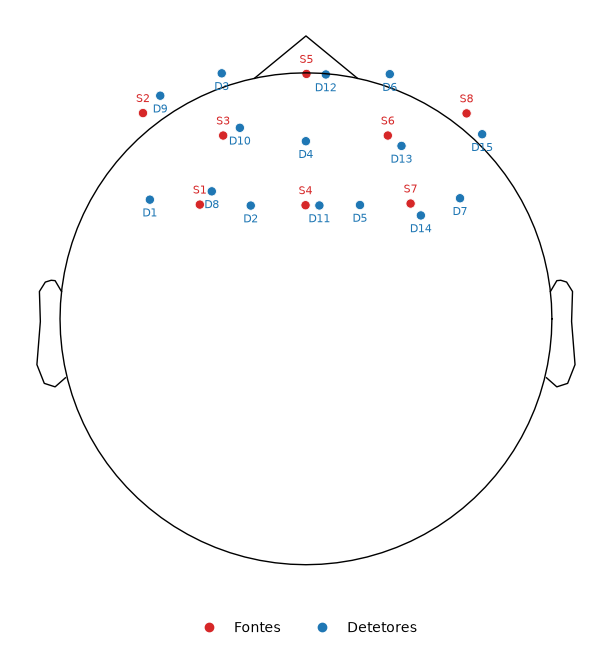

sub-002: mesmas posições nas duas runs.


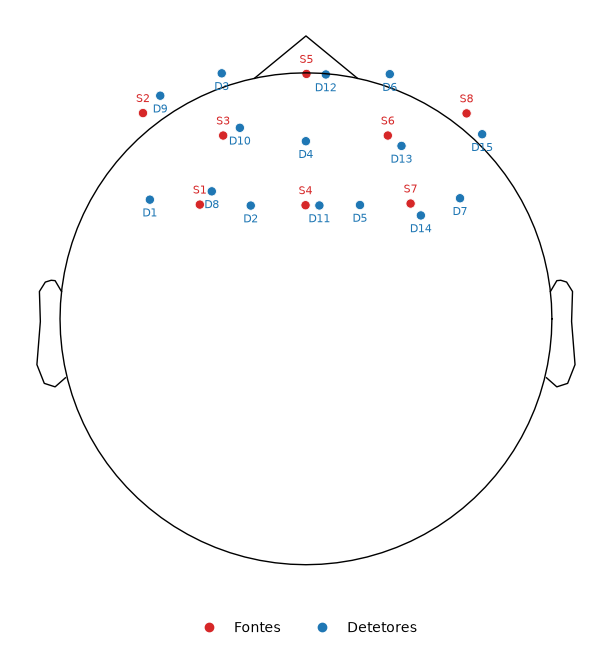

Inspeção visual concluída. Nenhum ficheiro escrito.


In [11]:
import re

import matplotlib.pyplot as plt
import mne
import numpy as np
from IPython.display import display
from matplotlib.collections import PathCollection
from matplotlib.lines import Line2D

if "piloto_stroop_raw" not in globals():
    raise RuntimeError("Executa primeiro a célula Python da Etapa 1.")

SUJEITOS_01B = ("sub-001", "sub-002")
TOL_01B = 1e-6
CORES_01B = {"S": "#d62728", "D": "#1f77b4"}

chaves_01b = {(s, r) for s in SUJEITOS_01B for r in (1, 2)}
faltam_01b = chaves_01b - set(piloto_stroop_raw)
if faltam_01b:
    raise RuntimeError(f"Faltam runs da Etapa 1: {sorted(faltam_01b)}")


def extrair_optodos_01b(raw):
    optodos = {}

    for canal in raw.info["chs"]:
        nome = canal["ch_name"]
        match = re.fullmatch(r"(S\d+)_(D\d+)", nome.split()[0])
        if match is None:
            raise ValueError(f"Nome de canal fNIRS inesperado: {nome}")

        fonte, detetor = match.groups()
        frame = canal["coord_frame"]

        for ident, posicao in (
            (fonte, canal["loc"][3:6]),
            (detetor, canal["loc"][6:9]),
        ):
            xyz = np.asarray(posicao, dtype=float)
            if not np.isfinite(xyz).all():
                raise ValueError(f"{ident}: coordenadas inválidas em {nome}.")

            if ident in optodos:
                xyz_anterior, frame_anterior = optodos[ident]
                if frame != frame_anterior or not np.allclose(
                    xyz, xyz_anterior, atol=TOL_01B, rtol=0
                ):
                    raise ValueError(
                        f"{ident}: coordenadas ou referência espacial "
                        f"inconsistentes em {nome}."
                    )
            else:
                optodos[ident] = (xyz.copy(), frame)

    return optodos


def mostrar_montagem_01b(raw, optodos, titulo):
    ids = sorted(optodos, key=lambda nome: (nome[0], int(nome[1:])))

    # Objeto auxiliar para o gráfico: um ponto por optodo.
    info_fig = mne.create_info(ids, raw.info["sfreq"], ch_types="eeg")

    for canal in info_fig["chs"]:
        xyz, frame = optodos[canal["ch_name"]]
        canal["loc"][:3] = xyz
        canal["coord_frame"] = frame

    fig = mne.viz.plot_sensors(
        info_fig,
        kind="topomap",
        ch_type="eeg",
        show_names=False,
        title=titulo,
        show=False,
    )

    try:
        ax = fig.axes[0]
        colecoes = [
            c for c in ax.collections
            if isinstance(c, PathCollection)
            and len(c.get_offsets()) == len(ids)
        ]
        if len(colecoes) != 1:
            raise RuntimeError(
                "Não foi possível identificar a coleção de pontos no gráfico do MNE."
            )

        pontos = colecoes[0]
        pontos.set_facecolors([CORES_01B[nome[0]] for nome in ids])
        pontos.set_edgecolors("white")
        pontos.set_linewidths(0.6)
        pontos.set_sizes(np.full(len(ids), 45.0))

        for nome, pos in zip(ids, pontos.get_offsets()):
            fonte = nome.startswith("S")
            ax.annotate(
                nome,
                xy=pos,
                xytext=(0, 6 if fonte else -6),
                textcoords="offset points",
                ha="center",
                va="bottom" if fonte else "top",
                fontsize=8,
                color=CORES_01B[nome[0]],
                zorder=5,
            )

        ax.set_axis_off()
        ax.legend(
            handles=[
                Line2D([], [], marker="o", linestyle="none",
                       color=CORES_01B["S"], label="Fontes"),
                Line2D([], [], marker="o", linestyle="none",
                       color=CORES_01B["D"], label="Detetores"),
            ],
            loc="upper center",
            bbox_to_anchor=(0.5, -0.03),
            ncol=2,
            frameon=False,
        )
        display(fig)
    finally:
        plt.close(fig)


print("ETAPA 1B — MONTAGEM fNIRS NA CABEÇA", flush=True)

for sujeito in SUJEITOS_01B:
    raw1 = piloto_stroop_raw[(sujeito, 1)]
    raw2 = piloto_stroop_raw[(sujeito, 2)]
    opt1 = extrair_optodos_01b(raw1)
    opt2 = extrair_optodos_01b(raw2)

    iguais = opt1.keys() == opt2.keys() and all(
        opt1[nome][1] == opt2[nome][1]
        and np.allclose(opt1[nome][0], opt2[nome][0], atol=TOL_01B, rtol=0)
        for nome in opt1
    )

    if iguais:
        print(f"{sujeito}: mesmas posições nas duas runs.", flush=True)
        mostrar_montagem_01b(raw1, opt1, f"Stroop | {sujeito} | runs 1 e 2")
    else:
        print(f"{sujeito}: montagens diferentes; a mostrar ambas as runs.", flush=True)
        mostrar_montagem_01b(raw1, opt1, f"Stroop | {sujeito} | run 1")
        mostrar_montagem_01b(raw2, opt2, f"Stroop | {sujeito} | run 2")

print("Inspeção visual concluída. Nenhum ficheiro escrito.")

## Etapa 2 — Validação dos eventos do Stroop

### Objetivo
Confirmar o significado dos marcadores e verificar se os blocos
registados no PsychoPy correspondem às anotações dos quatro SNIRF.

### Verificações realizadas
- O ficheiro de condições associa `1` à condição congruente e `2`
  à condição incongruente.
- Em cada run, a ordem e os códigos dos 10 blocos do PsychoPy
  coincidem com os das 10 anotações do SNIRF.
- Cada run tem cinco blocos congruentes e cinco incongruentes.
  Cada bloco tem seis apresentações registadas no PsychoPy.

### Interpretação dos tempos
- O marcador é enviado antes da primeira apresentação. O intervalo
  entre o início da rotina `Trigger` e a primeira apresentação foi
  de cerca de 24–125 ms, medido no relógio do PsychoPy. Isto não é
  uma medição do desfasamento entre o PsychoPy e o fNIRS.
- As anotações do SNIRF têm 10 s de duração. No PsychoPy, o intervalo
  entre a primeira apresentação e o início da rotina de repouso foi
  de cerca de 10,5–10,7 s. Esse intervalo não é uma medição direta
  da duração visual do bloco.

### Decisão
A correspondência dos blocos ficou validada nas quatro runs.
Mantêm-se os marcadores e as durações originais do SNIRF.
A escolha dos inícios e das durações para o GLM fica para a etapa
de modelação. Não foi aplicada nenhuma correção entre relógios.

### Fontes consultadas
`Stroop_Block_lastrun.py`, tabela de condições do PsychoPy,
CSV das quatro runs e tabela de anotações da Etapa 1.

### Localização dos ficheiros
Cada CSV do PsychoPy é lido diretamente da pasta `psychopy` do
respetivo participante. A correspondência entre participante, run
e ficheiro é definida no código; não se procuram ficheiros em
subpastas nem se escolhe um ficheiro pela ordem de listagem.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

if "PASTA_ESTUDO" not in globals() or "df_stroop_01_anotacoes" not in globals():
    raise RuntimeError(
        "Executa primeiro a célula Python da Etapa 1 neste notebook."
    )

FICHEIROS_CSV_STROOP = {
    ("sub-001", 1): (
        "sub-001_ses-01_tk-stroop_run-1_psychopy_001_XXX_2026-08-04_13h00.18.867.csv"
    ),
    ("sub-001", 2): (
        "sub-001_ses-01_tk-stroop_run-2_psychopy_001_XXX_2026-08-04_13h18.59.686.csv"
    ),
    ("sub-002", 1): (
        "sub-002_ses-01_tk-stroop_run-1_psychopy_002_XXX_2026-07-28_14h26.30.663.csv"
    ),
    ("sub-002", 2): (
        "sub-002_ses-01_tk-stroop_run-2_psychopy_002XXX_2026-07-28_14h42.56.176.csv"
    ),
}

CONDICOES_STROOP = {1: "Congruente", 2: "Incongruente"}

COLUNAS_PSYCHOPY = [
    "congruent",
    "Trigger.started",
    "Colorword.started",
    "Rest_2.started",
    "Rest_2.stopped",
]

eventos_02 = []
resumo_02 = []

print("ETAPA 2 — AUDITORIA DOS EVENTOS DO STROOP", flush=True)

for (sujeito, run), nome_csv in FICHEIROS_CSV_STROOP.items():
    etiqueta = f"{sujeito} / run {run}"
    caminho = Path(PASTA_ESTUDO) / sujeito / "psychopy" / nome_csv

    print(f"\nA abrir {etiqueta}:\n{caminho}", flush=True)
    if not caminho.is_file():
        raise FileNotFoundError(f"CSV do PsychoPy não encontrado: {caminho}")

    dados = pd.read_csv(caminho, encoding="utf-8-sig")
    print(f"CSV lido: {len(dados)} linhas.", flush=True)
    dados.columns = dados.columns.str.strip()

    em_falta = set(COLUNAS_PSYCHOPY) - set(dados.columns)
    if em_falta:
        raise ValueError(f"{etiqueta}: colunas em falta: {sorted(em_falta)}")

    dados = dados[COLUNAS_PSYCHOPY].apply(pd.to_numeric, errors="raise")

    # Cada Trigger.started abre um bloco experimental.
    # As linhas anteriores ao primeiro trigger não entram na auditoria.
    dados["bloco"] = dados["Trigger.started"].notna().cumsum()
    blocos = dados.loc[dados["bloco"].gt(0)].groupby("bloco", sort=True)

    snirf = (
        df_stroop_01_anotacoes.loc[
            df_stroop_01_anotacoes["sujeito"].eq(sujeito)
            & df_stroop_01_anotacoes["run"].eq(run)
        ]
        .sort_values("ordem")
        .reset_index(drop=True)
    )

    if len(blocos) != 10 or len(snirf) != 10:
        raise ValueError(
            f"{etiqueta}: {len(blocos)} blocos no PsychoPy e "
            f"{len(snirf)} anotações no SNIRF; esperava 10 em cada."
        )

    tempos_snirf = snirf["inicio_anotacao_s"].to_numpy(dtype=float)
    duracoes_snirf = snirf["duracao_anotacao_s"].to_numpy(dtype=float)

    if not np.isfinite(tempos_snirf).all() or not (np.diff(tempos_snirf) > 0).all():
        raise ValueError(f"{etiqueta}: inícios SNIRF inválidos ou fora de ordem.")
    if not np.isfinite(duracoes_snirf).all() or (duracoes_snirf < 0).any():
        raise ValueError(f"{etiqueta}: durações SNIRF inválidas.")

    eventos_run = []

    for i, bloco in blocos:
        trigger = bloco["Trigger.started"].dropna().to_numpy(dtype=float)
        estimulos = bloco["Colorword.started"].dropna().to_numpy(dtype=float)
        repouso_inicio = bloco["Rest_2.started"].dropna().to_numpy(dtype=float)
        repouso_fim = bloco["Rest_2.stopped"].dropna().to_numpy(dtype=float)
        codigos = bloco["congruent"].dropna().unique()

        if (
            len(trigger) != 1
            or len(estimulos) != 6
            or len(repouso_inicio) != 1
            or len(repouso_fim) != 1
            or len(codigos) != 1
            or codigos[0] not in CONDICOES_STROOP
        ):
            raise ValueError(
                f"{etiqueta}, bloco {i}: estrutura inesperada no CSV. "
                f"Triggers={len(trigger)}, apresentações={len(estimulos)}, "
                f"inícios de repouso={len(repouso_inicio)}, "
                f"fins de repouso={len(repouso_fim)}, códigos={codigos.tolist()}."
            )

        codigo = int(codigos[0])
        anotacao = snirf.iloc[i - 1]

        if str(codigo) != str(anotacao["codigo"]).strip():
            raise ValueError(
                f"{etiqueta}, bloco {i}: código PsychoPy={codigo}, "
                f"código SNIRF={anotacao['codigo']}."
            )

        tempos_bloco = np.r_[trigger, estimulos, repouso_inicio, repouso_fim]
        if not np.isfinite(tempos_bloco).all() or not (np.diff(tempos_bloco) > 0).all():
            raise ValueError(
                f"{etiqueta}, bloco {i}: tempos PsychoPy inválidos ou fora de ordem."
            )

        t_trigger = trigger[0]
        t_primeiro = estimulos[0]
        t_repouso = repouso_inicio[0]
        t_fim_repouso = repouso_fim[0]

        eventos_run.append({
            "sujeito": sujeito,
            "run": run,
            "bloco": i,
            "codigo": codigo,
            "condicao": CONDICOES_STROOP[codigo],
            "n_apresentacoes": len(estimulos),
            "inicio_snirf_s": tempos_snirf[i - 1],
            "duracao_anotada_s": duracoes_snirf[i - 1],
            "trigger_psychopy_s": t_trigger,
            "primeiro_estimulo_psychopy_s": t_primeiro,
            "inicio_repouso_psychopy_s": t_repouso,
            "fim_repouso_psychopy_s": t_fim_repouso,
            "trigger_ate_estimulo_ms": 1000 * (t_primeiro - t_trigger),
            "estimulo_ate_repouso_s": t_repouso - t_primeiro,
            "duracao_rotina_repouso_s": t_fim_repouso - t_repouso,
        })

    tabela = pd.DataFrame(eventos_run)
    contagens = tabela["codigo"].value_counts().to_dict()

    if contagens != {1: 5, 2: 5}:
        raise ValueError(f"{etiqueta}: contagem inesperada por código: {contagens}")

    # Comparar intervalos entre marcadores, não as origens dos relógios.
    diferenca_intervalos_ms = 1000 * (
        tabela["trigger_psychopy_s"].diff() - tabela["inicio_snirf_s"].diff()
    )
    tabela["dif_intervalo_psychopy_menos_snirf_ms"] = diferenca_intervalos_ms

    linha = {
        "sujeito": sujeito,
        "run": run,
        "csv": caminho.name,
        "n_congruentes": contagens[1],
        "n_incongruentes": contagens[2],
        "n_apresentacoes": int(tabela["n_apresentacoes"].sum()),
        "duracoes_anotadas_s": tuple(sorted(tabela["duracao_anotada_s"].unique())),
        "max_abs_dif_intervalos_ms": diferenca_intervalos_ms.abs().max(),
    }

    for coluna in [
        "trigger_ate_estimulo_ms",
        "estimulo_ate_repouso_s",
        "duracao_rotina_repouso_s",
    ]:
        linha[f"{coluna}_min"] = tabela[coluna].min()
        linha[f"{coluna}_max"] = tabela[coluna].max()

    eventos_02.append(tabela)
    resumo_02.append(linha)
    print(f"{etiqueta}: 10 blocos emparelhados por ordem e código.", flush=True)

df_stroop_02_eventos = pd.concat(eventos_02, ignore_index=True)
df_stroop_02_resumo = pd.DataFrame(resumo_02)

print("\nETAPA 2 — RESULTADO FINAL")
print(f"Runs verificadas: {len(df_stroop_02_resumo)}")
print(f"Blocos emparelhados: {len(df_stroop_02_eventos)}")
print(f"Apresentações registadas: {df_stroop_02_eventos['n_apresentacoes'].sum()}")

print("\nRESUMO POR RUN")
print(df_stroop_02_resumo.drop(columns="csv").round(3).to_string(index=False))

print("\nTABELA POR BLOCO")
print(df_stroop_02_eventos.round(3).to_string(index=False))

print("\nNenhuma anotação alterada, nenhum relógio alinhado e nenhum ficheiro escrito.")

ETAPA 2 — AUDITORIA DOS EVENTOS DO STROOP

A abrir sub-001 / run 1:
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\psychopy\sub-001_ses-01_tk-stroop_run-1_psychopy_001_XXX_2026-08-04_13h00.18.867.csv
CSV lido: 87 linhas.
sub-001 / run 1: 10 blocos emparelhados por ordem e código.

A abrir sub-001 / run 2:
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\psychopy\sub-001_ses-01_tk-stroop_run-2_psychopy_001_XXX_2026-08-04_13h18.59.686.csv
CSV lido: 87 linhas.
sub-001 / run 2: 10 blocos emparelhados por ordem e código.

A abrir sub-002 / run 1:
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-002\psychopy\sub-002_ses-01_tk-stroop_run-1_psychop

### Resultado reproduzido no notebook
Foram verificados os quatro CSV do PsychoPy: 40 blocos emparelhados
com as anotações SNIRF por ordem e código, com seis apresentações
por bloco (240 no total).

A maior diferença absoluta entre intervalos de marcadores
consecutivos no PsychoPy e no SNIRF foi de 0,688 ms.
Esta comparação verifica o espaçamento entre eventos;
não estima um desfasamento entre relógios.

As tabelas `df_stroop_02_eventos` e `df_stroop_02_resumo`
mantêm separados os 10 s anotados no SNIRF e os 10,498–10,720 s
medidos entre o primeiro estímulo e o início da rotina de repouso.
Nenhum destes valores foi ainda escolhido como duração para o GLM.

Nenhuma anotação foi alterada e nenhum ficheiro foi escrito.

## Etapa 3 — Conversão de intensidade para densidade ótica

### Objetivo
Converter os sinais brutos de intensidade fNIRS em densidade ótica
(OD) nas quatro runs piloto de Stroop, antes do controlo de
qualidade pelo SCI.

### Entrada
`piloto_stroop_raw`, criado na Etapa 1:
`sub-001` e `sub-002`, runs 1 e 2 de cada participante.

### Procedimento
1. Inspecionar as intensidades originais e contar zeros, valores
   negativos e valores não finitos por run e por série afetada.
2. Converter uma cópia de cada sinal para densidade ótica e registar
   eventuais avisos do MNE. Se houver intensidades não finitas,
   sinalizar a run para revisão antes da conversão.
3. Confirmar que a saída contém apenas séries de densidade ótica
   e que todos os valores são finitos.
4. Verificar se foram preservados os nomes e a ordem dos canais,
   o número de amostras, a frequência de amostragem, as marcações
   de canais maus e as anotações originais.

### Saídas
- `piloto_stroop_od`: quatro objetos em densidade ótica,
  disponibilizados em memória se todas as runs passarem as
  verificações de conversão.
- `df_stroop_03_resumo`: resultado da conversão por run.
- `df_stroop_03_ocorrencias`: contagem de ocorrências por série
  afetada, se existirem.

### Limites
Uma conversão bem-sucedida não equivale a aprovação da qualidade
ótica. Não se calcula o SCI, não se aplica TDDR, não se filtra
o sinal e não se alteram os eventos validados na Etapa 2.
Nenhum ficheiro é escrito.

In [3]:
import warnings

import mne
import numpy as np
import pandas as pd

if "piloto_stroop_raw" not in globals():
    raise RuntimeError("Executa primeiro a célula Python da Etapa 1.")

chaves_03 = {
    ("sub-001", 1), ("sub-001", 2),
    ("sub-002", 1), ("sub-002", 2),
}
if set(piloto_stroop_raw) != chaves_03:
    raise RuntimeError("A Etapa 3 espera exatamente as quatro runs piloto de Stroop.")


def mesmas_anotacoes_03(a, b):
    return (
        a.orig_time == b.orig_time
        and np.array_equal(a.description, b.description)
        and np.array_equal(a.onset, b.onset)
        and np.array_equal(a.duration, b.duration)
        and list(a.ch_names) == list(b.ch_names)
    )


piloto_stroop_od = {}
od_temporario_03 = {}
resumo_03 = []
ocorrencias_03 = []

for (sujeito, run), raw in sorted(piloto_stroop_raw.items()):
    chave = (sujeito, run)
    linha = {"sujeito": sujeito, "run": run}
    avisos = []

    print(f"A verificar e converter {sujeito} | Stroop run {run}...", flush=True)

    try:
        if set(raw.get_channel_types()) != {"fnirs_cw_amplitude"}:
            raise ValueError("A entrada não contém apenas séries de intensidade fNIRS.")

        x = raw.get_data()
        finitos = np.isfinite(x)
        negativos = finitos & (x < 0)
        zeros = finitos & (x == 0)
        nao_finitos = ~finitos
        afetadas = (negativos | zeros | nao_finitos).any(axis=1)

        linha.update(
            n_canais=len(raw.ch_names),
            n_amostras=raw.n_times,
            n_negativos=int(negativos.sum()),
            n_zeros=int(zeros.sum()),
            n_nao_finitos=int(nao_finitos.sum()),
            n_series_afetadas=int(afetadas.sum()),
        )

        for i in np.flatnonzero(afetadas):
            ocorrencias_03.append({
                "sujeito": sujeito,
                "run": run,
                "canal": raw.ch_names[i],
                "n_negativos": int(negativos[i].sum()),
                "n_zeros": int(zeros[i].sum()),
                "n_nao_finitos": int(nao_finitos[i].sum()),
            })

        if nao_finitos.any():
            raise ValueError("Intensidades não finitas: rever a entrada antes de converter.")

        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")
            od = mne.preprocessing.nirs.optical_density(raw.copy(), verbose=False)

        linha["estrutura_preservada"] = (
            od.ch_names == raw.ch_names
            and od.n_times == raw.n_times
            and od.first_samp == raw.first_samp
            and od.info["sfreq"] == raw.info["sfreq"]
            and od.info["bads"] == raw.info["bads"]
            and mesmas_anotacoes_03(od.annotations, raw.annotations)
        )

        if not linha["estrutura_preservada"]:
            raise RuntimeError("A estrutura ou as anotações mudaram na conversão.")

        if set(od.get_channel_types()) != {"fnirs_od"}:
            raise RuntimeError("A saída não contém apenas séries de densidade ótica.")

        linha["od_finita"] = bool(np.isfinite(od.get_data()).all())
        if not linha["od_finita"]:
            raise ValueError("A conversão produziu valores não finitos.")

        od_temporario_03[chave] = od
        linha["estado"] = (
            "convertida_com_aviso_ou_ocorrencia"
            if avisos or afetadas.any()
            else "convertida_sem_ocorrencias"
        )

    except Exception as exc:
        linha["estado"] = "rever"
        linha["erro"] = f"{type(exc).__name__}: {exc}"

    linha["avisos_mne"] = " | ".join(
        dict.fromkeys(str(aviso.message) for aviso in avisos)
    )
    resumo_03.append(linha)

df_stroop_03_resumo = pd.DataFrame(resumo_03)
df_stroop_03_ocorrencias = pd.DataFrame(
    ocorrencias_03,
    columns=["sujeito", "run", "canal", "n_negativos", "n_zeros", "n_nao_finitos"],
)

print("\nETAPA 3 — CONVERSÃO PARA DENSIDADE ÓTICA")
print(df_stroop_03_resumo.fillna("").to_string(index=False))

if not df_stroop_03_ocorrencias.empty:
    print("\nOCORRÊNCIAS NAS INTENSIDADES ORIGINAIS — POR SÉRIE")
    print(df_stroop_03_ocorrencias.to_string(index=False))

if set(od_temporario_03) != chaves_03:
    raise RuntimeError("Nem todas as runs passaram a Etapa 3. Revê o resumo acima.")

piloto_stroop_od = od_temporario_03
print("\nQuatro runs convertidas em memória: piloto_stroop_od[(sujeito, run)].")
print("Sem SCI, TDDR ou filtragem. Nenhum ficheiro alterado.")

A verificar e converter sub-001 | Stroop run 1...
A verificar e converter sub-001 | Stroop run 2...
A verificar e converter sub-002 | Stroop run 1...
A verificar e converter sub-002 | Stroop run 2...

ETAPA 3 — CONVERSÃO PARA DENSIDADE ÓTICA
sujeito  run  n_canais  n_amostras  n_negativos  n_zeros  n_nao_finitos  n_series_afetadas  estrutura_preservada  od_finita                     estado avisos_mne
sub-001    1        56        4000            0        0              0                  0                  True       True convertida_sem_ocorrencias           
sub-001    2        56        3823            0        0              0                  0                  True       True convertida_sem_ocorrencias           
sub-002    1        56        3938            0        0              0                  0                  True       True convertida_sem_ocorrencias           
sub-002    2        56        3691            0        0              0                  0                  Tr

## Etapa 4 — Controlo de qualidade pelo SCI

### Objetivo
Avaliar o acoplamento ótico dos pares fonte–detetor nas quatro
runs piloto de Stroop, antes da correção de movimento.

### Entrada
`piloto_stroop_od`: quatro sinais em densidade ótica da Etapa 3.
As quatro conversões terminaram sem avisos, com valores finitos
e com a estrutura e as anotações preservadas.

### Regra de qualidade
- Calcular o Scalp Coupling Index (SCI) na gravação completa,
  antes do TDDR, na banda de 0,7–1,5 Hz, com transições de 0,3 Hz.
- Marcar o par inteiro como mau se pelo menos uma das duas séries
  já estiver marcada como má ou tiver SCI não finito ou inferior
  a 0,7. Um SCI de 0,7 passa o limiar.
- Classificar a distância fonte–detetor: curto se <10 mm,
  longo se >15 mm e intermédio nos restantes casos.
- Contar separadamente os pares curtos físicos e os pares curtos
  elegíveis. Ter zero curtos elegíveis não significa que não
  existam curtos na montagem.

### Saídas
- `piloto_stroop_od_qc`: sinais em densidade ótica com as marcações
  de qualidade, sem remover canais.
- `piloto_stroop_sci_series` e `piloto_stroop_sci_pares`: tabelas
  por série e por par, indexadas por `(sujeito, run)`.
- `df_stroop_04_resumo`: contagem de pares por run.
- `df_stroop_04_curtos`: detalhe dos pares curtos por run.

### Limites
O SCI é um critério de qualidade ótica, não uma validação completa
da gravação. Nesta etapa não se aplica TDDR, SSR ou filtragem
hemodinâmica. Não se alteram as intensidades originais, o sinal
em densidade ótica ou os eventos. Nenhum ficheiro é escrito.

A calcular SCI: sub-001 | Stroop run 1...
A calcular SCI: sub-001 | Stroop run 2...
A calcular SCI: sub-002 | Stroop run 1...
A calcular SCI: sub-002 | Stroop run 2...

ETAPA 4 — RESUMO DA QUALIDADE ÓTICA
sujeito  run  n_pares  n_pares_maus  n_series_maus  n_SCI_nao_finitos  n_curtos  n_curtos_elegiveis  n_longos  n_longos_validos  n_intermedios pares_curtos_elegiveis avisos_mne
sub-001    1       28             9             18                  0         8                   0        20                19              0                 nenhum           
sub-001    2       28             6             12                  0         8                   3        20                19              0 S5_D12, S6_D13, S8_D15           
sub-002    1       28             8             16                  0         8                   0        20                20              0                 nenhum           
sub-002    2       28             8             16                  0         8        

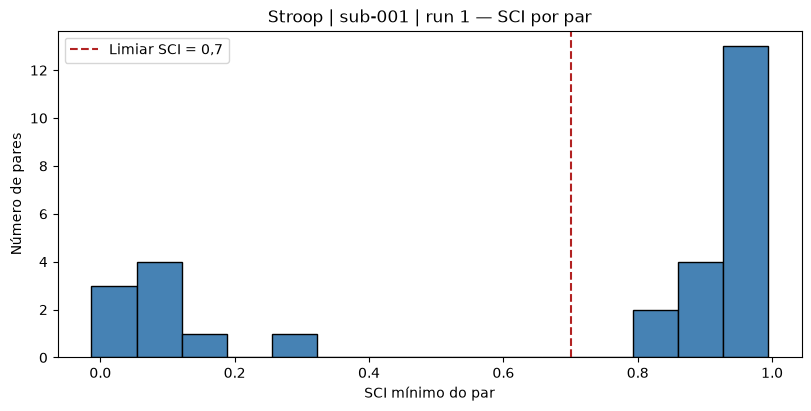

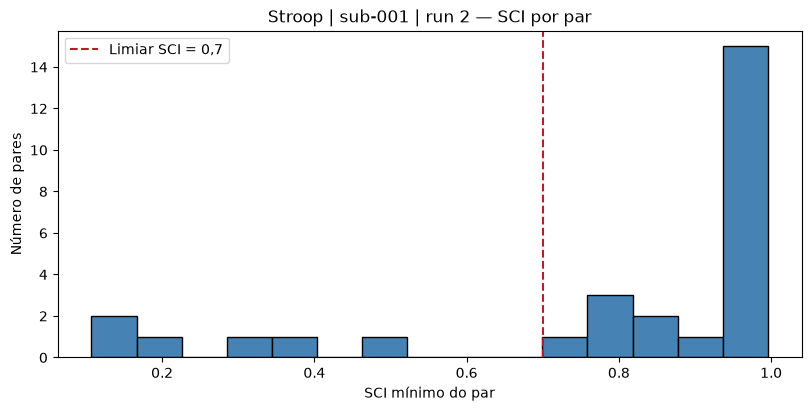

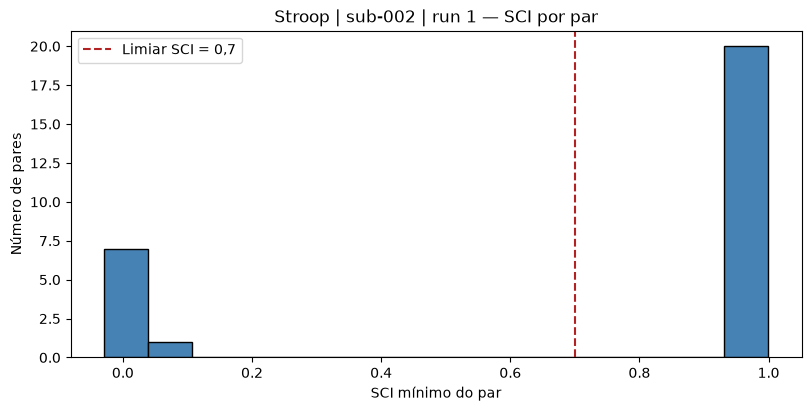

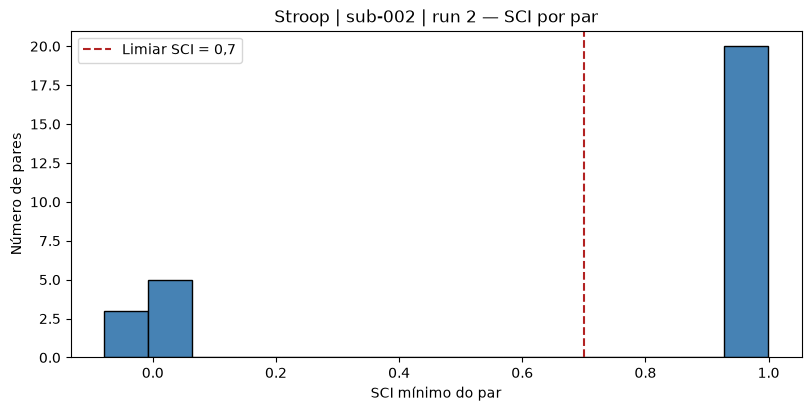


Canais marcados, não removidos. Sem TDDR, SSR ou ficheiros escritos.


In [9]:
import warnings

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from IPython.display import display

CHAVES_STROOP_04 = {
    ("sub-001", 1), ("sub-001", 2),
    ("sub-002", 1), ("sub-002", 2),
}
LIMIAR_SCI_STROOP = 0.7

if "piloto_stroop_od" not in globals():
    raise RuntimeError("Executa primeiro a Etapa 3 neste notebook.")
if set(piloto_stroop_od) != CHAVES_STROOP_04:
    raise RuntimeError("A Etapa 4 espera as quatro runs piloto de Stroop.")

piloto_stroop_od_qc = {}
piloto_stroop_sci_series = {}
piloto_stroop_sci_pares = {}

qc_04, series_04, pares_04 = {}, {}, {}
resumo_04, curtos_04 = [], []


def mesmas_anotacoes_04(a, b):
    return (
        a.orig_time == b.orig_time
        and np.array_equal(a.onset, b.onset)
        and np.array_equal(a.duration, b.duration)
        and np.array_equal(a.description, b.description)
        and list(a.ch_names) == list(b.ch_names)
    )


for chave, od in sorted(piloto_stroop_od.items()):
    sujeito, run = chave
    etiqueta = f"{sujeito} | Stroop run {run}"
    print(f"A calcular SCI: {etiqueta}...", flush=True)

    if set(od.get_channel_types()) != {"fnirs_od"}:
        raise ValueError(f"{etiqueta}: esperava apenas séries de densidade ótica.")

    bads_antes = set(od.info["bads"])
    od_calculo = od.copy()
    od_calculo.info["bads"] = []

    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        sci = np.asarray(
            mne.preprocessing.nirs.scalp_coupling_index(
                od_calculo,
                l_freq=0.7,
                h_freq=1.5,
                l_trans_bandwidth=0.3,
                h_trans_bandwidth=0.3,
                verbose=False,
            ),
            dtype=float,
        )

    dist_m = np.asarray(
        mne.preprocessing.nirs.source_detector_distances(od.info), dtype=float
    )
    forma = (len(od.ch_names),)
    if sci.shape != forma or dist_m.shape != forma:
        raise RuntimeError(f"{etiqueta}: SCI ou distâncias não correspondem às séries.")
    if not np.isfinite(dist_m).all() or (dist_m <= 0).any():
        raise ValueError(f"{etiqueta}: distâncias não finitas ou não positivas.")

    tabela_series = pd.DataFrame({
        "canal": od.ch_names,
        "par": [nome.split()[0] for nome in od.ch_names],
        "distancia_mm": dist_m * 1000,
        "tipo_distancia": np.select(
            [dist_m < 0.010, dist_m > 0.015],
            ["curto", "longo"],
            default="intermedio",
        ),
        "SCI": sci,
        "SCI_nao_finito": ~np.isfinite(sci),
        "SCI_abaixo_limiar": np.isfinite(sci) & (sci < LIMIAR_SCI_STROOP),
        "mau_previamente": [nome in bads_antes for nome in od.ch_names],
    })
    tabela_series["sinalizado_SCI"] = (
        tabela_series["SCI_nao_finito"] | tabela_series["SCI_abaixo_limiar"]
    )
    pares_maus = set(tabela_series.loc[
        tabela_series["sinalizado_SCI"] | tabela_series["mau_previamente"], "par"
    ])
    tabela_series["marcado_mau_final"] = tabela_series["par"].isin(pares_maus)

    tabela_pares = (
        tabela_series.groupby("par", sort=False)
        .agg(
            distancia_mm=("distancia_mm", "first"),
            tipo_distancia=("tipo_distancia", "first"),
            n_tipos_distancia=("tipo_distancia", "nunique"),
            n_series=("canal", "size"),
            SCI_min=("SCI", "min"),
            SCI_max=("SCI", "max"),
            SCI_nao_finito=("SCI_nao_finito", "any"),
            mau_previamente=("mau_previamente", "any"),
            sinalizado_SCI=("sinalizado_SCI", "any"),
            marcado_mau=("marcado_mau_final", "any"),
        )
        .reset_index()
    )

    if not tabela_pares["n_series"].eq(2).all():
        raise RuntimeError(f"{etiqueta}: há pares que não têm duas séries.")
    if not tabela_pares["n_tipos_distancia"].eq(1).all():
        raise RuntimeError(f"{etiqueta}: classificação divergente dentro de um par.")

    tabela_pares["valido"] = ~tabela_pares["marcado_mau"]

    od_qc = od.copy()
    od_qc.info["bads"] = tabela_series.loc[
        tabela_series["marcado_mau_final"], "canal"
    ].tolist()

    if (
        od_qc.ch_names != od.ch_names
        or od_qc.n_times != od.n_times
        or od_qc.first_samp != od.first_samp
        or od_qc.info["sfreq"] != od.info["sfreq"]
        or not mesmas_anotacoes_04(od_qc.annotations, od.annotations)
        or not np.array_equal(od_qc.get_data(), od.get_data())
        or not bads_antes.issubset(od_qc.info["bads"])
    ):
        raise RuntimeError(f"{etiqueta}: a marcação não preservou a entrada.")

    curto = tabela_pares["tipo_distancia"].eq("curto")
    longo = tabela_pares["tipo_distancia"].eq("longo")
    valido = tabela_pares["valido"]
    elegiveis = tabela_pares.loc[curto & valido, "par"].tolist()

    resumo_04.append({
        "sujeito": sujeito,
        "run": run,
        "n_pares": len(tabela_pares),
        "n_pares_maus": int((~valido).sum()),
        "n_series_maus": len(od_qc.info["bads"]),
        "n_SCI_nao_finitos": int(tabela_series["SCI_nao_finito"].sum()),
        "n_curtos": int(curto.sum()),
        "n_curtos_elegiveis": len(elegiveis),
        "n_longos": int(longo.sum()),
        "n_longos_validos": int((longo & valido).sum()),
        "n_intermedios": int((~(curto | longo)).sum()),
        "pares_curtos_elegiveis": ", ".join(elegiveis) or "nenhum",
        "avisos_mne": " | ".join(dict.fromkeys(str(a.message) for a in avisos)),
    })
    curtos_04.append(tabela_pares.loc[curto].assign(sujeito=sujeito, run=run))
    qc_04[chave] = od_qc
    series_04[chave] = tabela_series
    pares_04[chave] = tabela_pares

piloto_stroop_od_qc = qc_04
piloto_stroop_sci_series = series_04
piloto_stroop_sci_pares = pares_04
df_stroop_04_resumo = pd.DataFrame(resumo_04)
df_stroop_04_curtos = pd.concat(curtos_04, ignore_index=True)

print("\nETAPA 4 — RESUMO DA QUALIDADE ÓTICA")
print(df_stroop_04_resumo.to_string(index=False))

print("\nPARES CURTOS — DETALHE")
if df_stroop_04_curtos.empty:
    print("Não foram encontrados pares curtos pela geometria.")
else:
    print(df_stroop_04_curtos[[
        "sujeito", "run", "par", "distancia_mm", "SCI_min",
        "SCI_nao_finito", "mau_previamente", "valido",
    ]].round(4).to_string(index=False))

print("\nHISTOGRAMAS — SCI MÍNIMO POR PAR")
for (sujeito, run), tabela in sorted(piloto_stroop_sci_pares.items()):
    valores = tabela.loc[~tabela["SCI_nao_finito"], "SCI_min"].to_numpy()
    n_omitidos = int(tabela["SCI_nao_finito"].sum())

    fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")

    if valores.size:
        ax.hist(valores, bins=15, color="steelblue", edgecolor="black")
    else:
        ax.text(
            0.5, 0.5, "Sem pares com SCI finito",
            transform=ax.transAxes, ha="center",
        )

    ax.axvline(
        LIMIAR_SCI_STROOP, color="firebrick", linestyle="--",
        linewidth=1.5, label="Limiar SCI = 0,7",
    )
    ax.set(
        title=f"Stroop | {sujeito} | run {run} — SCI por par",
        xlabel="SCI mínimo do par",
        ylabel="Número de pares",
    )
    if n_omitidos:
        ax.text(
            0.02, 0.97, f"Pares omitidos por SCI não finito: {n_omitidos}",
            transform=ax.transAxes, ha="left", va="top", fontsize=9,
        )
    ax.legend()
    display(fig)
    plt.close(fig)

if df_stroop_04_resumo["n_longos_validos"].eq(0).any():
    print("\nATENÇÃO: há uma run sem pares longos válidos. Rever antes do TDDR.")

print("\nCanais marcados, não removidos. Sem TDDR, SSR ou ficheiros escritos.")

## Etapa 5 — Correção de movimento com TDDR

### Objetivo
Aplicar o TDDR às quatro runs piloto de Stroop em densidade
ótica, depois de marcar os pares maus pelo SCI.

### Entrada
`piloto_stroop_od_qc`: sinais em densidade ótica com marcações
de qualidade da Etapa 4. As quatro runs têm pares longos válidos.

### Procedimento
1. Aplicar o TDDR a uma cópia de cada sinal.
2. Confirmar que os valores corrigidos são finitos e que os
   canais, as amostras, as anotações e as marcações de canais
   maus foram preservados.
3. Selecionar um par longo válido nas quatro runs, se existir,
   e mostrar as duas séries antes e depois do TDDR, com a
   mesma escala vertical em cada painel.

### Saídas
- `piloto_stroop_od_tddr`: quatro sinais corrigidos em memória.
- `df_stroop_05_resumo`: verificações e avisos por run.
- Figuras de comparação antes/depois para o par escolhido.

### Limites
A comparação visual é ilustrativa: não demonstra que todos
os artefactos foram removidos. O TDDR não altera a decisão do
SCI. Não se aplica SSR, não se converte para HbO/HbR e não se
escrevem ficheiros.

A aplicar TDDR: sub-001 | Stroop run 1...
A aplicar TDDR: sub-001 | Stroop run 2...
A aplicar TDDR: sub-002 | Stroop run 1...
A aplicar TDDR: sub-002 | Stroop run 2...

ETAPA 5 — RESUMO DO TDDR
sujeito  run  n_series  n_series_nao_marcadas  n_amostras  estrutura_preservada  bads_preservados  anotacoes_preservadas  valores_finitos avisos_mne
sub-001    1        56                     38        4000                  True              True                   True             True           
sub-001    2        56                     44        3823                  True              True                   True             True           
sub-002    1        56                     40        3938                  True              True                   True             True           
sub-002    2        56                     40        3691                  True              True                   True             True           

Par longo escolhido para inspeção: S1_D1


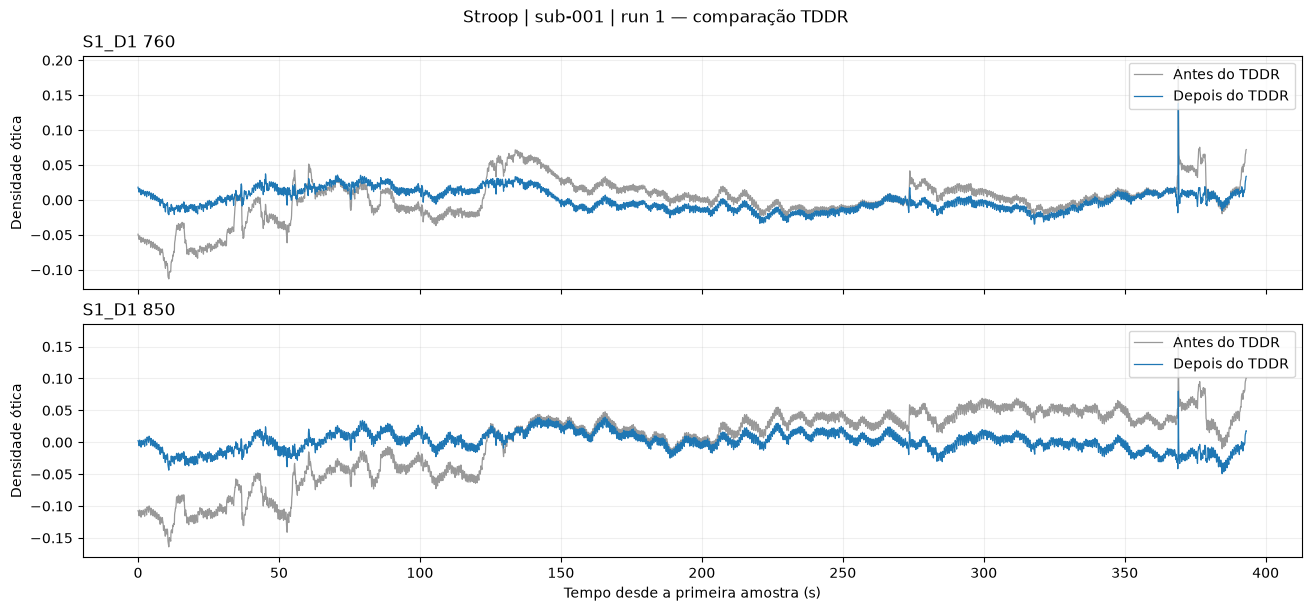

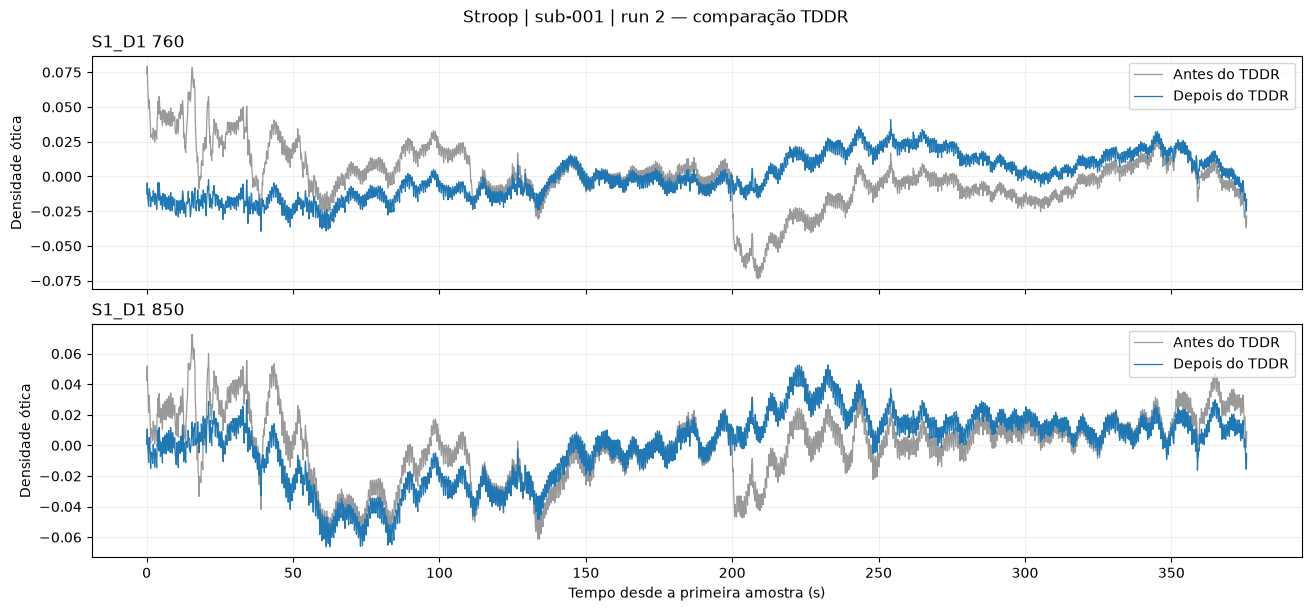

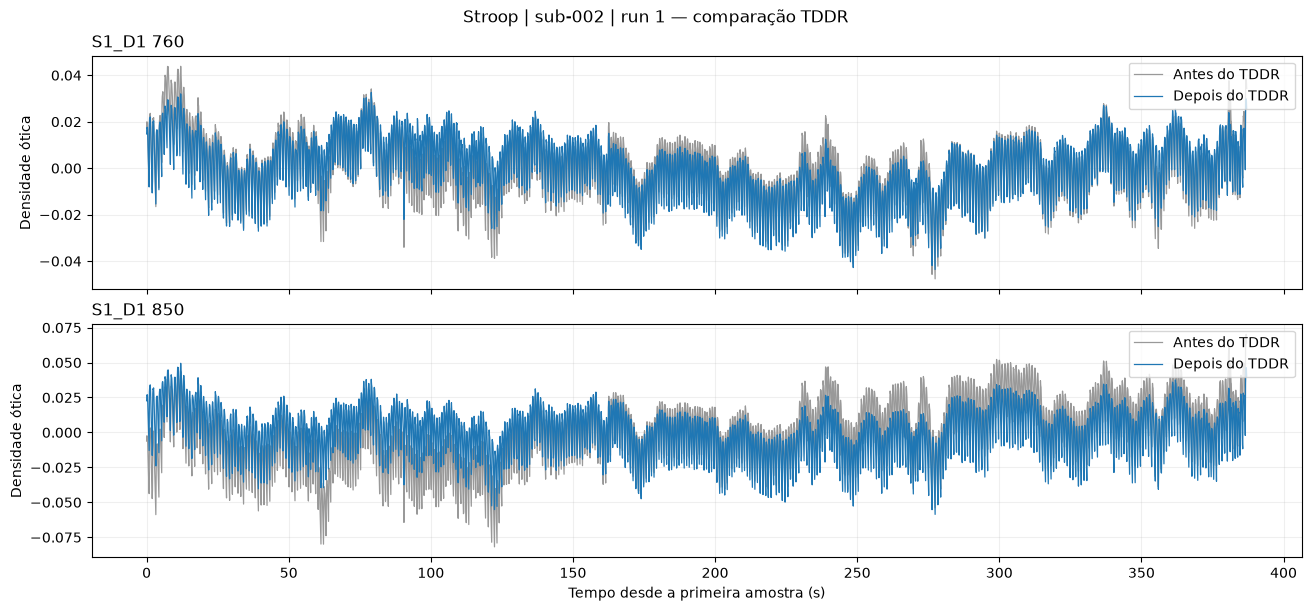

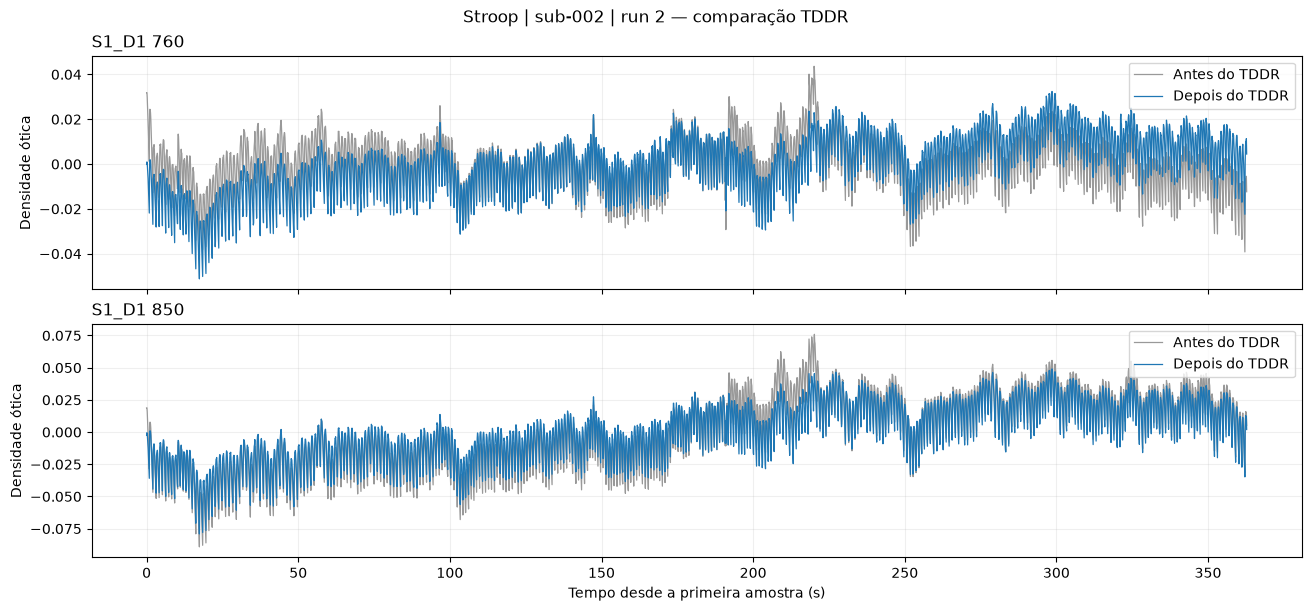


Sem SSR ou conversão para HbO/HbR. Nenhum ficheiro escrito.


In [12]:
import warnings

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from IPython.display import display

CHAVES_STROOP_05 = {
    ("sub-001", 1), ("sub-001", 2),
    ("sub-002", 1), ("sub-002", 2),
}

if (
    "piloto_stroop_od_qc" not in globals()
    or "piloto_stroop_sci_pares" not in globals()
):
    raise RuntimeError("Executa primeiro a célula Python da Etapa 4.")

if (
    set(piloto_stroop_od_qc) != CHAVES_STROOP_05
    or set(piloto_stroop_sci_pares) != CHAVES_STROOP_05
):
    raise RuntimeError("A Etapa 5 espera as quatro runs piloto de Stroop.")


def mesmas_anotacoes_05(a, b):
    return (
        a.orig_time == b.orig_time
        and np.array_equal(a.onset, b.onset)
        and np.array_equal(a.duration, b.duration)
        and np.array_equal(a.description, b.description)
        and list(a.ch_names) == list(b.ch_names)
    )


piloto_stroop_od_tddr = {}
longos_validos_05 = {}

for chave, tabela in sorted(piloto_stroop_sci_pares.items()):
    longos_validos_05[chave] = set(tabela.loc[
        tabela["tipo_distancia"].eq("longo") & tabela["valido"], "par"
    ])
    if not longos_validos_05[chave]:
        raise RuntimeError(f"{chave}: sem pares longos válidos. Rever a Etapa 4.")

comuns_05 = set.intersection(*longos_validos_05.values())
primeira_chave_05 = min(CHAVES_STROOP_05)
ordem_pares_05 = piloto_stroop_sci_pares[primeira_chave_05]["par"]

par_visualizacao_stroop_05 = next(
    (par for par in ordem_pares_05 if par in comuns_05),
    None,
)

temporario_05 = {}
registos_05 = []

for (sujeito, run), od in sorted(piloto_stroop_od_qc.items()):
    chave = (sujeito, run)
    etiqueta = f"{sujeito} | Stroop run {run}"
    print(f"A aplicar TDDR: {etiqueta}...", flush=True)

    if set(od.get_channel_types()) != {"fnirs_od"}:
        raise ValueError(f"{etiqueta}: esperava apenas séries de densidade ótica.")

    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        corrigido = (
            mne.preprocessing.nirs.temporal_derivative_distribution_repair(
                od.copy(), verbose=False
            )
        )

    estrutura_preservada = (
        corrigido.ch_names == od.ch_names
        and corrigido.get_channel_types() == od.get_channel_types()
        and corrigido.n_times == od.n_times
        and corrigido.first_samp == od.first_samp
        and corrigido.info["sfreq"] == od.info["sfreq"]
    )
    bads_preservados = corrigido.info["bads"] == od.info["bads"]
    anotacoes_preservadas = mesmas_anotacoes_05(
        corrigido.annotations, od.annotations
    )
    valores_finitos = bool(np.isfinite(corrigido.get_data()).all())

    registos_05.append({
        "sujeito": sujeito,
        "run": run,
        "n_series": len(corrigido.ch_names),
        "n_series_nao_marcadas": (
            len(corrigido.ch_names) - len(corrigido.info["bads"])
        ),
        "n_amostras": corrigido.n_times,
        "estrutura_preservada": estrutura_preservada,
        "bads_preservados": bads_preservados,
        "anotacoes_preservadas": anotacoes_preservadas,
        "valores_finitos": valores_finitos,
        "avisos_mne": " | ".join(dict.fromkeys(str(a.message) for a in avisos)),
    })

    if all((
        estrutura_preservada,
        bads_preservados,
        anotacoes_preservadas,
        valores_finitos,
    )):
        temporario_05[chave] = corrigido

df_stroop_05_resumo = pd.DataFrame(registos_05)

print("\nETAPA 5 — RESUMO DO TDDR")
print(df_stroop_05_resumo.to_string(index=False))

if set(temporario_05) != CHAVES_STROOP_05:
    raise RuntimeError("Nem todas as runs passaram as verificações. Revê o resumo.")

piloto_stroop_od_tddr = temporario_05

if par_visualizacao_stroop_05 is None:
    print("\nSem par longo válido comum às quatro runs; não será criada figura.")
else:
    print(f"\nPar longo escolhido para inspeção: {par_visualizacao_stroop_05}")

    for (sujeito, run), depois in sorted(piloto_stroop_od_tddr.items()):
        antes = piloto_stroop_od_qc[(sujeito, run)]
        indices = [
            i for i, nome in enumerate(antes.ch_names)
            if nome.split()[0] == par_visualizacao_stroop_05
        ]
        if len(indices) != 2:
            raise RuntimeError(f"{sujeito}, run {run}: o par não tem duas séries.")

        y_antes = antes.get_data(picks=indices)
        y_depois = depois.get_data(picks=indices)

        fig, eixos = plt.subplots(
            2, 1, figsize=(13, 6), sharex=True, layout="constrained"
        )
        for j, ax in enumerate(eixos):
            ax.plot(
                antes.times, y_antes[j], color="0.6",
                linewidth=0.9, label="Antes do TDDR",
            )
            ax.plot(
                depois.times, y_depois[j], color="tab:blue",
                linewidth=0.9, label="Depois do TDDR",
            )
            ax.set_title(antes.ch_names[indices[j]], loc="left")
            ax.set_ylabel("Densidade ótica")
            ax.grid(alpha=0.2)
            ax.legend(loc="upper right")

        eixos[-1].set_xlabel("Tempo desde a primeira amostra (s)")
        fig.suptitle(f"Stroop | {sujeito} | run {run} — comparação TDDR")
        display(fig)
        plt.close(fig)

print("\nSem SSR ou conversão para HbO/HbR. Nenhum ficheiro escrito.")

## Etapa 6 — Referência do piloto sem regressão de canais curtos (SSR)

### Objetivo
Criar uma versão de referência sem SSR para as quatro runs piloto
de Stroop, mantendo a mesma política de processamento em todas.

### Entradas
- `piloto_stroop_od_tddr`: sinais em densidade ótica após o TDDR.
- `piloto_stroop_sci_pares`: classificação dos pares na Etapa 4.

### Procedimento
1. Recuperar das tabelas SCI o número de pares curtos físicos
   e os IDs dos pares curtos elegíveis em cada run.
2. Verificar se cada par curto elegível continua representado
   por duas séries não marcadas como más após o TDDR.
3. Criar uma cópia do sinal pós-TDDR sem aplicar SSR, remover
   canais, alterar amostras ou modificar anotações.

### Saídas
- `piloto_stroop_od_pre_mbll`: quatro sinais de referência
  em memória, prontos para a conversão em HbO/HbR.
- `df_stroop_06_ssr`: disponibilidade de curtos e motivo
  para a não aplicação de SSR em cada run.

### Limites
Zero pares curtos elegíveis não significa ausência de pares
curtos na montagem. A versão sem SSR não demonstra que a
contribuição fisiológica superficial esteja controlada.
Nenhum ficheiro é escrito.

In [13]:
import numpy as np
import pandas as pd

CHAVES_STROOP_06 = {
    ("sub-001", 1), ("sub-001", 2),
    ("sub-002", 1), ("sub-002", 2),
}
POLITICA_SSR_STROOP = "referencia_comum_sem_SSR"

if (
    "piloto_stroop_od_tddr" not in globals()
    or "piloto_stroop_sci_pares" not in globals()
):
    raise RuntimeError(
        "Executa primeiro as células Python das Etapas 4 e 5."
    )

if (
    set(piloto_stroop_od_tddr) != CHAVES_STROOP_06
    or set(piloto_stroop_sci_pares) != CHAVES_STROOP_06
):
    raise RuntimeError("A Etapa 6 espera as quatro runs piloto de Stroop.")

piloto_stroop_od_pre_mbll = {}
copias_06 = {}
registos_06 = []

for (sujeito, run), entrada in sorted(piloto_stroop_od_tddr.items()):
    chave = (sujeito, run)
    etiqueta = f"{sujeito} | Stroop run {run}"
    tabela = piloto_stroop_sci_pares[chave]

    if set(entrada.get_channel_types()) != {"fnirs_od"}:
        raise ValueError(f"{etiqueta}: esperava apenas séries de densidade ótica.")

    curtos = tabela.loc[tabela["tipo_distancia"].eq("curto")]
    curtos_elegiveis = curtos.loc[curtos["valido"], "par"].tolist()
    bads = set(entrada.info["bads"])

    series_curtas_elegiveis = []
    for par in curtos_elegiveis:
        series_par = [
            nome for nome in entrada.ch_names
            if nome.split()[0] == par
        ]
        if len(series_par) != 2 or any(nome in bads for nome in series_par):
            raise RuntimeError(
                f"{etiqueta}: o par curto elegível {par} não tem "
                "duas séries não marcadas após o TDDR."
            )
        series_curtas_elegiveis.extend(series_par)

    saida = entrada.copy()
    a, b = entrada.annotations, saida.annotations

    estrutura_preservada = (
        saida.ch_names == entrada.ch_names
        and saida.get_channel_types() == entrada.get_channel_types()
        and saida.n_times == entrada.n_times
        and saida.first_samp == entrada.first_samp
        and saida.info["sfreq"] == entrada.info["sfreq"]
        and saida.info["bads"] == entrada.info["bads"]
    )
    anotacoes_preservadas = (
        a.orig_time == b.orig_time
        and np.array_equal(a.onset, b.onset)
        and np.array_equal(a.duration, b.duration)
        and np.array_equal(a.description, b.description)
        and list(a.ch_names) == list(b.ch_names)
    )
    sinal_preservado = np.array_equal(entrada.get_data(), saida.get_data())

    if not (estrutura_preservada and anotacoes_preservadas and sinal_preservado):
        raise RuntimeError(f"{etiqueta}: a cópia não preservou a entrada.")

    if curtos_elegiveis:
        motivo = "SSR não aplicada nesta referência, apesar de haver curtos elegíveis."
    elif curtos.empty:
        motivo = "Sem pares curtos pela geometria."
    else:
        motivo = "Existem pares curtos, mas nenhum é elegível pelo SCI."

    copias_06[chave] = saida
    registos_06.append({
        "sujeito": sujeito,
        "run": run,
        "politica": POLITICA_SSR_STROOP,
        "n_pares_curtos": len(curtos),
        "n_curtos_elegiveis": len(curtos_elegiveis),
        "pares_curtos_elegiveis": ", ".join(curtos_elegiveis) or "nenhum",
        "series_curtas_elegiveis": ", ".join(series_curtas_elegiveis) or "nenhuma",
        "SSR_aplicada": False,
        "sinal_preservado": sinal_preservado,
        "motivo": motivo,
    })

piloto_stroop_od_pre_mbll = copias_06
df_stroop_06_ssr = pd.DataFrame(registos_06)

print("ETAPA 6 — REFERÊNCIA DO STROOP SEM SSR")
print(df_stroop_06_ssr[[
    "sujeito", "run", "n_pares_curtos", "n_curtos_elegiveis",
    "pares_curtos_elegiveis", "SSR_aplicada", "sinal_preservado", "motivo",
]].to_string(index=False))

print("\nQuatro sinais de referência em piloto_stroop_od_pre_mbll.")
print("Nenhuma regressão executada. Nenhum ficheiro escrito.")

ETAPA 6 — REFERÊNCIA DO STROOP SEM SSR
sujeito  run  n_pares_curtos  n_curtos_elegiveis pares_curtos_elegiveis  SSR_aplicada  sinal_preservado                                                               motivo
sub-001    1               8                   0                 nenhum         False              True                Existem pares curtos, mas nenhum é elegível pelo SCI.
sub-001    2               8                   3 S5_D12, S6_D13, S8_D15         False              True SSR não aplicada nesta referência, apesar de haver curtos elegíveis.
sub-002    1               8                   0                 nenhum         False              True                Existem pares curtos, mas nenhum é elegível pelo SCI.
sub-002    2               8                   0                 nenhum         False              True                Existem pares curtos, mas nenhum é elegível pelo SCI.

Quatro sinais de referência em piloto_stroop_od_pre_mbll.
Nenhuma regressão executada. Nenhum f

## Etapa 7 — Conversão para HbO e HbR

### Objetivo
Converter a densidade ótica das quatro runs piloto de Stroop em
variações de concentração de oxi-hemoglobina (HbO) e
desoxi-hemoglobina (HbR), pela lei de Beer–Lambert modificada.

### Entrada e parâmetro
- `piloto_stroop_od_pre_mbll`: sinais pós-TDDR da referência sem SSR.
- `piloto_stroop_sci_pares`: tabela de pares e marcações da Etapa 4.
- Fator de percurso parcial (`ppf`): 6,0, igual ao piloto de DM.

### Verificações
1. Confirmar que cada par fonte–detetor passa a ter uma série HbO
   e uma série HbR e que os valores são finitos.
2. Confirmar que a grelha temporal e as anotações são preservadas.
3. Verificar que os pares marcados como maus em densidade ótica
   ficam marcados nos dois cromóforos, sem remover canais.
4. Confirmar que os pares longos válidos continuam disponíveis
   nos dois cromóforos, de acordo com a classificação pelo SCI.

### Saídas
- `piloto_stroop_haemo`: sinais HbO/HbR das quatro runs em memória.
- `df_stroop_07_resumo`: contagens e verificações por run.

### Limites
A conversão não reclassifica a qualidade dos pares. Não se aplica
SSR, não se filtra o sinal e não se ajusta um GLM.
Nenhum ficheiro é escrito.

In [15]:
import warnings

import mne
import numpy as np
import pandas as pd

CHAVES_STROOP_07 = {
    ("sub-001", 1), ("sub-001", 2),
    ("sub-002", 1), ("sub-002", 2),
}
PPF_STROOP_07 = 6.0

if (
    "piloto_stroop_od_pre_mbll" not in globals()
    or "piloto_stroop_sci_pares" not in globals()
):
    raise RuntimeError(
        "Faltam os sinais de referência da Etapa 6 ou as tabelas SCI da Etapa 4."
    )

if (
    set(piloto_stroop_od_pre_mbll) != CHAVES_STROOP_07
    or set(piloto_stroop_sci_pares) != CHAVES_STROOP_07
):
    raise RuntimeError("A Etapa 7 espera exatamente as quatro runs piloto de Stroop.")


def mesmas_anotacoes_07(a, b):
    return (
        a.orig_time == b.orig_time
        and np.array_equal(a.onset, b.onset)
        and np.array_equal(a.duration, b.duration)
        and np.array_equal(a.description, b.description)
        and list(a.ch_names) == list(b.ch_names)
    )


piloto_stroop_haemo = {}
temporario_07 = {}
registos_07 = []

for chave, od in sorted(piloto_stroop_od_pre_mbll.items()):
    sujeito, run = chave
    etiqueta = f"{sujeito} | Stroop run {run}"
    tabela = piloto_stroop_sci_pares[chave]
    print(f"A converter para HbO/HbR: {etiqueta}...", flush=True)

    if set(od.get_channel_types()) != {"fnirs_od"}:
        raise ValueError(f"{etiqueta}: esperava apenas séries de densidade ótica.")

    pares_esperados = set(tabela["par"])
    pares_od = {nome.split()[0] for nome in od.ch_names}
    if pares_od != pares_esperados:
        raise RuntimeError(f"{etiqueta}: os pares OD não coincidem com a tabela SCI.")

    pares_maus_sci = set(tabela.loc[~tabela["valido"], "par"])
    bads_od_esperados = {
        nome for nome in od.ch_names if nome.split()[0] in pares_maus_sci
    }
    if set(od.info["bads"]) != bads_od_esperados:
        raise RuntimeError(f"{etiqueta}: as marcações OD não coincidem com o SCI.")

    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        haemo = mne.preprocessing.nirs.beer_lambert_law(
            od.copy(), ppf=PPF_STROOP_07
        )

    nomes = haemo.ch_names
    tipos = haemo.get_channel_types()
    pares_por_tipo = {
        tipo: [nome.split()[0] for nome, t in zip(nomes, tipos) if t == tipo]
        for tipo in ("hbo", "hbr")
    }

    estrutura_pares_ok = (
        set(tipos) == {"hbo", "hbr"}
        and len(nomes) == len(od.ch_names)
        and all(
            len(pares) == len(pares_esperados) and set(pares) == pares_esperados
            for pares in pares_por_tipo.values()
        )
    )

    bads_haemo = set(haemo.info["bads"])
    bads_esperados = {
        nome for nome in nomes if nome.split()[0] in pares_maus_sci
    }
    bads_preservados = bads_haemo == bads_esperados

    grelha_preservada = (
        haemo.n_times == od.n_times
        and haemo.first_samp == od.first_samp
        and haemo.info["sfreq"] == od.info["sfreq"]
    )
    anotacoes_preservadas = mesmas_anotacoes_07(od.annotations, haemo.annotations)
    valores_finitos = bool(np.isfinite(haemo.get_data()).all())

    pares_longos = set(tabela.loc[tabela["tipo_distancia"].eq("longo"), "par"])
    longos_validos_sci = pares_longos - pares_maus_sci
    longos_haemo = {
        tipo: {
            nome.split()[0]
            for nome, t in zip(nomes, tipos)
            if t == tipo and nome not in bads_haemo
            and nome.split()[0] in pares_longos
        }
        for tipo in ("hbo", "hbr")
    }
    longos_ok = all(
        pares == longos_validos_sci for pares in longos_haemo.values()
    )

    passou = all((
        estrutura_pares_ok,
        bads_preservados,
        grelha_preservada,
        anotacoes_preservadas,
        valores_finitos,
        longos_ok,
    ))

    registos_07.append({
        "sujeito": sujeito,
        "run": run,
        "ppf": PPF_STROOP_07,
        "n_HbO": tipos.count("hbo"),
        "n_HbR": tipos.count("hbr"),
        "n_amostras": haemo.n_times,
        "n_longos_validos_HbO": len(longos_haemo["hbo"]),
        "n_longos_validos_HbR": len(longos_haemo["hbr"]),
        "estrutura_pares_ok": estrutura_pares_ok,
        "bads_preservados": bads_preservados,
        "grelha_preservada": grelha_preservada,
        "anotacoes_preservadas": anotacoes_preservadas,
        "valores_finitos": valores_finitos,
        "longos_ok": longos_ok,
        "estado": "convertida" if passou else "rever",
        "avisos_mne": " | ".join(dict.fromkeys(str(a.message) for a in avisos)),
    })

    if passou:
        temporario_07[chave] = haemo

df_stroop_07_resumo = pd.DataFrame(registos_07)

print("\nETAPA 7 — CONVERSÃO PARA HbO E HbR")
print(df_stroop_07_resumo.to_string(index=False))

if set(temporario_07) != CHAVES_STROOP_07:
    raise RuntimeError("Nem todas as runs passaram as verificações. Revê o resumo.")

piloto_stroop_haemo = temporario_07

print("\nQuatro sinais convertidos em memória: piloto_stroop_haemo.")
print("Sem SSR, filtragem ou GLM. Nenhum ficheiro escrito.")

A converter para HbO/HbR: sub-001 | Stroop run 1...
A converter para HbO/HbR: sub-001 | Stroop run 2...
A converter para HbO/HbR: sub-002 | Stroop run 1...
A converter para HbO/HbR: sub-002 | Stroop run 2...

ETAPA 7 — CONVERSÃO PARA HbO E HbR
sujeito  run  ppf  n_HbO  n_HbR  n_amostras  n_longos_validos_HbO  n_longos_validos_HbR  estrutura_pares_ok  bads_preservados  grelha_preservada  anotacoes_preservadas  valores_finitos  longos_ok     estado avisos_mne
sub-001    1  6.0     28     28        4000                    19                    19                True              True               True                   True             True       True convertida           
sub-001    2  6.0     28     28        3823                    19                    19                True              True               True                   True             True       True convertida           
sub-002    1  6.0     28     28        3938                    20                    20               

## Etapa 8 — Filtragem do sinal hemodinâmico

### Objetivo
Filtrar os sinais HbO e HbR das quatro runs piloto de Stroop,
com a mesma configuração usada na referência do piloto de DM.

### Entrada
`piloto_stroop_haemo`: sinais HbO/HbR da Etapa 7, obtidos
com PPF = 6,0 e sem regressão de canais curtos.

### Configuração
- Banda passante: 0,01–0,5 Hz.
- Método: IIR Butterworth, com `order=4`.
- Representação: secções de segunda ordem (`sos`).
- Fase: zero, com aplicação nos dois sentidos.
- Filtrar todas as séries, incluindo as marcadas como más,
  sem remover canais ou alterar as suas marcações.

### Verificações
Confirmar que os valores filtrados são finitos e que foram
preservados os canais, a grelha temporal, as anotações e as
marcações de qualidade. Registar eventuais avisos do MNE.

### Saídas
- `piloto_stroop_haemo_filtrado`: quatro sinais filtrados em memória.
- `df_stroop_08_resumo`: resultado das verificações por run.

### Limites
A filtragem não reclassifica canais nem define o modelo final.
Não se recorta o sinal, não se criam épocas, não se ajusta um
GLM e não se escrevem ficheiros.

In [16]:
import warnings

import numpy as np
import pandas as pd

CHAVES_STROOP_08 = {
    ("sub-001", 1), ("sub-001", 2),
    ("sub-002", 1), ("sub-002", 2),
}
BANDA_STROOP_08 = (0.01, 0.5)
IIR_STROOP_08 = {"order": 4, "ftype": "butter", "output": "sos"}

if "piloto_stroop_haemo" not in globals():
    raise RuntimeError("Falta a saída da Etapa 7: piloto_stroop_haemo.")

if set(piloto_stroop_haemo) != CHAVES_STROOP_08:
    raise RuntimeError("A Etapa 8 espera exatamente as quatro runs piloto de Stroop.")


def mesmas_anotacoes_08(a, b):
    return (
        a.orig_time == b.orig_time
        and np.array_equal(a.onset, b.onset)
        and np.array_equal(a.duration, b.duration)
        and np.array_equal(a.description, b.description)
        and list(a.ch_names) == list(b.ch_names)
    )


piloto_stroop_haemo_filtrado = {}
temporario_08 = {}
registos_08 = []

for chave, haemo in sorted(piloto_stroop_haemo.items()):
    sujeito, run = chave
    etiqueta = f"{sujeito} | Stroop run {run}"
    print(f"A filtrar HbO/HbR: {etiqueta}...", flush=True)

    linha = {"sujeito": sujeito, "run": run, "erro": ""}
    avisos = []

    try:
        tipos = haemo.get_channel_types()
        if set(tipos) != {"hbo", "hbr"}:
            raise ValueError("A entrada não contém apenas séries HbO e HbR.")

        # Índices explícitos para incluir também as séries marcadas como más.
        indices = np.arange(len(haemo.ch_names))

        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")
            filtrado = haemo.copy().filter(
                l_freq=BANDA_STROOP_08[0],
                h_freq=BANDA_STROOP_08[1],
                picks=indices,
                method="iir",
                iir_params=IIR_STROOP_08.copy(),
                phase="zero",
                verbose=False,
            )

        canais_preservados = (
            filtrado.ch_names == haemo.ch_names
            and filtrado.get_channel_types() == tipos
        )
        grelha_preservada = (
            filtrado.n_times == haemo.n_times
            and filtrado.first_samp == haemo.first_samp
            and filtrado.info["sfreq"] == haemo.info["sfreq"]
        )
        bads_preservados = filtrado.info["bads"] == haemo.info["bads"]
        anotacoes_preservadas = mesmas_anotacoes_08(
            haemo.annotations, filtrado.annotations
        )
        valores_finitos = bool(np.isfinite(filtrado.get_data()).all())

        passou = all((
            canais_preservados, grelha_preservada, bads_preservados,
            anotacoes_preservadas, valores_finitos,
        ))

        linha.update(
            n_HbO=tipos.count("hbo"),
            n_HbR=tipos.count("hbr"),
            n_amostras=filtrado.n_times,
            canais_preservados=canais_preservados,
            grelha_preservada=grelha_preservada,
            bads_preservados=bads_preservados,
            anotacoes_preservadas=anotacoes_preservadas,
            valores_finitos=valores_finitos,
            estado=(
                "filtrada_com_aviso" if passou and avisos
                else "filtrada" if passou
                else "rever"
            ),
        )

        if passou:
            temporario_08[chave] = filtrado

    except Exception as exc:
        linha["estado"] = "erro"
        linha["erro"] = f"{type(exc).__name__}: {exc}"

    linha["avisos_mne"] = " | ".join(
        dict.fromkeys(str(a.message) for a in avisos)
    )
    registos_08.append(linha)

df_stroop_08_resumo = pd.DataFrame(registos_08)

print("\nETAPA 8 — FILTRAGEM HEMODINÂMICA")
print("Banda: 0,01–0,5 Hz | IIR Butterworth | order=4 | SOS | fase zero")
print(df_stroop_08_resumo.fillna("").to_string(index=False))

if set(temporario_08) != CHAVES_STROOP_08:
    raise RuntimeError("Nem todas as runs passaram as verificações. Revê o resumo.")

piloto_stroop_haemo_filtrado = temporario_08
print("\nQuatro sinais filtrados em memória: piloto_stroop_haemo_filtrado.")
print("Sem recorte, épocas ou GLM. Nenhum ficheiro escrito.")

A filtrar HbO/HbR: sub-001 | Stroop run 1...
A filtrar HbO/HbR: sub-001 | Stroop run 2...
A filtrar HbO/HbR: sub-002 | Stroop run 1...
A filtrar HbO/HbR: sub-002 | Stroop run 2...

ETAPA 8 — FILTRAGEM HEMODINÂMICA
Banda: 0,01–0,5 Hz | IIR Butterworth | order=4 | SOS | fase zero
sujeito  run erro  n_HbO  n_HbR  n_amostras  canais_preservados  grelha_preservada  bads_preservados  anotacoes_preservadas  valores_finitos   estado avisos_mne
sub-001    1          28     28        4000                True               True              True                   True             True filtrada           
sub-001    2          28     28        3823                True               True              True                   True             True filtrada           
sub-002    1          28     28        3938                True               True              True                   True             True filtrada           
sub-002    2          28     28        3691                True              

ETAPA 8B — ANTES E DEPOIS DO FILTRO | S1_D1


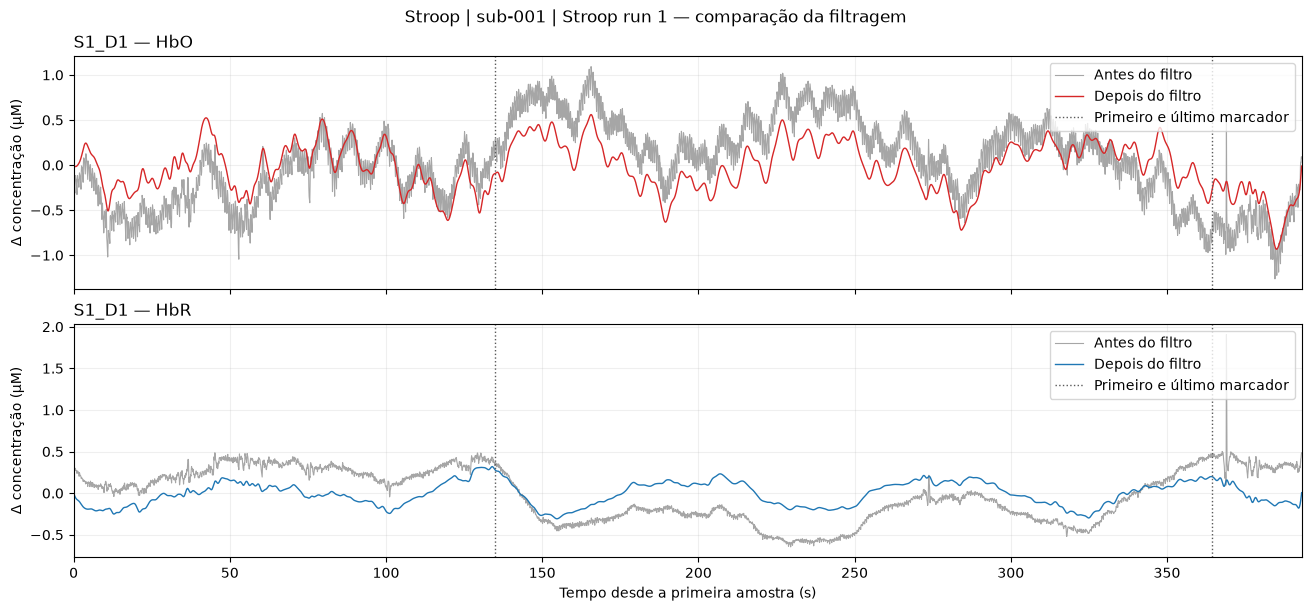

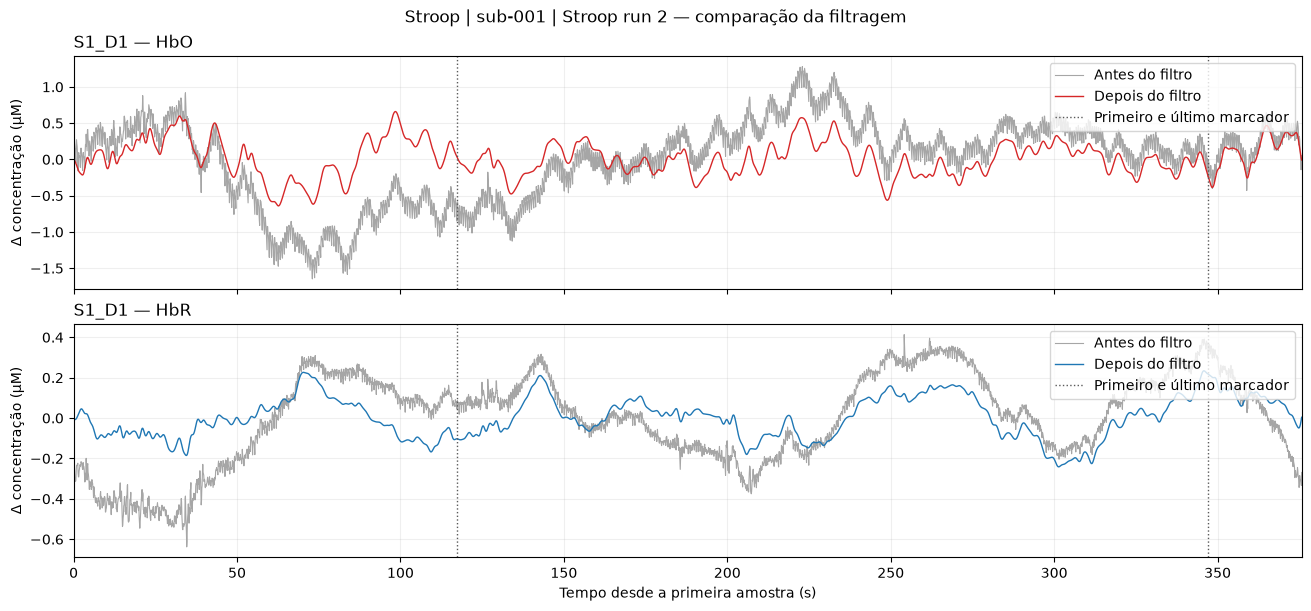

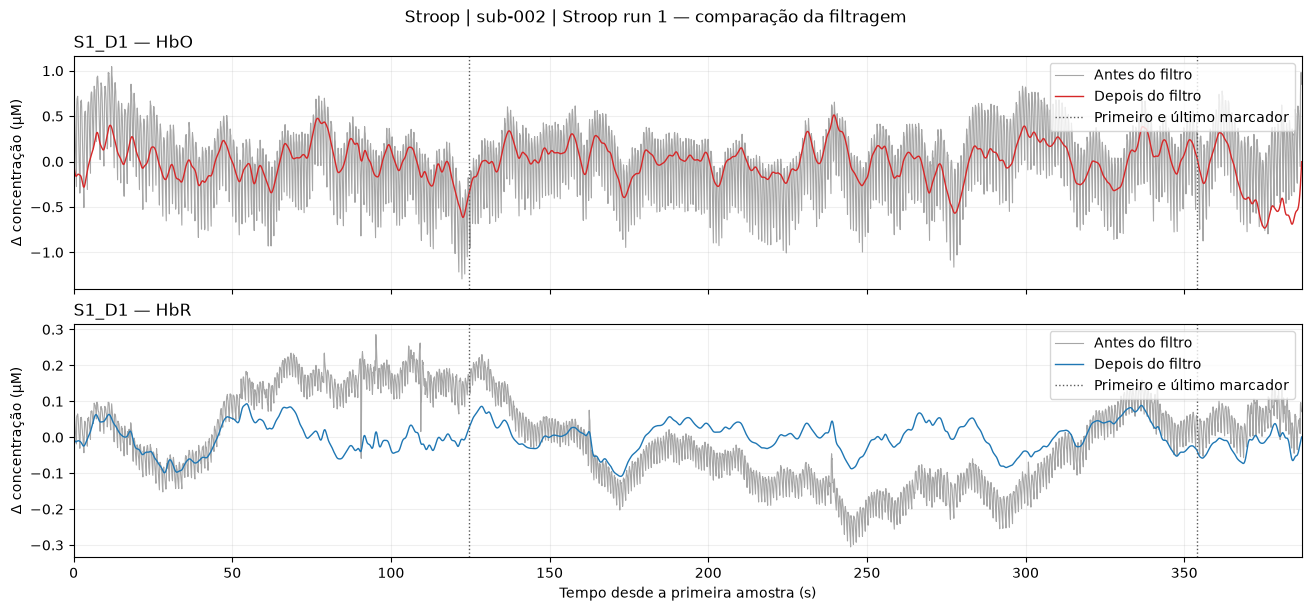

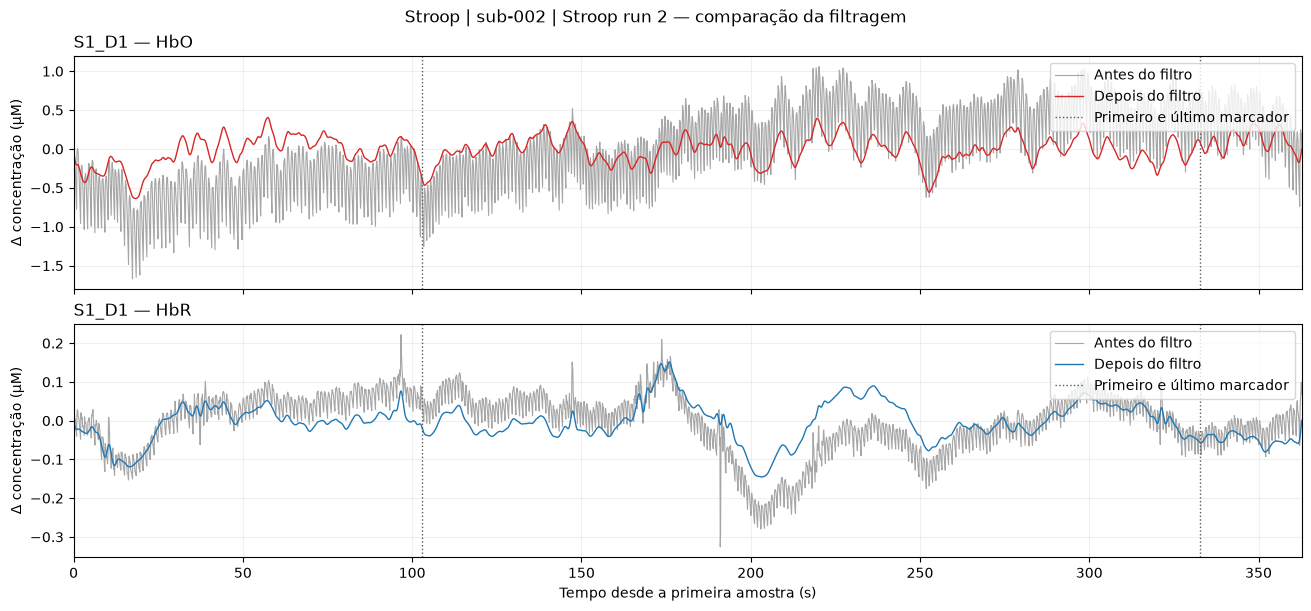

Quatro figuras apresentadas. Nenhum sinal ou ficheiro alterado.


In [18]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

if "piloto_stroop_haemo" not in globals():
    raise RuntimeError("Falta a saída da Etapa 7: piloto_stroop_haemo.")
if "piloto_stroop_haemo_filtrado" not in globals():
    raise RuntimeError("Falta a saída da Etapa 8: piloto_stroop_haemo_filtrado.")

CHAVES_08B = [
    ("sub-001", 1), ("sub-001", 2),
    ("sub-002", 1), ("sub-002", 2),
]

if (
    set(piloto_stroop_haemo) != set(CHAVES_08B)
    or set(piloto_stroop_haemo_filtrado) != set(CHAVES_08B)
):
    raise RuntimeError("A Etapa 8B precisa das quatro runs antes e depois do filtro.")

par_08b = globals().get("par_visualizacao_stroop_05")
if not par_08b:
    raise RuntimeError("Falta o par longo comum selecionado na Etapa 5.")

print(f"ETAPA 8B — ANTES E DEPOIS DO FILTRO | {par_08b}", flush=True)

for sujeito, run in CHAVES_08B:
    antes = piloto_stroop_haemo[(sujeito, run)]
    depois = piloto_stroop_haemo_filtrado[(sujeito, run)]
    etiqueta = f"{sujeito} | Stroop run {run}"
    nomes = [f"{par_08b} hbo", f"{par_08b} hbr"]

    for sinal in (antes, depois):
        if not all(nome in sinal.ch_names for nome in nomes):
            raise RuntimeError(f"{etiqueta}: faltam séries HbO/HbR de {par_08b}.")
        if any(nome in sinal.info["bads"] for nome in nomes):
            raise RuntimeError(f"{etiqueta}: {par_08b} está marcado como mau.")

    if (
        antes.n_times != depois.n_times
        or antes.first_samp != depois.first_samp
        or antes.info["sfreq"] != depois.info["sfreq"]
    ):
        raise RuntimeError(f"{etiqueta}: as grelhas temporais não coincidem.")

    tempos = antes.times
    dados_antes = antes.get_data(picks=nomes) * 1e6
    dados_depois = depois.get_data(picks=nomes) * 1e6

    marcadores = []
    for codigo, inicio in zip(
        antes.annotations.description,
        antes.annotations.onset,
    ):
        inicio_relativo = float(inicio - antes.first_time)
        if str(codigo).strip() in {"1", "2"} and 0 <= inicio_relativo <= tempos[-1]:
            marcadores.append(inicio_relativo)

    marcadores.sort()
    if len(marcadores) != 10:
        print(
            f"Aviso — {etiqueta}: {len(marcadores)} marcadores "
            "dentro da grelha; esperavam-se 10.",
            flush=True,
        )

    fig, eixos = plt.subplots(
        2, 1, figsize=(13, 6), sharex=True, layout="constrained"
    )

    for i, (ax, cromoforo, cor) in enumerate(
        zip(eixos, ("HbO", "HbR"), ("tab:red", "tab:blue"))
    ):
        ax.plot(
            tempos, dados_antes[i], color="0.65",
            linewidth=0.8, label="Antes do filtro",
        )
        ax.plot(
            tempos, dados_depois[i], color=cor,
            linewidth=1.0, label="Depois do filtro",
        )

        if marcadores:
            ax.axvline(
                marcadores[0], color="0.35", linestyle=":", linewidth=1,
                label="Primeiro e último marcador",
            )
            if len(marcadores) > 1:
                ax.axvline(
                    marcadores[-1], color="0.35", linestyle=":", linewidth=1
                )

        ax.set_title(f"{par_08b} — {cromoforo}", loc="left")
        ax.set_ylabel("Δ concentração (µM)")
        ax.grid(alpha=0.2)
        ax.legend(loc="upper right")

    eixos[-1].set_xlabel("Tempo desde a primeira amostra (s)")
    eixos[-1].set_xlim(0, tempos[-1])
    fig.suptitle(f"Stroop | {etiqueta} — comparação da filtragem")

    display(fig)
    plt.close(fig)

print("Quatro figuras apresentadas. Nenhum sinal ou ficheiro alterado.")

## Etapa 9 — Preparação dos eventos para o GLM de Stroop

### Objetivo
Preparar uma tabela de blocos por run e verificar se os eventos
auditados na Etapa 2 continuam a corresponder às anotações dos
sinais filtrados da Etapa 8.

### Entradas
- `df_stroop_02_eventos`: correspondência entre PsychoPy e SNIRF.
- `piloto_stroop_haemo_filtrado`: sinais contínuos HbO/HbR filtrados.

### Inícios, condições e durações
- Usar os inícios dos marcadores SNIRF, expressos em segundos
  desde a primeira amostra de cada run.
- Manter os códigos originais e as condições: `1` = Congruente;
  `2` = Incongruente.
- Referência provisória: usar a duração anotada no SNIRF (10 s).
- Sensibilidade à duração: usar o intervalo do primeiro estímulo
  ao início da rotina de repouso, medido no PsychoPy, mantendo
  os mesmos inícios SNIRF. Isto não representa o intervalo visual
  exato no relógio do fNIRS e não corrige o início dos eventos.

### Verificações e saídas
Confirmar dez blocos por run, cinco por condição, e verificar
que os eventos cabem na gravação e não se sobrepõem em nenhuma
das versões. Produzir uma tabela de auditoria, duas tabelas de
eventos candidatas e um resumo por run.

Não alterar anotações, alinhar relógios, recortar o sinal,
construir a matriz de desenho, ajustar o GLM ou escrever ficheiros.

In [19]:
import numpy as np
import pandas as pd

if "df_stroop_02_eventos" not in globals():
    raise RuntimeError("Falta a tabela de eventos da Etapa 2.")
if "piloto_stroop_haemo_filtrado" not in globals():
    raise RuntimeError("Faltam os sinais filtrados da Etapa 8.")

CHAVES_09 = [
    ("sub-001", 1), ("sub-001", 2),
    ("sub-002", 1), ("sub-002", 2),
]
CONDICOES_09 = {"1": "Congruente", "2": "Incongruente"}

if set(piloto_stroop_haemo_filtrado) != set(CHAVES_09):
    raise RuntimeError("Esperava exatamente as quatro runs filtradas do piloto.")

tabelas_09 = []
resumos_09 = []

for sujeito, run in CHAVES_09:
    etiqueta = f"{sujeito} | Stroop run {run}"
    raw = piloto_stroop_haemo_filtrado[(sujeito, run)]

    auditado = (
        df_stroop_02_eventos.loc[
            df_stroop_02_eventos["sujeito"].eq(sujeito)
            & df_stroop_02_eventos["run"].eq(run)
        ]
        .sort_values("bloco")
        .reset_index(drop=True)
    )

    codigos_raw = np.array(
        [str(c).strip() for c in raw.annotations.description], dtype=str
    )
    mascara = np.isin(codigos_raw, list(CONDICOES_09))
    codigos = codigos_raw[mascara]
    inicios_anotados = np.asarray(raw.annotations.onset[mascara], dtype=float)
    duracao_ref = np.asarray(raw.annotations.duration[mascara], dtype=float)

    if auditado["bloco"].tolist() != list(range(1, 11)) or len(codigos) != 10:
        raise ValueError(f"{etiqueta}: esperava dez blocos numerados de 1 a 10.")

    if pd.Series(codigos).value_counts().to_dict() != {"1": 5, "2": 5}:
        raise ValueError(f"{etiqueta}: esperava cinco blocos por condição.")

    if not np.array_equal(codigos, auditado["codigo"].astype(str).to_numpy()):
        raise ValueError(f"{etiqueta}: os códigos não coincidem com a Etapa 2.")

    if not (
        np.allclose(inicios_anotados, auditado["inicio_snirf_s"], atol=1e-6, rtol=0)
        and np.allclose(
            duracao_ref, auditado["duracao_anotada_s"], atol=1e-6, rtol=0
        )
    ):
        raise ValueError(f"{etiqueta}: os tempos SNIRF diferem da Etapa 2.")

    inicios = inicios_anotados - raw.first_time
    duracao_alt = auditado["estimulo_ate_repouso_s"].to_numpy(dtype=float)
    ultima_amostra = float(raw.times[-1])

    if (
        not np.isfinite(inicios).all()
        or (inicios < 0).any()
        or (np.diff(inicios) <= 0).any()
    ):
        raise ValueError(f"{etiqueta}: inícios inválidos ou fora de ordem.")

    for nome, duracoes in [
        ("referência SNIRF", duracao_ref),
        ("sensibilidade PsychoPy", duracao_alt),
    ]:
        if not np.isfinite(duracoes).all() or (duracoes <= 0).any():
            raise ValueError(f"{etiqueta}: durações inválidas em {nome}.")

        fins = inicios + duracoes
        if (fins > ultima_amostra).any():
            raise ValueError(f"{etiqueta}: um bloco ultrapassa a gravação em {nome}.")
        if (fins[:-1] > inicios[1:]).any():
            raise ValueError(f"{etiqueta}: há blocos sobrepostos em {nome}.")

    tabelas_09.append(pd.DataFrame({
        "sujeito": sujeito,
        "run": run,
        "bloco": auditado["bloco"],
        "codigo": codigos,
        "trial_type": [CONDICOES_09[c] for c in codigos],
        "onset": inicios,
        "duracao_snirf_s": duracao_ref,
        "duracao_estimulo_ate_repouso_s": duracao_alt,
    }))

    resumos_09.append({
        "sujeito": sujeito,
        "run": run,
        "n_blocos": len(codigos),
        "n_congruentes": int((codigos == "1").sum()),
        "n_incongruentes": int((codigos == "2").sum()),
        "primeiro_inicio_s": inicios[0],
        "ultimo_inicio_s": inicios[-1],
        "duracao_alt_min_s": duracao_alt.min(),
        "duracao_alt_max_s": duracao_alt.max(),
        "margem_apos_ultimo_bloco_alt_s": (
            ultima_amostra - (inicios[-1] + duracao_alt[-1])
        ),
    })

df_stroop_09_eventos = pd.concat(tabelas_09, ignore_index=True)
df_stroop_09_resumo = pd.DataFrame(resumos_09)

colunas_glm_09 = ["sujeito", "run", "onset", "duration", "trial_type"]

df_stroop_09_referencia = df_stroop_09_eventos.rename(
    columns={"duracao_snirf_s": "duration"}
)[colunas_glm_09].copy()

df_stroop_09_sensibilidade = df_stroop_09_eventos.rename(
    columns={"duracao_estimulo_ate_repouso_s": "duration"}
)[colunas_glm_09].copy()

print("ETAPA 9 — EVENTOS DO STROOP PARA O GLM")
print(f"Runs verificadas: {len(df_stroop_09_resumo)}")
print(f"Blocos preparados em cada versão: {len(df_stroop_09_eventos)}")
print("\nRESUMO POR RUN")
print(df_stroop_09_resumo.round(3).to_string(index=False))

print("\nPRIMEIROS BLOCOS — DUAS DURAÇÕES, MESMO INÍCIO")
print(df_stroop_09_eventos.head(6).round(3).to_string(index=False))

print("\nSem alterações às anotações, sem GLM e sem ficheiros escritos.")

ETAPA 9 — EVENTOS DO STROOP PARA O GLM
Runs verificadas: 4
Blocos preparados em cada versão: 40

RESUMO POR RUN
sujeito  run  n_blocos  n_congruentes  n_incongruentes  primeiro_inicio_s  ultimo_inicio_s  duracao_alt_min_s  duracao_alt_max_s  margem_apos_ultimo_bloco_alt_s
sub-001    1        10              5                5            134.758          364.345             10.507             10.720                          18.053
sub-001    2        10              5                5            117.346          346.933             10.525             10.719                          18.124
sub-002    1        10              5                5            124.501          354.099             10.498             10.642                          22.282
sub-002    2        10              5                5            103.020          332.612             10.515             10.626                          19.518

PRIMEIROS BLOCOS — DUAS DURAÇÕES, MESMO INÍCIO
sujeito  run  bloco codigo   trial_

## Etapa 10 — Matrizes de desenho do GLM de Stroop

### Objetivo
Construir e inspecionar duas matrizes de desenho por run,
alterando apenas a duração dos blocos.

### Entradas
- `piloto_stroop_haemo_filtrado`: grelha temporal das quatro runs.
- `df_stroop_09_referencia`: eventos com 10 s anotados no SNIRF.
- `df_stroop_09_sensibilidade`: mesmos eventos, com a duração
  do primeiro estímulo ao início da rotina de repouso no PsychoPy.

### Configuração provisória
- Um regressor para Congruente e outro para Incongruente,
  construídos com a função de resposta hemodinâmica de Glover.
- Uma constante por run; sem termos adicionais de deriva nesta
  inspeção inicial.
- Uma linha por amostra, na grelha do sinal filtrado.

### Verificações e visualização
Confirmar que as matrizes têm valores finitos, as três colunas
esperadas e posto completo: nenhuma coluna pode ser reproduzida
exatamente pelas restantes. Registar a correlação entre os
regressores de tarefa e comparar visualmente as duas durações.

### Saídas
- `piloto_stroop_matrizes_10`: matrizes por `(sujeito, run)` e versão.
- `df_stroop_10_resumo`: diagnósticos por run e versão.
- Quatro figuras, uma por run, com as duas versões sobrepostas
  em painéis separados para Congruente e Incongruente.

### Limites
Nesta etapa inspecionamos os regressores antes de qualquer
filtragem da matriz. A compatibilidade com o filtro da Etapa 8
e o tratamento da autocorrelação residual ficam para a modelação.
Não se ajusta o GLM, não se estimam betas ou contrastes e não
se escrevem ficheiros.

A construir matrizes: sub-001 | Stroop run 1...
A construir matrizes: sub-001 | Stroop run 2...
A construir matrizes: sub-002 | Stroop run 1...
A construir matrizes: sub-002 | Stroop run 2...

ETAPA 10 — MATRIZES DE DESENHO
sujeito  run        versao  n_amostras  n_colunas  posto  corr_entre_condicoes avisos
sub-001    1    referencia        4000          3      3               -0.0776       
sub-001    1 sensibilidade        4000          3      3               -0.0846       
sub-001    2    referencia        3823          3      3               -0.0823       
sub-001    2 sensibilidade        3823          3      3               -0.0900       
sub-002    1    referencia        3938          3      3               -0.0793       
sub-002    1 sensibilidade        3938          3      3               -0.0860       
sub-002    2    referencia        3691          3      3               -0.0857       
sub-002    2 sensibilidade        3691          3      3               -0.0933       


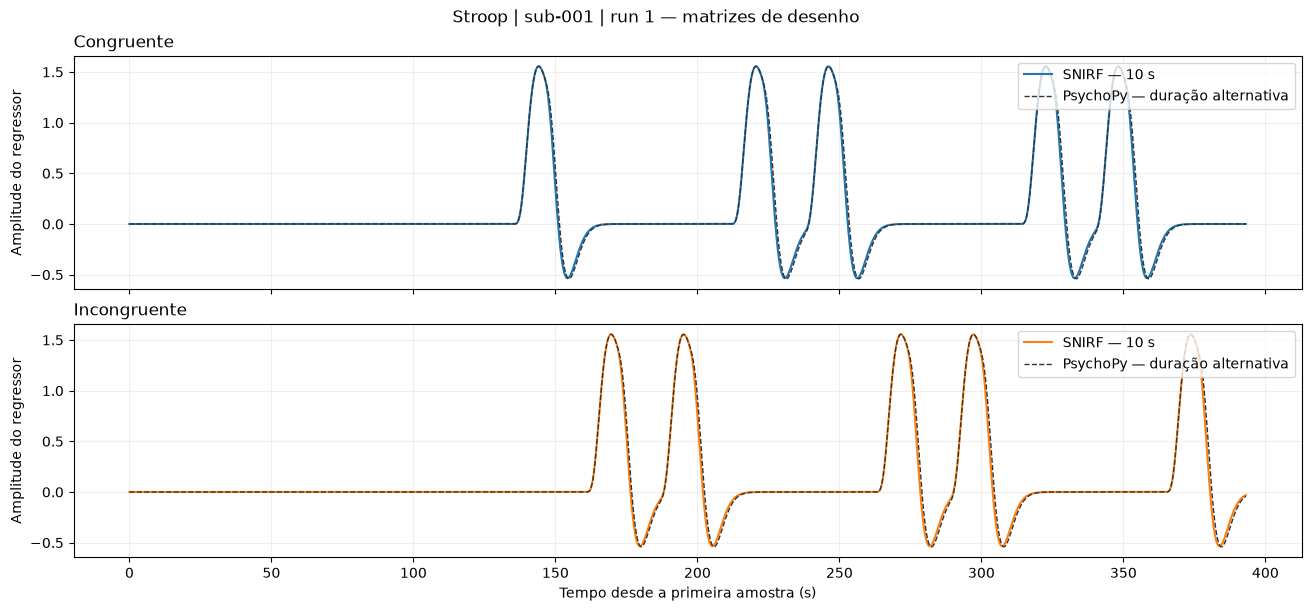

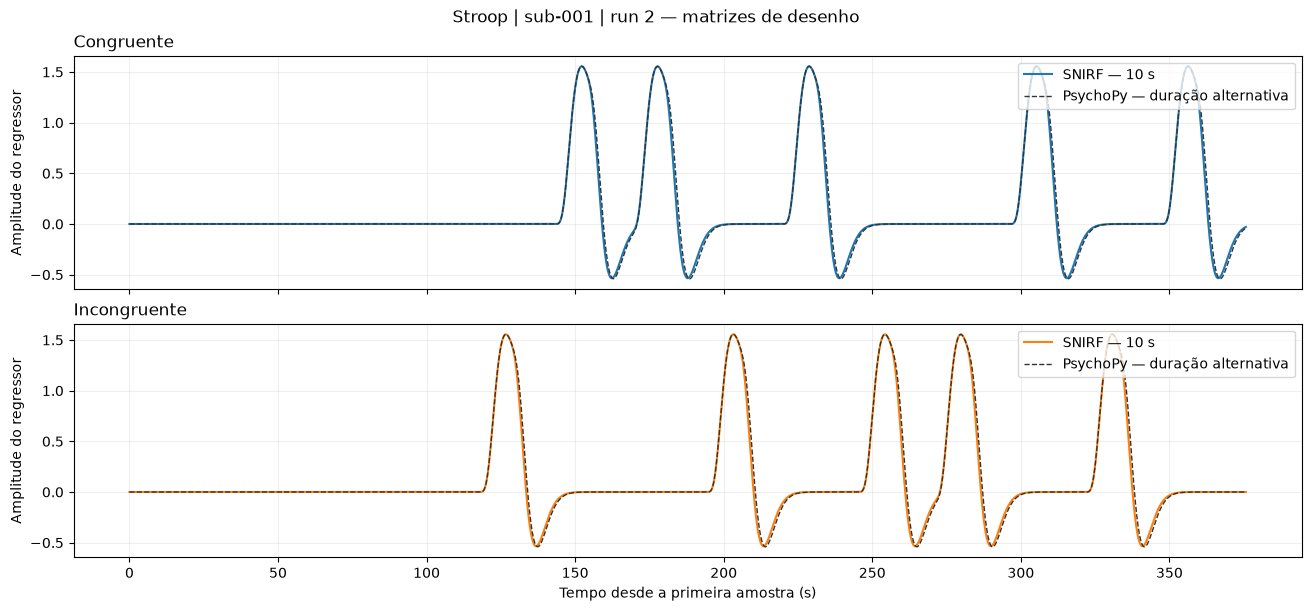

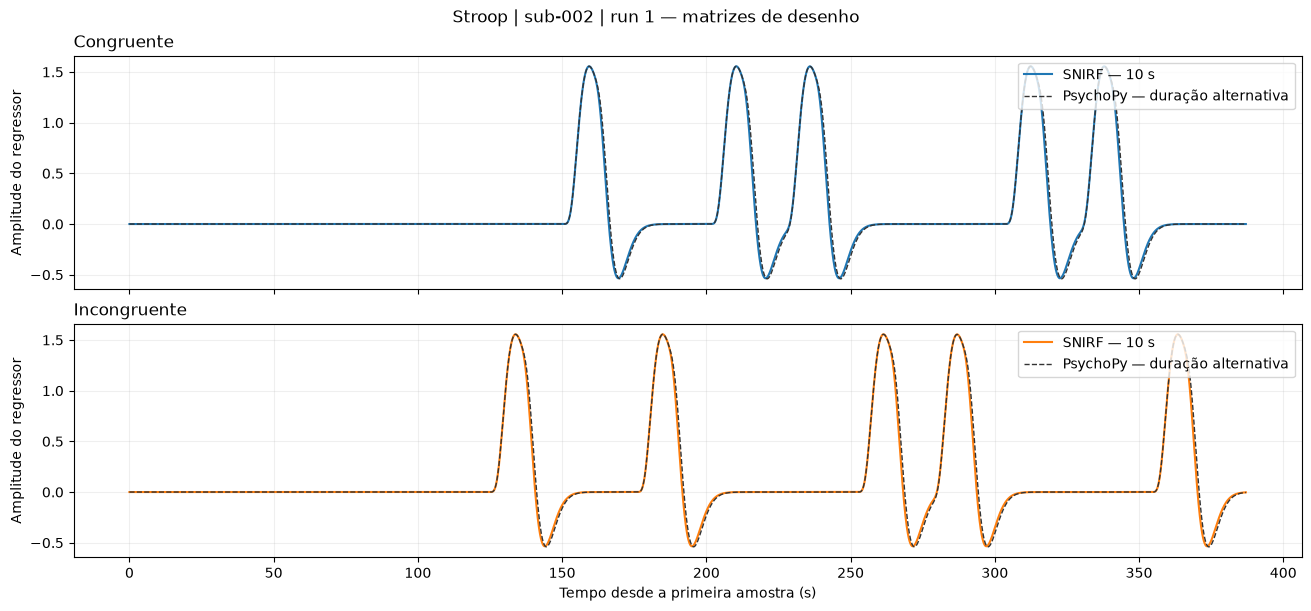

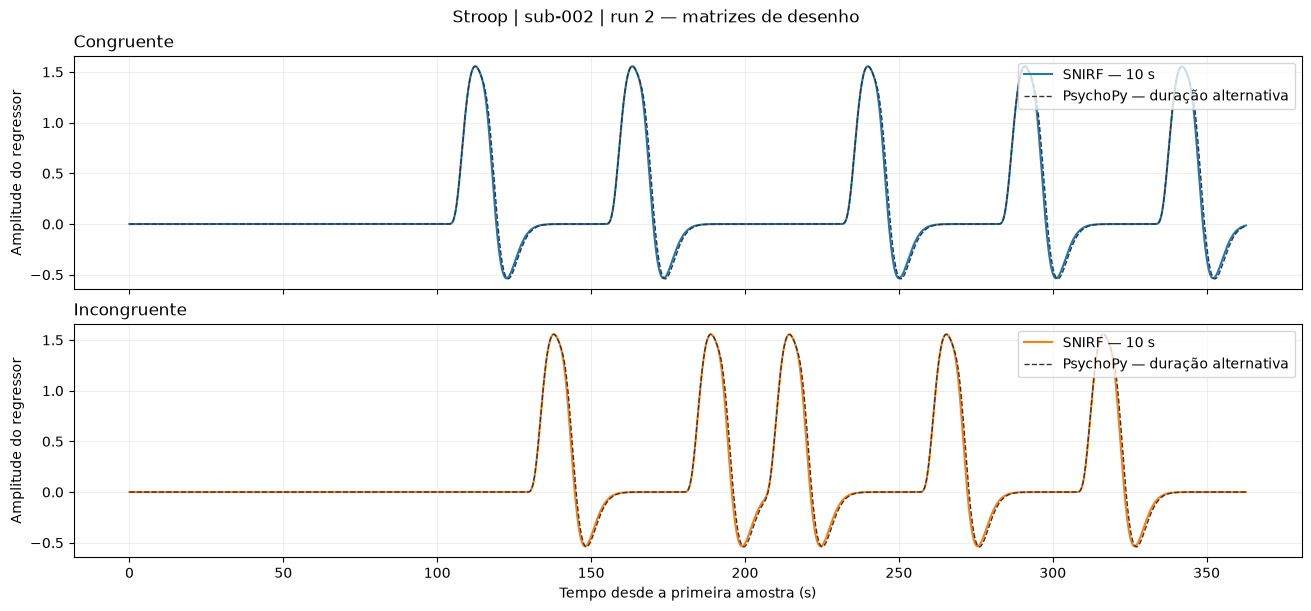


Oito matrizes construídas. Nenhum GLM ajustado ou ficheiro escrito.


In [20]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from nilearn.glm.first_level import make_first_level_design_matrix

necessarias_10 = (
    "piloto_stroop_haemo_filtrado",
    "df_stroop_09_referencia",
    "df_stroop_09_sensibilidade",
)
faltam_10 = [nome for nome in necessarias_10 if nome not in globals()]
if faltam_10:
    raise RuntimeError(f"Faltam saídas das etapas anteriores: {faltam_10}")

CHAVES_10 = {
    ("sub-001", 1), ("sub-001", 2),
    ("sub-002", 1), ("sub-002", 2),
}
COLUNAS_10 = ["Congruente", "Incongruente", "constant"]

if set(piloto_stroop_haemo_filtrado) != CHAVES_10:
    raise RuntimeError("A Etapa 10 espera as quatro runs piloto de Stroop.")

piloto_stroop_matrizes_10 = {}
matrizes_10 = {}
registos_10 = []

for chave, raw in sorted(piloto_stroop_haemo_filtrado.items()):
    sujeito, run = chave
    etiqueta = f"{sujeito} | Stroop run {run}"
    tempos = raw.times
    versoes = {}
    matrizes_10[chave] = {}

    print(f"A construir matrizes: {etiqueta}...", flush=True)

    for versao, tabela in (
        ("referencia", df_stroop_09_referencia),
        ("sensibilidade", df_stroop_09_sensibilidade),
    ):
        eventos = (
            tabela.loc[
                tabela["sujeito"].eq(sujeito) & tabela["run"].eq(run),
                ["onset", "duration", "trial_type"],
            ]
            .sort_values("onset")
            .reset_index(drop=True)
        )
        if eventos["trial_type"].value_counts().to_dict() != {
            "Congruente": 5, "Incongruente": 5
        }:
            raise ValueError(f"{etiqueta} / {versao}: contagens inesperadas.")

        versoes[versao] = eventos

    fixas = ["onset", "trial_type"]
    if not versoes["referencia"][fixas].equals(versoes["sensibilidade"][fixas]):
        raise RuntimeError(f"{etiqueta}: as versões diferem nos inícios ou condições.")

    for versao, eventos in versoes.items():
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")
            matriz = make_first_level_design_matrix(
                frame_times=tempos,
                events=eventos,
                hrf_model="glover",
                drift_model=None,
            )

        if (
            set(matriz.columns) != set(COLUNAS_10)
            or matriz.shape != (raw.n_times, len(COLUNAS_10))
            or not np.array_equal(matriz.index.to_numpy(), tempos)
        ):
            raise RuntimeError(f"{etiqueta} / {versao}: estrutura inesperada.")

        matriz = matriz[COLUNAS_10].copy()
        x = matriz.to_numpy(dtype=float)
        if not np.isfinite(x).all():
            raise ValueError(f"{etiqueta} / {versao}: valores não finitos.")

        posto = int(np.linalg.matrix_rank(x))
        if posto != len(COLUNAS_10):
            raise RuntimeError(f"{etiqueta} / {versao}: matriz sem posto completo.")
        if not np.allclose(x[:, 2], 1.0, rtol=0, atol=1e-12):
            raise RuntimeError(f"{etiqueta} / {versao}: constante inesperada.")

        matrizes_10[chave][versao] = matriz
        registos_10.append({
            "sujeito": sujeito,
            "run": run,
            "versao": versao,
            "n_amostras": matriz.shape[0],
            "n_colunas": matriz.shape[1],
            "posto": posto,
            "corr_entre_condicoes": float(np.corrcoef(x[:, 0], x[:, 1])[0, 1]),
            "avisos": " | ".join(dict.fromkeys(str(a.message) for a in avisos)),
        })

piloto_stroop_matrizes_10 = matrizes_10
df_stroop_10_resumo = pd.DataFrame(registos_10)

print("\nETAPA 10 — MATRIZES DE DESENHO")
print(df_stroop_10_resumo.round(4).to_string(index=False))

for (sujeito, run), versoes in sorted(piloto_stroop_matrizes_10.items()):
    ref = versoes["referencia"]
    alt = versoes["sensibilidade"]

    fig, eixos = plt.subplots(
        2, 1, figsize=(13, 6), sharex=True, sharey=True, layout="constrained"
    )
    for ax, condicao, cor in zip(eixos, COLUNAS_10[:2], ("tab:blue", "tab:orange")):
        ax.plot(ref.index, ref[condicao], color=cor, label="SNIRF — 10 s")
        ax.plot(
            alt.index, alt[condicao], color="0.2", linestyle="--",
            linewidth=1, label="PsychoPy — duração alternativa",
        )
        ax.set_title(condicao, loc="left")
        ax.set_ylabel("Amplitude do regressor")
        ax.grid(alpha=0.2)
        ax.legend(loc="upper right")

    eixos[-1].set_xlabel("Tempo desde a primeira amostra (s)")
    fig.suptitle(f"Stroop | {sujeito} | run {run} — matrizes de desenho")
    display(fig)
    plt.close(fig)

print("\nOito matrizes construídas. Nenhum GLM ajustado ou ficheiro escrito.")

## Etapa 11 — Compatibilização temporal das matrizes com o sinal filtrado

### Objetivo
Preparar as matrizes de desenho para ajustar o GLM aos sinais
HbO/HbR filtrados, mantendo a comparação entre as duas durações.

### Entradas
- `piloto_stroop_haemo_filtrado`: sinais da Etapa 8.
- `piloto_stroop_matrizes_10`: matrizes não filtradas da Etapa 10.
- `BANDA_STROOP_08` e `IIR_STROOP_08`: configuração do filtro da Etapa 8.

### Procedimento
1. Confirmar que cada matriz usa a grelha temporal da respetiva run
   e que não há anotações que dividam a filtragem em segmentos.
2. Aplicar aos regressores Congruente e Incongruente o mesmo
   filtro IIR Butterworth de 0,01–0,5 Hz, em SOS e fase zero.
3. Preservar a constante e as matrizes originais.
4. Verificar valores finitos, posto completo e correlação entre
   os regressores após a filtragem.
5. Mostrar uma figura por run, comparando antes e depois do
   filtro na versão de referência.

### Saídas
- `piloto_stroop_matrizes_11`: matrizes filtradas por run e versão.
- `df_stroop_11_resumo`: diagnósticos das oito matrizes.

### Limites
Não se volta a filtrar o HbO/HbR. Não se ajusta o GLM, não se
estimam betas e não se escrevem ficheiros. Esta etapa não trata
a autocorrelação dos resíduos.

A filtrar os regressores: sub-001 | Stroop run 1...
A filtrar os regressores: sub-001 | Stroop run 2...
A filtrar os regressores: sub-002 | Stroop run 1...
A filtrar os regressores: sub-002 | Stroop run 2...

ETAPA 11 — DIAGNÓSTICOS DAS MATRIZES FILTRADAS
sujeito  run        versao  n_amostras  posto  corr_antes  corr_depois avisos
sub-001    1    referencia        4000      3     -0.0776      -0.0394       
sub-001    1 sensibilidade        4000      3     -0.0846      -0.0449       
sub-001    2    referencia        3823      3     -0.0823      -0.0943       
sub-001    2 sensibilidade        3823      3     -0.0900      -0.1041       
sub-002    1    referencia        3938      3     -0.0793      -0.0628       
sub-002    1 sensibilidade        3938      3     -0.0860      -0.0694       
sub-002    2    referencia        3691      3     -0.0857      -0.1078       
sub-002    2 sensibilidade        3691      3     -0.0933      -0.1178       


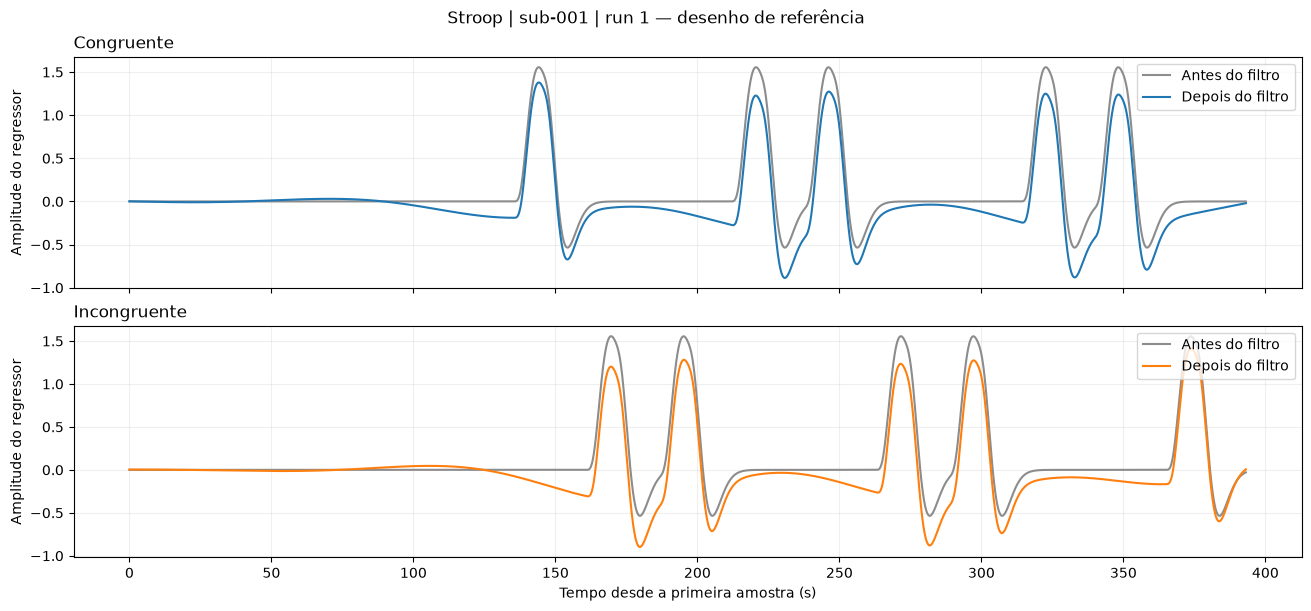

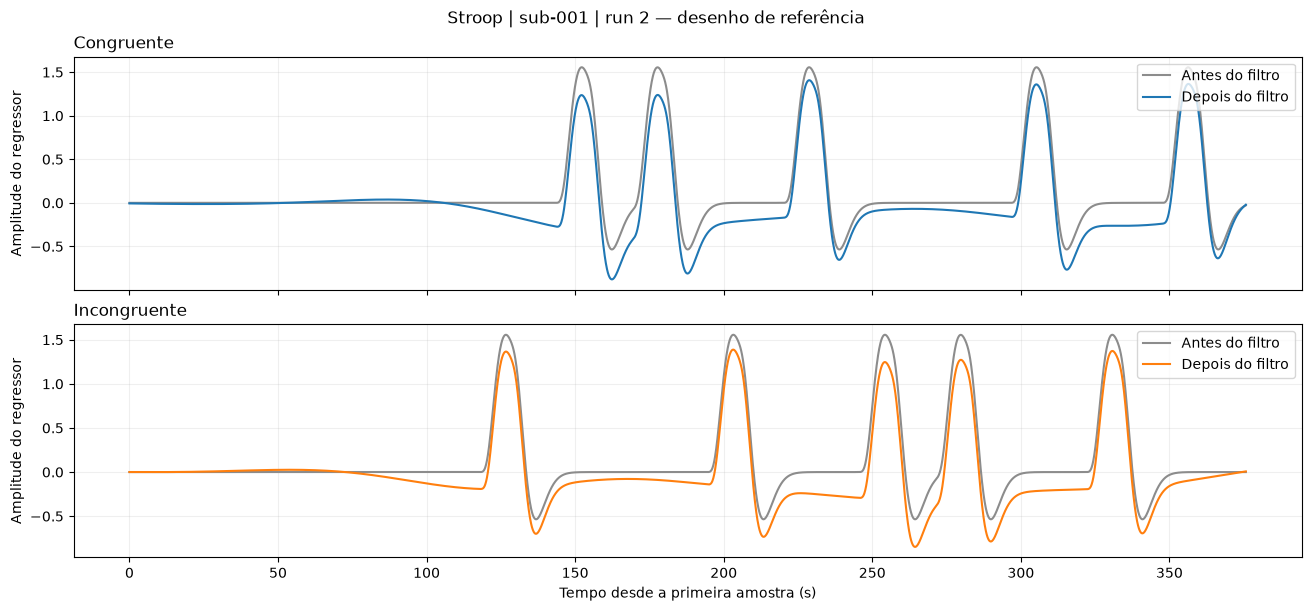

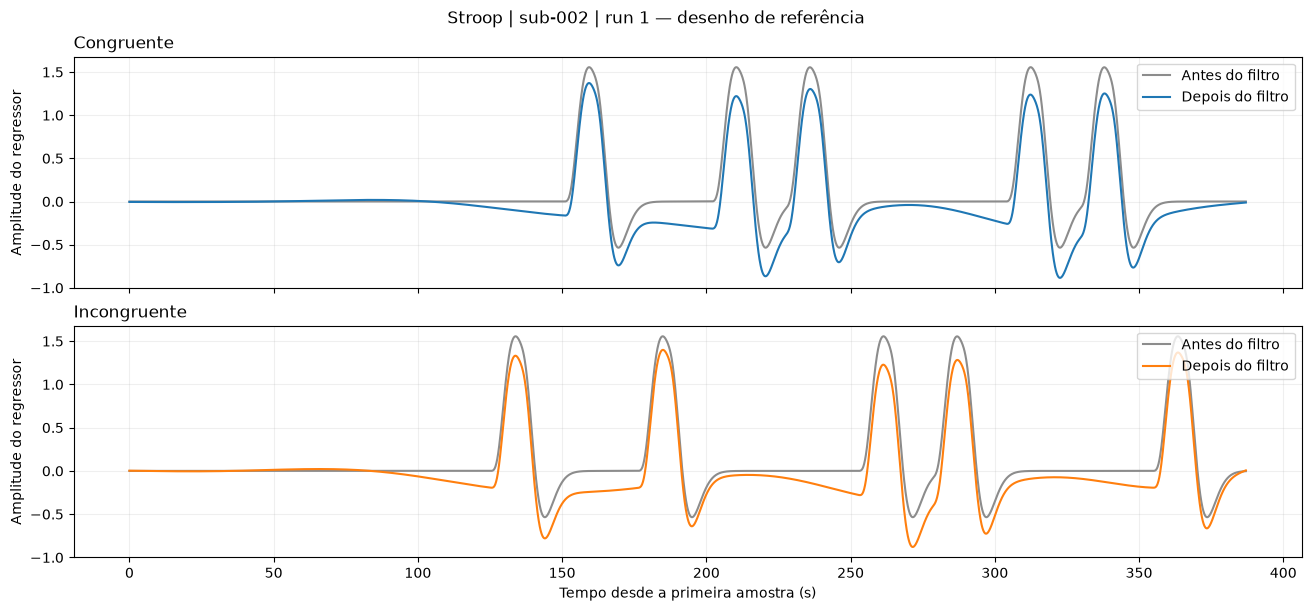

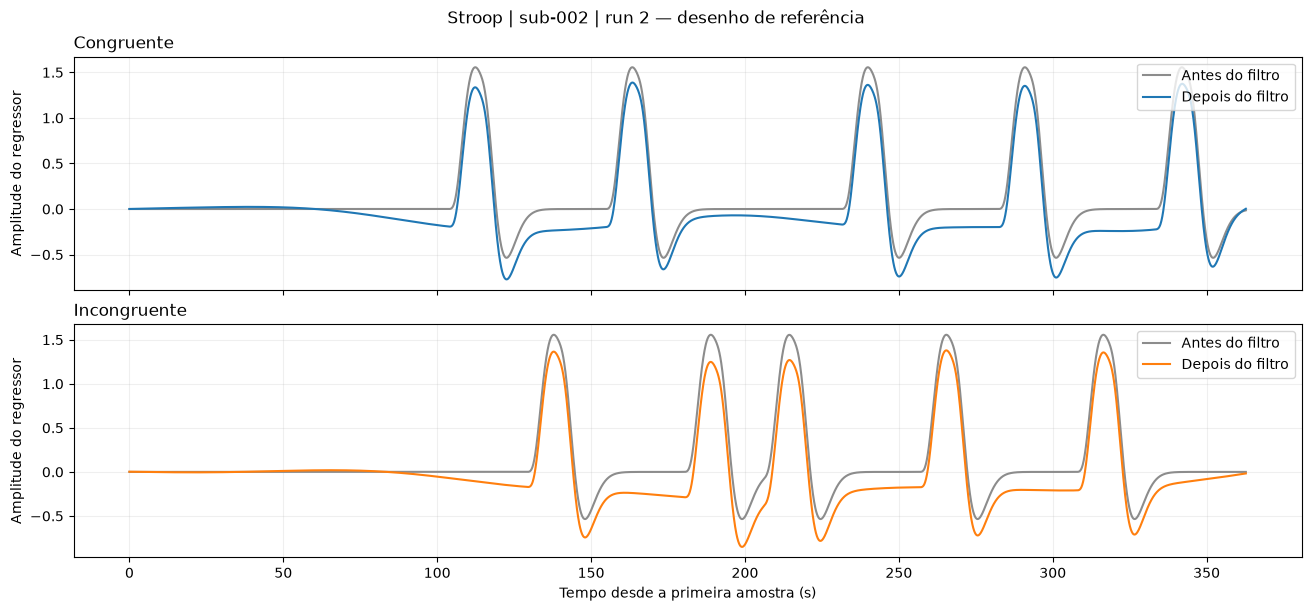


Oito matrizes preparadas. Nenhum GLM ajustado ou ficheiro escrito.


In [21]:
import warnings

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from IPython.display import display

necessarias_11 = (
    "piloto_stroop_haemo_filtrado",
    "piloto_stroop_matrizes_10",
    "BANDA_STROOP_08",
    "IIR_STROOP_08",
)
faltam_11 = [nome for nome in necessarias_11 if nome not in globals()]
if faltam_11:
    raise RuntimeError(f"Faltam saídas das Etapas 8 ou 10: {faltam_11}")

CHAVES_11 = {
    ("sub-001", 1), ("sub-001", 2),
    ("sub-002", 1), ("sub-002", 2),
}
TAREFA_11 = ["Congruente", "Incongruente"]
COLUNAS_11 = TAREFA_11 + ["constant"]
VERSOES_11 = ("referencia", "sensibilidade")

if (
    set(piloto_stroop_haemo_filtrado) != CHAVES_11
    or set(piloto_stroop_matrizes_10) != CHAVES_11
):
    raise RuntimeError("A Etapa 11 espera as quatro runs piloto de Stroop.")

piloto_stroop_matrizes_11 = {}
temporario_11 = {}
registos_11 = []

for chave, raw in sorted(piloto_stroop_haemo_filtrado.items()):
    sujeito, run = chave
    etiqueta = f"{sujeito} | Stroop run {run}"
    print(f"A filtrar os regressores: {etiqueta}...", flush=True)

    # A Etapa 8 usou a configuração predefinida de Raw.filter
    # para anotações que separam segmentos de filtragem.
    separadores = [
        str(desc) for desc in raw.annotations.description
        if str(desc).casefold().startswith(("edge", "bad_acq_skip"))
    ]
    if separadores:
        raise RuntimeError(
            f"{etiqueta}: há anotações que podem dividir a filtragem "
            f"em segmentos: {separadores}. Rever antes de avançar."
        )

    originais = piloto_stroop_matrizes_10[chave]
    if set(originais) != set(VERSOES_11):
        raise RuntimeError(f"{etiqueta}: faltam versões do desenho.")

    temporario_11[chave] = {}

    for versao in VERSOES_11:
        original = originais[versao]
        if (
            list(original.columns) != COLUNAS_11
            or not np.array_equal(original.index.to_numpy(), raw.times)
        ):
            raise RuntimeError(f"{etiqueta} / {versao}: matriz ou grelha inesperada.")

        x_tarefa = original[TAREFA_11].to_numpy(dtype=float, copy=True).T

        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")
            x_filtrado = mne.filter.filter_data(
                x_tarefa,
                sfreq=float(raw.info["sfreq"]),
                l_freq=BANDA_STROOP_08[0],
                h_freq=BANDA_STROOP_08[1],
                method="iir",
                iir_params=IIR_STROOP_08.copy(),
                phase="zero",
                verbose=False,
            )

        matriz = original.copy()
        matriz[TAREFA_11] = x_filtrado.T

        x = matriz.to_numpy(dtype=float)
        if not np.isfinite(x).all():
            raise ValueError(f"{etiqueta} / {versao}: valores não finitos.")
        if not np.array_equal(
            matriz["constant"].to_numpy(), original["constant"].to_numpy()
        ):
            raise RuntimeError(f"{etiqueta} / {versao}: a constante mudou.")

        posto = int(np.linalg.matrix_rank(x))
        if posto != len(COLUNAS_11):
            raise RuntimeError(f"{etiqueta} / {versao}: posto inesperado ({posto}).")

        temporario_11[chave][versao] = matriz
        registos_11.append({
            "sujeito": sujeito,
            "run": run,
            "versao": versao,
            "n_amostras": len(matriz),
            "posto": posto,
            "corr_antes": original[TAREFA_11].corr().iloc[0, 1],
            "corr_depois": matriz[TAREFA_11].corr().iloc[0, 1],
            "avisos": " | ".join(dict.fromkeys(str(a.message) for a in avisos)),
        })

piloto_stroop_matrizes_11 = temporario_11
df_stroop_11_resumo = pd.DataFrame(registos_11)

print("\nETAPA 11 — DIAGNÓSTICOS DAS MATRIZES FILTRADAS")
print(df_stroop_11_resumo.round(4).to_string(index=False))

for (sujeito, run), versoes in sorted(piloto_stroop_matrizes_11.items()):
    antes = piloto_stroop_matrizes_10[(sujeito, run)]["referencia"]
    depois = versoes["referencia"]

    fig, eixos = plt.subplots(
        2, 1, figsize=(13, 6), sharex=True, layout="constrained"
    )
    for ax, condicao, cor in zip(eixos, TAREFA_11, ("tab:blue", "tab:orange")):
        ax.plot(antes.index, antes[condicao], color="0.55", label="Antes do filtro")
        ax.plot(depois.index, depois[condicao], color=cor, label="Depois do filtro")
        ax.set_title(condicao, loc="left")
        ax.set_ylabel("Amplitude do regressor")
        ax.grid(alpha=0.2)
        ax.legend(loc="upper right")

    eixos[-1].set_xlabel("Tempo desde a primeira amostra (s)")
    fig.suptitle(f"Stroop | {sujeito} | run {run} — desenho de referência")
    display(fig)
    plt.close(fig)

print("\nOito matrizes preparadas. Nenhum GLM ajustado ou ficheiro escrito.")

## Etapa 12 — GLM exploratório e diagnóstico dos resíduos

### Objetivo
Ajustar um primeiro GLM aos canais longos válidos das quatro
runs piloto de Stroop e verificar a sensibilidade do contraste
Incongruente menos Congruente à duração atribuída aos blocos.

### Entradas
- `piloto_stroop_haemo_filtrado`: sinais HbO/HbR da Etapa 8.
- `piloto_stroop_matrizes_11`: matrizes com regressores filtrados.
- `piloto_stroop_sci_pares`: classificação dos pares na Etapa 4.

### Procedimento
1. Selecionar os pares longos válidos pelo SCI e confirmar
   que os dois cromóforos continuam disponíveis.
2. Ajustar separadamente por run as versões de referência
   (10 s anotados) e de sensibilidade (duração do PsychoPy),
   usando as mesmas amostras e canais nas duas versões.
3. Calcular o contraste Incongruente menos Congruente em µM.
4. Resumir a diferença entre versões por run e cromóforo.
5. Inspecionar a autocorrelação dos resíduos até cerca de 20 s.

### Saídas
- `df_stroop_12_betas`: betas e contraste por canal e versão.
- `df_stroop_12_comparacao`: contraste das duas versões por canal.
- `df_stroop_12_resumo`: diferenças e autocorrelação por run
  e cromóforo.
- Quatro figuras com a autocorrelação mediana dos resíduos.

### Limites
OLS é a referência exploratória. Não se corrige a dependência
temporal dos resíduos, não se aplicam SSR ou WINGS, não se
combinam runs e não se fazem testes inferenciais. Nenhum
ficheiro é escrito.

A ajustar OLS: sub-001 | Stroop run 1...
A ajustar OLS: sub-001 | Stroop run 2...
A ajustar OLS: sub-002 | Stroop run 1...
A ajustar OLS: sub-002 | Stroop run 2...

ETAPA 12 — SENSIBILIDADE DO CONTRASTE E ACF DOS RESÍDUOS
Delta = contraste com duração alternativa − contraste com 10 s.
ACF lag 1 = uma amostra; ACF 1 s = lag mais próximo de um segundo.
sujeito  run cromoforo  n_canais  delta_mediano_uM  delta_abs_mediano_uM  delta_abs_max_uM  inversoes  acf_lag1_ref  acf_lag1_alt  acf_1s_ref  acf_1s_alt  n_acf_definida_ref  n_acf_definida_alt
sub-001    1       hbo        19           -0.0016                0.0033            0.0069          0        0.9989        0.9989      0.9014      0.9012                  19                  19
sub-001    1       hbr        19            0.0033                0.0033            0.0058          1        0.9996        0.9996      0.9604      0.9606                  19                  19
sub-001    2       hbo        19           -0.0093               

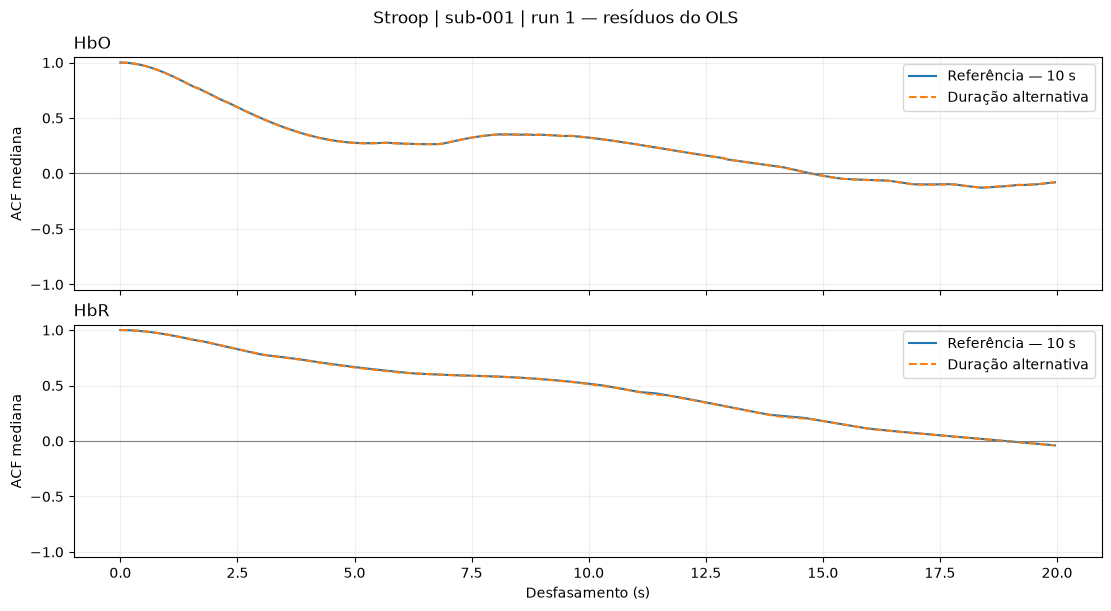

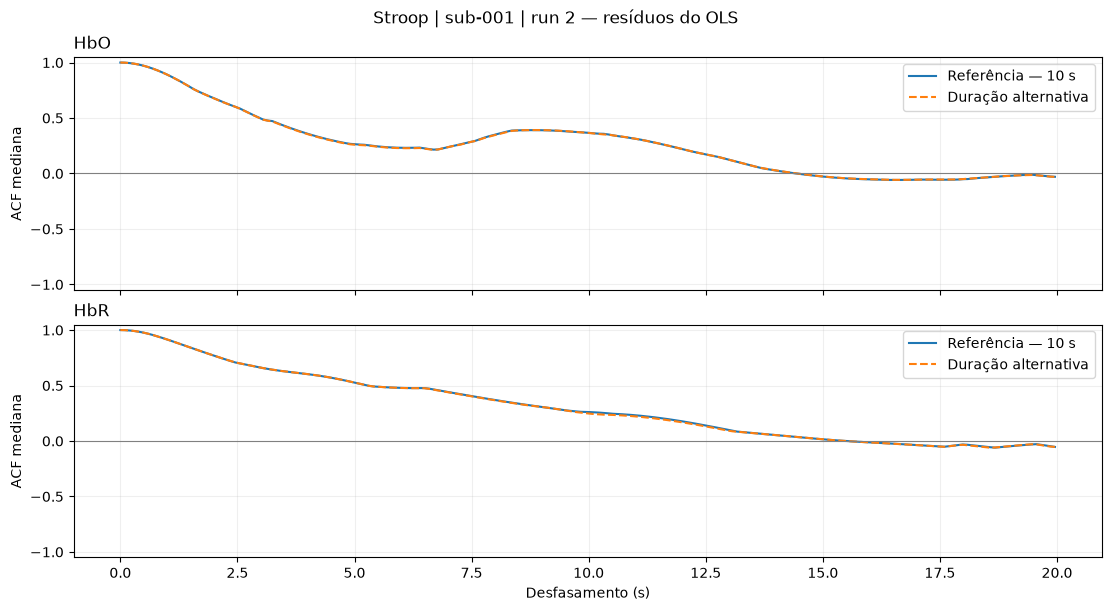

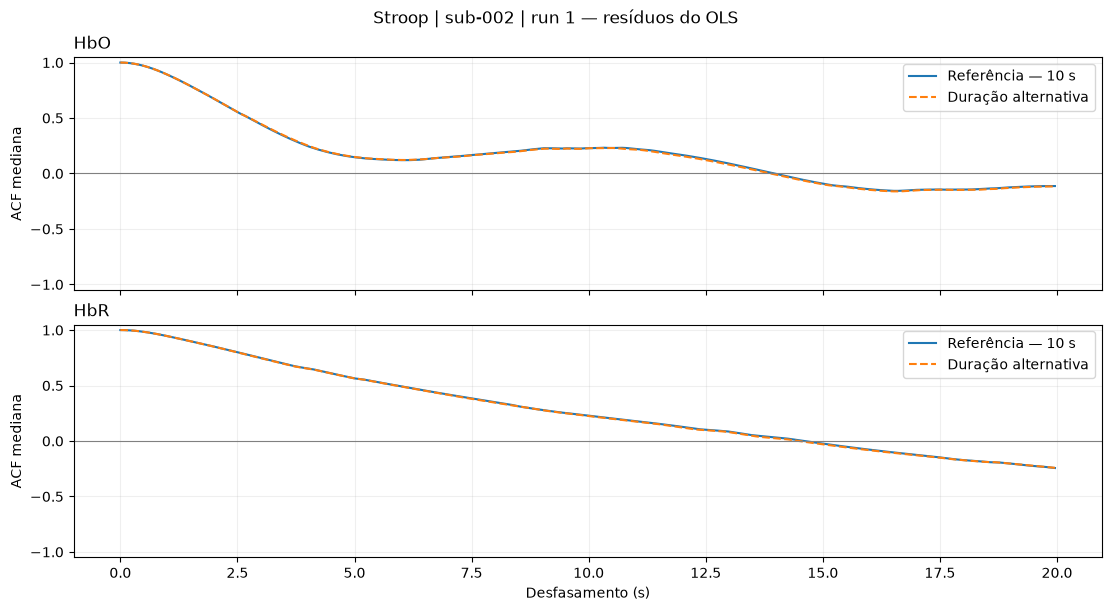

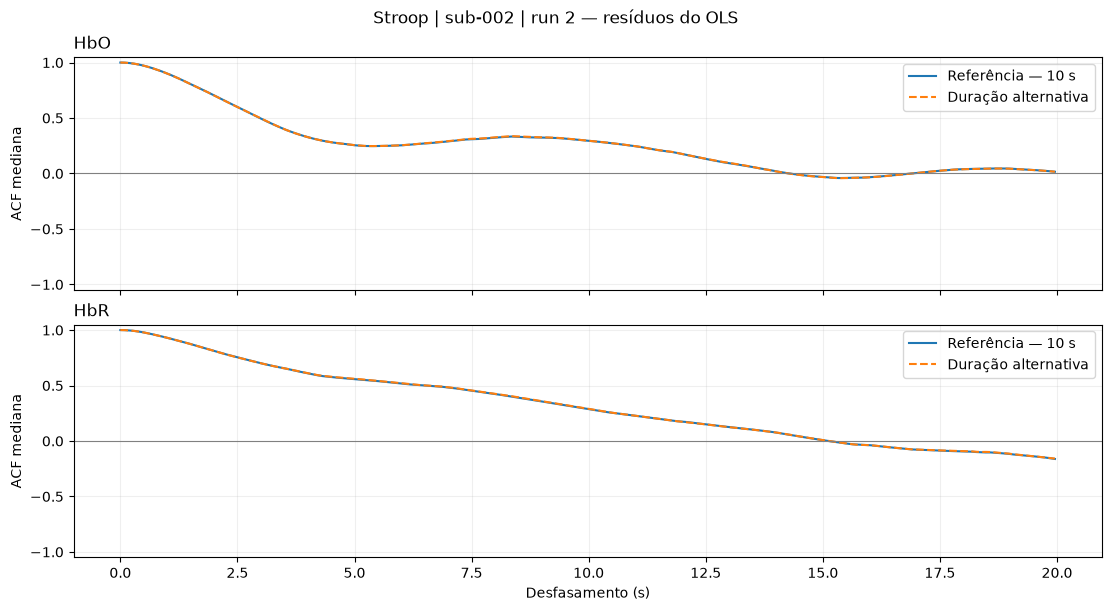


Ajustes exploratórios concluídos. Sem testes ou ficheiros escritos.


In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

necessarias_12 = (
    "piloto_stroop_haemo_filtrado",
    "piloto_stroop_matrizes_11",
    "piloto_stroop_sci_pares",
)
faltam_12 = [nome for nome in necessarias_12 if nome not in globals()]
if faltam_12:
    raise RuntimeError(f"Faltam saídas das etapas anteriores: {faltam_12}")

CHAVES_12 = {
    ("sub-001", 1), ("sub-001", 2),
    ("sub-002", 1), ("sub-002", 2),
}
COLUNAS_12 = ["Congruente", "Incongruente", "constant"]
VERSOES_12 = ("referencia", "sensibilidade")

if any(set(globals()[nome]) != CHAVES_12 for nome in necessarias_12):
    raise RuntimeError("A Etapa 12 espera as quatro runs piloto em todas as entradas.")


def acf_12(residuos, lag_max):
    """ACF por canal, normalizada pela soma de quadrados no lag zero."""
    z = residuos - residuos.mean(axis=0, keepdims=True)
    energia = np.sum(z**2, axis=0)
    validos = np.isfinite(energia) & (energia > 0)

    acf = np.full((lag_max + 1, z.shape[1]), np.nan)
    acf[0, validos] = 1.0

    for lag in range(1, lag_max + 1):
        produto = np.sum(z[:-lag, validos] * z[lag:, validos], axis=0)
        acf[lag, validos] = produto / energia[validos]

    return acf


registos_12 = []
curvas_12 = {}

for chave, raw in sorted(piloto_stroop_haemo_filtrado.items()):
    sujeito, run = chave
    etiqueta = f"{sujeito} | Stroop run {run}"
    print(f"A ajustar OLS: {etiqueta}...", flush=True)

    pares = piloto_stroop_sci_pares[chave]
    longos = pares.loc[
        pares["tipo_distancia"].eq("longo") & pares["valido"], "par"
    ].tolist()

    if not longos or len(longos) != len(set(longos)):
        raise RuntimeError(f"{etiqueta}: lista de pares longos válidos inesperada.")

    canais = [f"{par} {tipo}" for par in longos for tipo in ("hbo", "hbr")]
    indisponiveis = set(canais) - (set(raw.ch_names) - set(raw.info["bads"]))
    if indisponiveis:
        raise RuntimeError(
            f"{etiqueta}: canais em falta ou marcados como maus: "
            f"{sorted(indisponiveis)}"
        )

    # Uma coluna de Y por canal. A unidade é µM.
    y = raw.get_data(picks=canais).T * 1e6
    if not np.isfinite(y).all():
        raise ValueError(f"{etiqueta}: sinal com valores não finitos.")

    sfreq = float(raw.info["sfreq"])
    lag_max = min(int(np.floor(20 * sfreq)), raw.n_times - 1)
    lag_1s = int(round(sfreq))
    tipos = np.array([canal.split()[-1] for canal in canais])

    matrizes = piloto_stroop_matrizes_11[chave]
    if set(matrizes) != set(VERSOES_12):
        raise RuntimeError(f"{etiqueta}: faltam versões da matriz de desenho.")

    for versao in VERSOES_12:
        matriz = matrizes[versao]
        if (
            list(matriz.columns) != COLUNAS_12
            or not np.array_equal(matriz.index.to_numpy(), raw.times)
        ):
            raise RuntimeError(f"{etiqueta} / {versao}: matriz ou grelha inesperada.")

        x = matriz.to_numpy(dtype=float)
        if not np.isfinite(x).all():
            raise ValueError(f"{etiqueta} / {versao}: matriz não finita.")

        betas, _, posto, _ = np.linalg.lstsq(x, y, rcond=None)
        if posto != len(COLUNAS_12):
            raise RuntimeError(f"{etiqueta} / {versao}: matriz sem posto completo.")

        residuos = y - x @ betas
        contraste = betas[1] - betas[0]

        if not np.isfinite(betas).all() or not np.isfinite(residuos).all():
            raise ValueError(f"{etiqueta} / {versao}: ajuste não finito.")

        acf = acf_12(residuos, lag_max)

        for tipo in ("hbo", "hbr"):
            indices = np.flatnonzero(tipos == tipo)
            com_acf = indices[np.isfinite(acf[0, indices])]
            if not com_acf.size:
                raise RuntimeError(f"{etiqueta} / {versao}: ACF indefinida para {tipo}.")

            curvas_12[(chave, versao, tipo)] = (
                np.arange(lag_max + 1) / sfreq,
                np.median(acf[:, com_acf], axis=1),
            )

        for j, canal in enumerate(canais):
            registos_12.append({
                "sujeito": sujeito,
                "run": run,
                "canal": canal,
                "cromoforo": tipos[j],
                "versao": versao,
                "beta_congruente_uM": betas[0, j],
                "beta_incongruente_uM": betas[1, j],
                "contraste_uM": contraste[j],
                "acf_lag1": acf[1, j],
                "acf_1s": acf[lag_1s, j],
            })

df_stroop_12_betas = pd.DataFrame(registos_12)

ids_12 = ["sujeito", "run", "cromoforo", "canal"]
ref_12 = df_stroop_12_betas.loc[
    df_stroop_12_betas["versao"].eq("referencia")
].drop(columns="versao")
alt_12 = df_stroop_12_betas.loc[
    df_stroop_12_betas["versao"].eq("sensibilidade")
].drop(columns="versao")

df_stroop_12_comparacao = ref_12.merge(
    alt_12, on=ids_12, how="outer", validate="one_to_one",
    suffixes=("_ref", "_alt"), indicator=True,
)

c = df_stroop_12_comparacao
if not c["_merge"].eq("both").all():
    raise RuntimeError("As duas versões não têm exatamente os mesmos canais.")

c.drop(columns="_merge", inplace=True)
c["delta_uM"] = c["contraste_uM_alt"] - c["contraste_uM_ref"]
c["delta_abs_uM"] = c["delta_uM"].abs()
c["inversao_sinal"] = (
    (c["contraste_uM_ref"].lt(0) & c["contraste_uM_alt"].gt(0))
    | (c["contraste_uM_ref"].gt(0) & c["contraste_uM_alt"].lt(0))
)

df_stroop_12_resumo = (
    c.groupby(["sujeito", "run", "cromoforo"], as_index=False)
    .agg(
        n_canais=("canal", "size"),
        delta_mediano_uM=("delta_uM", "median"),
        delta_abs_mediano_uM=("delta_abs_uM", "median"),
        delta_abs_max_uM=("delta_abs_uM", "max"),
        inversoes=("inversao_sinal", "sum"),
        acf_lag1_ref=("acf_lag1_ref", "median"),
        acf_lag1_alt=("acf_lag1_alt", "median"),
        acf_1s_ref=("acf_1s_ref", "median"),
        acf_1s_alt=("acf_1s_alt", "median"),
        n_acf_definida_ref=("acf_lag1_ref", "count"),
        n_acf_definida_alt=("acf_lag1_alt", "count"),
    )
)

print("\nETAPA 12 — SENSIBILIDADE DO CONTRASTE E ACF DOS RESÍDUOS")
print("Delta = contraste com duração alternativa − contraste com 10 s.")
print("ACF lag 1 = uma amostra; ACF 1 s = lag mais próximo de um segundo.")
print(df_stroop_12_resumo.round(4).to_string(index=False))

print("\nCINCO MAIORES ALTERAÇÕES ABSOLUTAS DO CONTRASTE")
print(c.nlargest(5, "delta_abs_uM")[
    ids_12 + ["contraste_uM_ref", "contraste_uM_alt", "delta_uM", "inversao_sinal"]
].round(4).to_string(index=False))

for sujeito, run in sorted(CHAVES_12):
    chave = (sujeito, run)
    fig, eixos = plt.subplots(
        2, 1, figsize=(11, 6), sharex=True, sharey=True,
        layout="constrained",
    )

    for ax, tipo in zip(eixos, ("hbo", "hbr")):
        for versao, cor, estilo, legenda in (
            ("referencia", "tab:blue", "-", "Referência — 10 s"),
            ("sensibilidade", "tab:orange", "--", "Duração alternativa"),
        ):
            lags, curva = curvas_12[(chave, versao, tipo)]
            ax.plot(lags, curva, color=cor, linestyle=estilo, label=legenda)

        ax.axhline(0, color="0.5", linewidth=0.8)
        ax.set_title("HbO" if tipo == "hbo" else "HbR", loc="left")
        ax.set_ylabel("ACF mediana")
        ax.set_ylim(-1.05, 1.05)
        ax.grid(alpha=0.2)
        ax.legend(loc="upper right")

    eixos[-1].set_xlabel("Desfasamento (s)")
    fig.suptitle(f"Stroop | {sujeito} | run {run} — resíduos do OLS")
    display(fig)
    plt.close(fig)

print("\nAjustes exploratórios concluídos. Sem testes ou ficheiros escritos.")

## Etapa 13 — Stroop: diagnóstico da autocorrelação com AR(10)

### Objetivo
Avaliar se uma transformação autorregressiva de ordem 10 reduz
a autocorrelação dos resíduos e verificar se a sensibilidade do
contraste Incongruente − Congruente à duração dos blocos se mantém.

### Entradas
- `piloto_stroop_haemo_filtrado`: sinais HbO/HbR da Etapa 8.
- `piloto_stroop_matrizes_11`: matrizes com os regressores de tarefa filtrados.
- `df_stroop_12_comparacao`: canais longos válidos e contrastes OLS.
- `acf_12`: função de autocorrelação residual da Etapa 12.

### Procedimento
1. Estimar um AR(10) por canal e run, por Yule–Walker, a partir
   dos resíduos OLS da versão de referência (blocos de 10 s).
2. Aplicar a mesma transformação ao sinal e a todas as colunas
   das duas matrizes de desenho, incluindo a constante.
3. Excluir as primeiras 10 amostras e reajustar o OLS de controlo
   na mesma janela utilizada pelo modelo transformado.
4. Comparar a ACF residual a uma amostra, a cerca de 1 s e o pico
   absoluto da ACF nos lags não nulos até 20 s.
5. Comparar o contraste entre durações, reportando diferenças
   em µM e inversões de sinal por run e cromóforo.

### Saídas
- `df_stroop_13_betas`: contrastes e diagnósticos por canal e versão.
- `df_stroop_13_acf`: resumo da ACF por run, cromóforo e versão.
- `df_stroop_13_comparacao`: comparação entre durações por canal.
- `df_stroop_13_resumo`: resumo da sensibilidade por run e cromóforo.

### Limites
O AR(10) é um diagnóstico exploratório em uma passagem, não uma
validação do modelo de ruído. Não se fazem testes inferenciais,
não se aplicam SSR nem WINGS e não se escrevem ficheiros.

In [23]:
import numpy as np
import pandas as pd
from scipy.linalg import solve_toeplitz
from scipy.signal import lfilter

P_13 = 10
VERSOES_13 = ("referencia", "sensibilidade")
COLUNAS_13 = ["Congruente", "Incongruente", "constant"]
registos_13 = []

for (sujeito, run), raw in sorted(piloto_stroop_haemo_filtrado.items()):
    chave = (sujeito, run)
    matrizes = piloto_stroop_matrizes_11[chave]
    x = {}

    for versao in VERSOES_13:
        dm = matrizes[versao]
        if (
            list(dm.columns) != COLUNAS_13
            or not np.array_equal(dm.index.to_numpy(), raw.times)
        ):
            raise RuntimeError(f"{chave} / {versao}: matriz ou grelha inesperada.")
        x[versao] = dm.to_numpy(dtype=float)

    canais_run = df_stroop_12_comparacao.loc[
        df_stroop_12_comparacao["sujeito"].eq(sujeito)
        & df_stroop_12_comparacao["run"].eq(run)
    ]
    canais = canais_run["canal"].tolist()
    if not canais or len(canais) != len(set(canais)):
        raise RuntimeError(f"{chave}: lista de canais da Etapa 12 inválida.")

    y_run = raw.get_data(picks=canais).T * 1e6
    sfreq = float(raw.info["sfreq"])
    lag_1s = max(1, int(round(sfreq)))
    lag_max = min(int(np.floor(20 * sfreq)), raw.n_times - P_13 - 1)
    if lag_max < lag_1s:
        raise RuntimeError(f"{chave}: janela insuficiente para a ACF.")

    for j, linha in enumerate(canais_run.itertuples(index=False)):
        y = y_run[:, j]
        b_ref = np.linalg.lstsq(x["referencia"], y, rcond=None)[0]
        e_ref = y - x["referencia"] @ b_ref
        e_ref -= e_ref.mean()

        gamma = np.array([
            np.dot(e_ref[k:], e_ref[:len(e_ref) - k]) / len(e_ref)
            for k in range(P_13 + 1)
        ])
        if not np.isfinite(gamma).all() or gamma[0] <= 0:
            raise RuntimeError(f"{chave} / {linha.canal}: AR indefinido.")

        rho = gamma / gamma[0]
        phi = solve_toeplitz(rho[:-1], rho[1:])
        filtro = np.r_[1.0, -phi]
        raiz_max = np.max(np.abs(np.roots(filtro)))
        if not np.isfinite(raiz_max) or raiz_max >= 1:
            raise RuntimeError(f"{chave} / {linha.canal}: AR instável.")

        yw = lfilter(filtro, [1.0], y)[P_13:]
        for versao, sufixo in zip(VERSOES_13, ("ref", "alt")):
            xv = x[versao]
            xw = lfilter(filtro, [1.0], xv, axis=0)[P_13:]

            # OLS de controlo, reajustado na mesma janela do AR.
            yo, xo = y[P_13:], xv[P_13:]
            bo, _, posto_o, _ = np.linalg.lstsq(xo, yo, rcond=None)
            bw, _, posto_w, _ = np.linalg.lstsq(xw, yw, rcond=None)
            if min(posto_o, posto_w) != len(COLUNAS_13):
                raise RuntimeError(
                    f"{chave} / {linha.canal} / {versao}: posto incompleto."
                )

            acf_o = acf_12((yo - xo @ bo)[:, None], lag_max)[:, 0]
            acf_w = acf_12((yw - xw @ bw)[:, None], lag_max)[:, 0]
            if not (np.isfinite(acf_o).all() and np.isfinite(acf_w).all()):
                raise RuntimeError(f"{chave} / {linha.canal}: ACF indefinida.")

            registos_13.append({
                "sujeito": sujeito, "run": run,
                "canal": linha.canal, "cromoforo": linha.cromoforo,
                "versao": versao, "n_amostras": len(yw),
                "janela_ar_s": P_13 / sfreq, "raiz_max_ar": raiz_max,
                "contraste_ols_etapa12_uM": getattr(linha, f"contraste_uM_{sufixo}"),
                "contraste_ols_janela_uM": bo[1] - bo[0],
                "contraste_ar_uM": bw[1] - bw[0],
                "acf_lag1_ols": acf_o[1], "acf_lag1_ar": acf_w[1],
                "acf_1s_ols": acf_o[lag_1s], "acf_1s_ar": acf_w[lag_1s],
                "pico_abs_acf_ols": np.max(np.abs(acf_o[1:])),
                "pico_abs_acf_ar": np.max(np.abs(acf_w[1:])),
            })

df_stroop_13_betas = pd.DataFrame(registos_13)
grupos_13 = ["sujeito", "run", "cromoforo"]

df_stroop_13_acf = df_stroop_13_betas.groupby(
    grupos_13 + ["versao"], as_index=False
).agg(
    n_canais=("canal", "size"),
    janela_ar_s=("janela_ar_s", "first"),
    acf_lag1_ols=("acf_lag1_ols", "median"),
    acf_lag1_ar=("acf_lag1_ar", "median"),
    acf_1s_ols=("acf_1s_ols", "median"),
    acf_1s_ar=("acf_1s_ar", "median"),
    pico_abs_acf_ols=("pico_abs_acf_ols", "median"),
    pico_abs_acf_ar=("pico_abs_acf_ar", "median"),
)

c13 = df_stroop_13_betas.pivot(
    index=grupos_13 + ["canal"], columns="versao", values="contraste_ar_uM"
).reset_index()
c13["delta_uM"] = c13["sensibilidade"] - c13["referencia"]
c13["delta_abs_uM"] = c13["delta_uM"].abs()
c13["inversao_sinal"] = c13["sensibilidade"] * c13["referencia"] < 0
df_stroop_13_comparacao = c13

df_stroop_13_resumo = c13.groupby(grupos_13, as_index=False).agg(
    n_canais=("canal", "size"),
    delta_mediano_uM=("delta_uM", "median"),
    delta_abs_mediano_uM=("delta_abs_uM", "median"),
    delta_abs_max_uM=("delta_abs_uM", "max"),
    inversoes=("inversao_sinal", "sum"),
)

print("ETAPA 13 — ACF RESIDUAL: OLS E AR(10), MESMA JANELA")
print(df_stroop_13_acf.round(4).to_string(index=False))
print("\nSENSIBILIDADE DO CONTRASTE À DURAÇÃO APÓS AR(10)")
print(df_stroop_13_resumo.round(4).to_string(index=False))
print("\nCINCO MAIORES ALTERAÇÕES ABSOLUTAS APÓS AR(10)")
print(c13.nlargest(5, "delta_abs_uM").round(4).to_string(index=False))
print("\nSem testes inferenciais, SSR, WINGS ou ficheiros escritos.")

ETAPA 13 — ACF RESIDUAL: OLS E AR(10), MESMA JANELA
sujeito  run cromoforo        versao  n_canais  janela_ar_s  acf_lag1_ols  acf_lag1_ar  acf_1s_ols  acf_1s_ar  pico_abs_acf_ols  pico_abs_acf_ar
sub-001    1       hbo    referencia        19        0.983        0.9989       0.9706      0.9014    -0.1885            0.9989           0.9706
sub-001    1       hbo sensibilidade        19        0.983        0.9989       0.9706      0.9012    -0.1881            0.9989           0.9706
sub-001    1       hbr    referencia        19        0.983        0.9995       0.9662      0.9601    -0.1997            0.9995           0.9662
sub-001    1       hbr sensibilidade        19        0.983        0.9995       0.9661      0.9602    -0.2007            0.9995           0.9661
sub-001    2       hbo    referencia        19        0.983        0.9988       0.9645      0.8941    -0.2071            0.9988           0.9645
sub-001    2       hbo sensibilidade        19        0.983        0.9988     

## Etapa 14 — Stroop: diagnóstico OLS–AR(10) na mesma janela

### Objetivo
Visualizar a autocorrelação residual e quantificar a alteração
do contraste Incongruente − Congruente entre OLS e AR(10),
mantendo fixa a duração de referência de 10 s.

### Procedimento
1. Comparar os contrastes OLS e AR(10) já calculados na Etapa 13
   sobre a mesma janela, excluindo as primeiras dez amostras.
2. Reconstituir os resíduos dos dois ajustes para visualizar
   a ACF mediana por run e cromóforo até 20 s, com um painel
   separado para os primeiros 2 s.
3. Resumir a diferença AR(10) menos OLS em µM e identificar
   inversões estritas de sinal.

### Saídas
- `df_stroop_14_comparacao`: contrastes emparelhados por canal.
- `df_stroop_14_resumo`: diferenças por run e cromóforo.
- Quatro figuras da ACF residual: uma por run.

### Limites
Não se testa outra ordem AR, não se seleciona um modelo final,
não se fazem testes inferenciais e não se escrevem ficheiros.

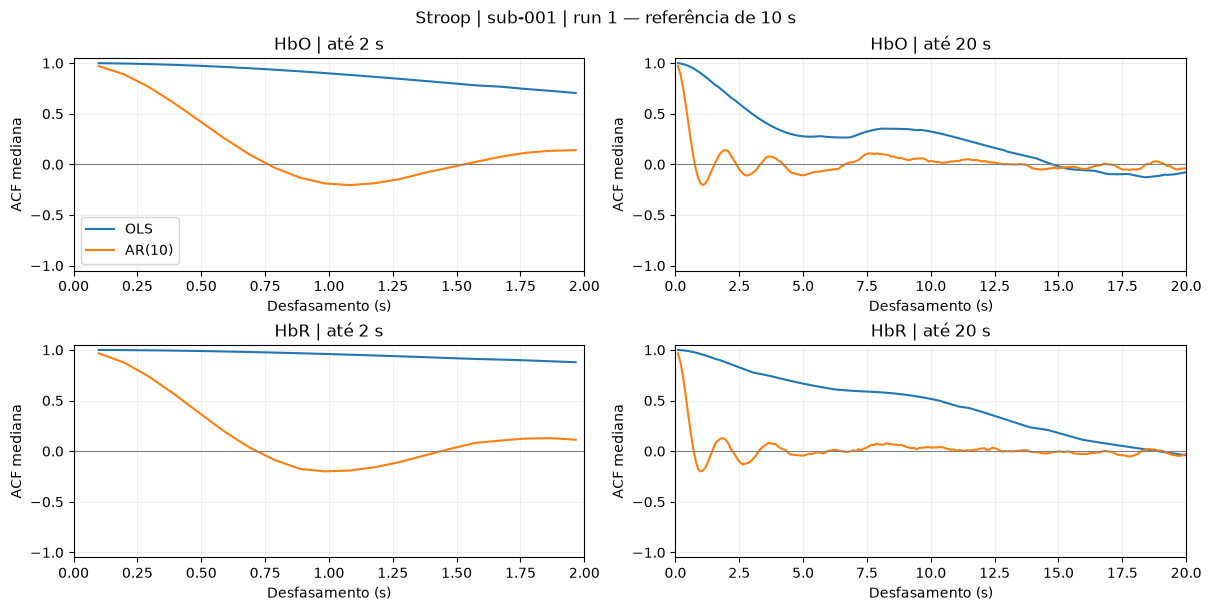

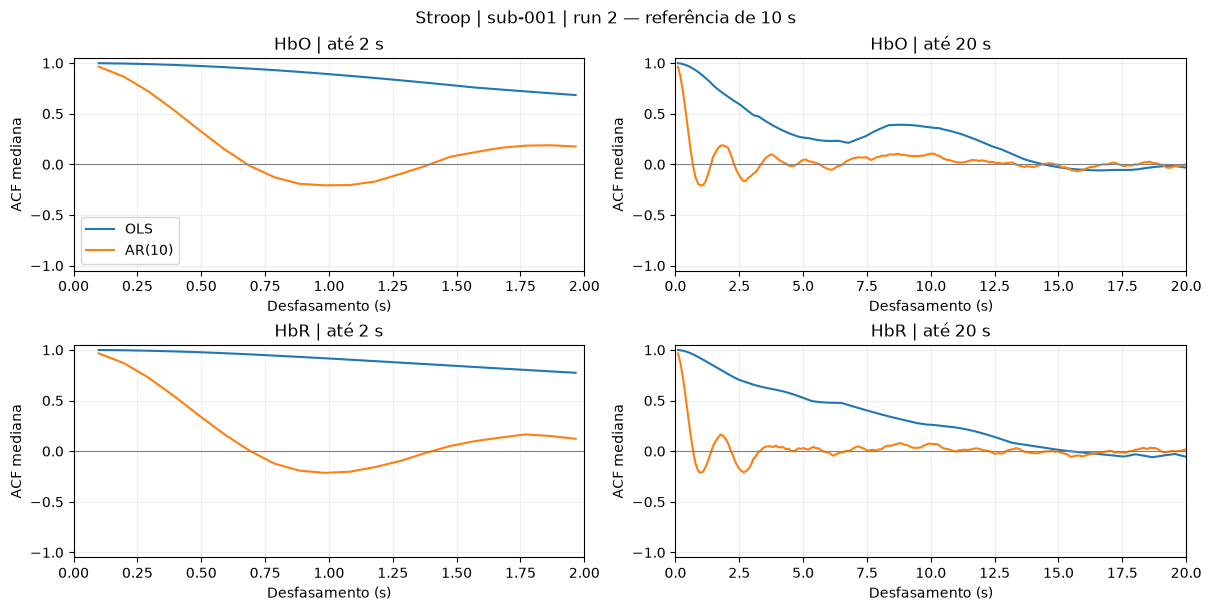

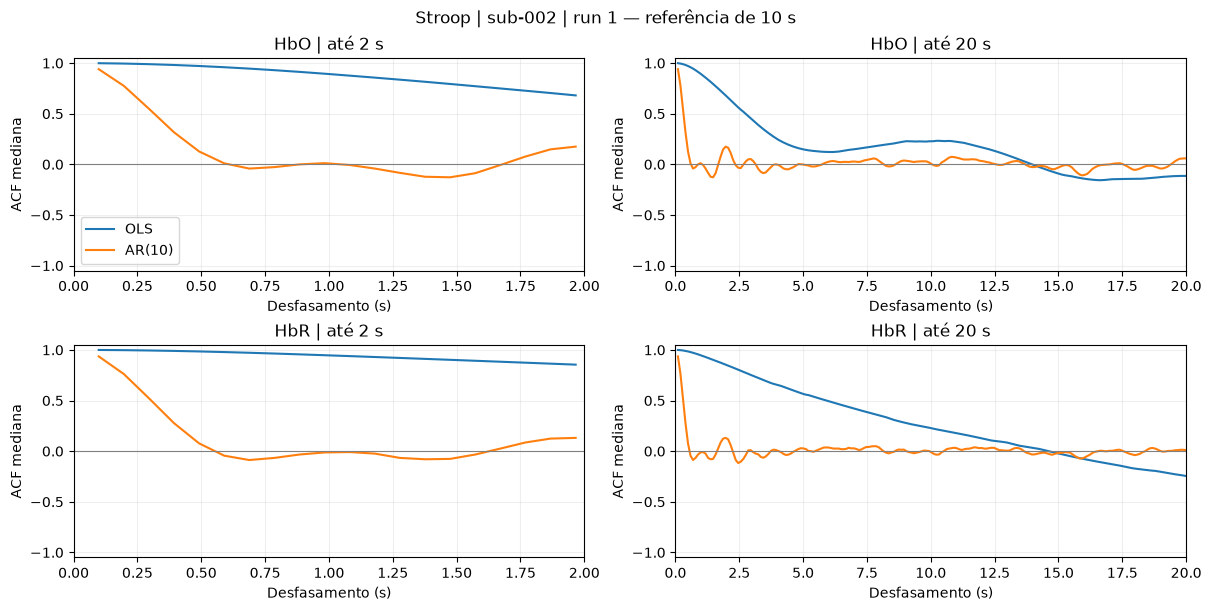

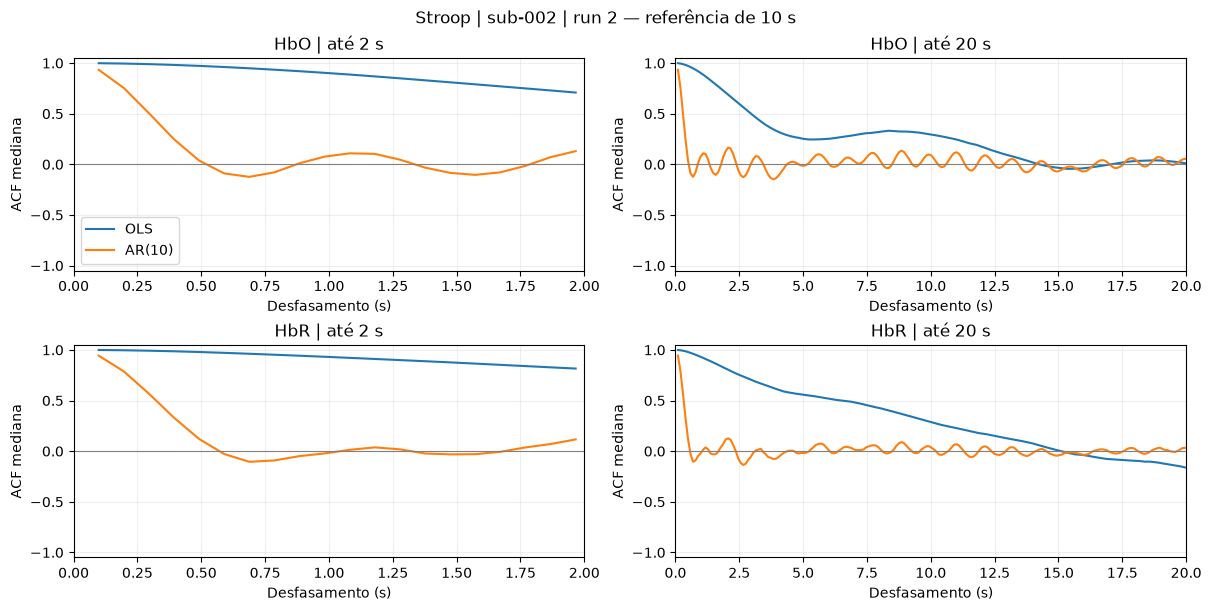

ETAPA 14 — AR(10) MENOS OLS, MESMA JANELA E BLOCOS DE 10 s
sujeito  run cromoforo  n_canais  delta_mediano_uM  delta_abs_mediano_uM  delta_abs_max_uM  inversoes
sub-001    1       hbo        19           -0.0184                0.0225            0.0952          2
sub-001    1       hbr        19            0.0139                0.0375            0.1116          6
sub-001    2       hbo        19            0.0220                0.0261            0.1452          2
sub-001    2       hbr        19           -0.0221                0.0252            0.0804          4
sub-002    1       hbo        20            0.0177                0.0177            0.0623          0
sub-002    1       hbr        20           -0.0135                0.0135            0.0413          5
sub-002    2       hbo        20           -0.0108                0.0108            0.0458          5
sub-002    2       hbr        20            0.0054                0.0072            0.0274          4

CINCO MAIORES ALTERAÇÕ

In [24]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from scipy.linalg import solve_toeplitz
from scipy.signal import lfilter

p14 = 10
chaves14 = ["sujeito", "run", "cromoforo"]
df_stroop_14_comparacao = df_stroop_13_betas.loc[
    df_stroop_13_betas["versao"].eq("referencia"),
    chaves14 + ["canal", "n_amostras",
                "contraste_ols_janela_uM", "contraste_ar_uM"],
].copy()

d14 = df_stroop_14_comparacao
ols14 = "contraste_ols_janela_uM"
ar14 = "contraste_ar_uM"
d14["delta_uM"] = d14[ar14] - d14[ols14]
d14["delta_abs_uM"] = d14["delta_uM"].abs()
d14["inversao_sinal"] = d14[ar14] * d14[ols14] < 0

df_stroop_14_resumo = d14.groupby(chaves14, as_index=False).agg(
    n_canais=("canal", "size"),
    delta_mediano_uM=("delta_uM", "median"),
    delta_abs_mediano_uM=("delta_abs_uM", "median"),
    delta_abs_max_uM=("delta_abs_uM", "max"),
    inversoes=("inversao_sinal", "sum"),
)

for chave, raw in sorted(piloto_stroop_haemo_filtrado.items()):
    sujeito, run = chave
    dados = d14.loc[d14["sujeito"].eq(sujeito) & d14["run"].eq(run)]
    dm = piloto_stroop_matrizes_11[chave]["referencia"]
    canais = dados["canal"].tolist()

    if (
        not canais or len(canais) != len(set(canais))
        or list(dm.columns) != ["Congruente", "Incongruente", "constant"]
        or not np.array_equal(dm.index.to_numpy(), raw.times)
        or not dados["n_amostras"].eq(raw.n_times - p14).all()
    ):
        raise RuntimeError(f"{chave}: canais, desenho ou janela incompatíveis.")

    x = dm.to_numpy(dtype=float)
    y = raw.get_data(picks=canais).T * 1e6
    sfreq = float(raw.info["sfreq"])
    lag_max = min(int(20 * sfreq), len(x) - p14 - 1)
    lags_s = np.arange(lag_max + 1) / sfreq
    xo, yo = x[p14:], y[p14:]

    e_full = y - x @ np.linalg.lstsq(x, y, rcond=None)[0]
    e_full -= e_full.mean(axis=0)
    b_ols = np.linalg.lstsq(xo, yo, rcond=None)[0]
    e_ols = yo - xo @ b_ols
    e_ar = np.empty_like(e_ols)
    c_ar = np.empty(len(canais))

    for j, e in enumerate(e_full.T):
        gamma = np.array([
            np.dot(e[k:], e[:len(e) - k]) / len(e)
            for k in range(p14 + 1)
        ])
        if not np.isfinite(gamma).all() or gamma[0] <= 0:
            raise RuntimeError(f"{chave} / {canais[j]}: AR indefinido.")
        rho = gamma / gamma[0]
        filtro = np.r_[1.0, -solve_toeplitz(rho[:-1], rho[1:])]
        xw = lfilter(filtro, [1.0], x, axis=0)[p14:]
        yw = lfilter(filtro, [1.0], y[:, j])[p14:]
        bw, _, posto, _ = np.linalg.lstsq(xw, yw, rcond=None)
        if posto != 3:
            raise RuntimeError(f"{chave} / {canais[j]}: posto incompleto.")
        e_ar[:, j] = yw - xw @ bw
        c_ar[j] = bw[1] - bw[0]

    if not (
        np.allclose(b_ols[1] - b_ols[0], dados[ols14], atol=1e-8, rtol=1e-6)
        and np.allclose(c_ar, dados[ar14], atol=1e-8, rtol=1e-6)
    ):
        raise RuntimeError(f"{chave}: os contrastes não reproduzem a Etapa 13.")

    acf_o = acf_12(e_ols, lag_max)
    acf_a = acf_12(e_ar, lag_max)
    if not (np.isfinite(acf_o).all() and np.isfinite(acf_a).all()):
        raise RuntimeError(f"{chave}: ACF indefinida.")

    fig, axs = plt.subplots(2, 2, figsize=(12, 6), layout="constrained")
    for i, tipo in enumerate(("hbo", "hbr")):
        mask = dados["cromoforo"].eq(tipo).to_numpy()
        for ax, limite in zip(axs[i], (2, 20)):
            dentro = (lags_s > 0) & (lags_s <= limite)
            for acf, nome in ((acf_o, "OLS"), (acf_a, "AR(10)")):
                ax.plot(lags_s[dentro], np.median(acf[dentro][:, mask], axis=1),
                        label=nome)
            ax.axhline(0, color="0.5", linewidth=0.8)
            ax.set(xlim=(0, limite), ylim=(-1.05, 1.05),
                   title=f"{'HbO' if tipo == 'hbo' else 'HbR'} | até {limite} s",
                   xlabel="Desfasamento (s)", ylabel="ACF mediana")
            ax.grid(alpha=0.2)
    axs[0, 0].legend()
    fig.suptitle(f"Stroop | {sujeito} | run {run} — referência de 10 s")
    display(fig)
    plt.close(fig)

print("ETAPA 14 — AR(10) MENOS OLS, MESMA JANELA E BLOCOS DE 10 s")
print(df_stroop_14_resumo.round(4).to_string(index=False))
print("\nCINCO MAIORES ALTERAÇÕES ABSOLUTAS")
print(d14.nlargest(5, "delta_abs_uM")[
    chaves14 + ["canal", ols14, ar14, "delta_uM", "inversao_sinal"]
].round(4).to_string(index=False))

## Etapa 15 — Stroop: comparação de ordens AR na mesma janela

### Objetivo
Comparar OLS, AR(10), AR(20) e AR(40) nas quatro runs piloto,
mantendo a duração de referência de 10 s e a mesma janela
de ajuste para todos os modelos.

### Entradas
- `piloto_stroop_haemo_filtrado`: sinais HbO/HbR.
- `piloto_stroop_matrizes_11`: matrizes com os regressores filtrados.
- `df_stroop_14_comparacao`: lista de canais longos válidos.
- `acf_12`: função para calcular a autocorrelação residual.

### Procedimento
1. Estimar cada modelo AR por Yule–Walker, por canal e run,
   usando os mesmos resíduos OLS da série completa.
2. Aplicar a transformação ao sinal e a todas as colunas da
   matriz, incluindo a constante. Ajustar todos os modelos,
   incluindo OLS, após excluir as primeiras 40 amostras.
3. Verificar a estabilidade das soluções AR, o posto e o
   condicionamento da matriz de desenho após a transformação.
4. Resumir a ACF residual a uma amostra, a cerca de 1 s e o
   pico absoluto até 20 s. Mostrar a ACF mediana por lag.
5. Comparar o contraste Incongruente − Congruente, em µM,
   com o OLS ajustado na mesma janela.

### Saídas
- `df_stroop_15_canais`: contrastes e diagnósticos por canal e modelo.
- `df_stroop_15_resumo`: resumo por run, cromóforo e modelo.
- `df_stroop_15_falhas`: ajustes não válidos, se existirem.
- Quatro figuras de ACF, uma por run.

### Limites
A comparação é exploratória e não seleciona automaticamente
uma ordem AR. O sinal do contraste não é critério de escolha.
Não se aplicam SSR ou WINGS, não se fazem testes inferenciais,
não se combinam runs e não se escrevem ficheiros.

A comparar modelos: sub-001 | Stroop run 1...
A comparar modelos: sub-001 | Stroop run 2...
A comparar modelos: sub-002 | Stroop run 1...
A comparar modelos: sub-002 | Stroop run 2...

ETAPA 15 — DIAGNÓSTICOS NA MESMA JANELA, BLOCOS DE 10 s
sujeito  run cromoforo  ordem modelo  n_canais  n_amostras  janela_ar_s  acf_lag1_med  acf_1s_med  abs_acf_1s_med  pico_abs_acf_med  condicao_max  raiz_max  delta_abs_med_uM  delta_abs_max_uM  inversoes
sub-001    1       hbo      0    OLS        19        3960       0.0000        0.9988      0.9007          0.9007            0.9988        2.3399       NaN            0.0000            0.0000          0
sub-001    1       hbo     10 AR(10)        19        3960       0.9830        0.9705     -0.1886          0.1886            0.9705        2.7033    0.9882            0.0225            0.0952          2
sub-001    1       hbo     20 AR(20)        19        3960       1.9661        0.9707     -0.1477          0.1477            0.9707        2.5066    0

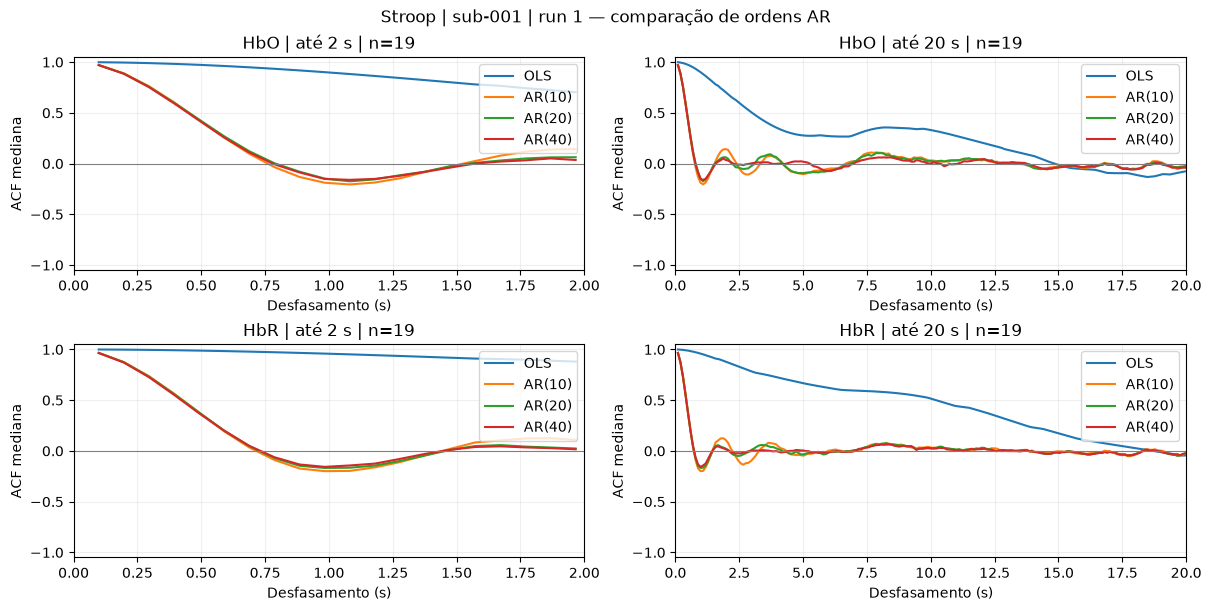

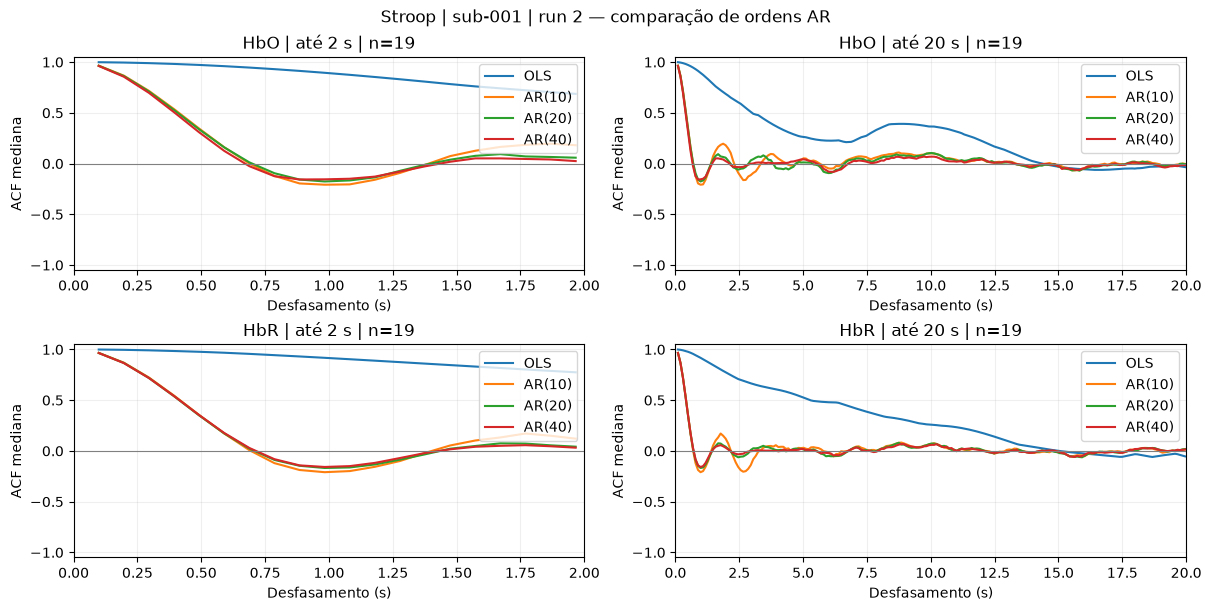

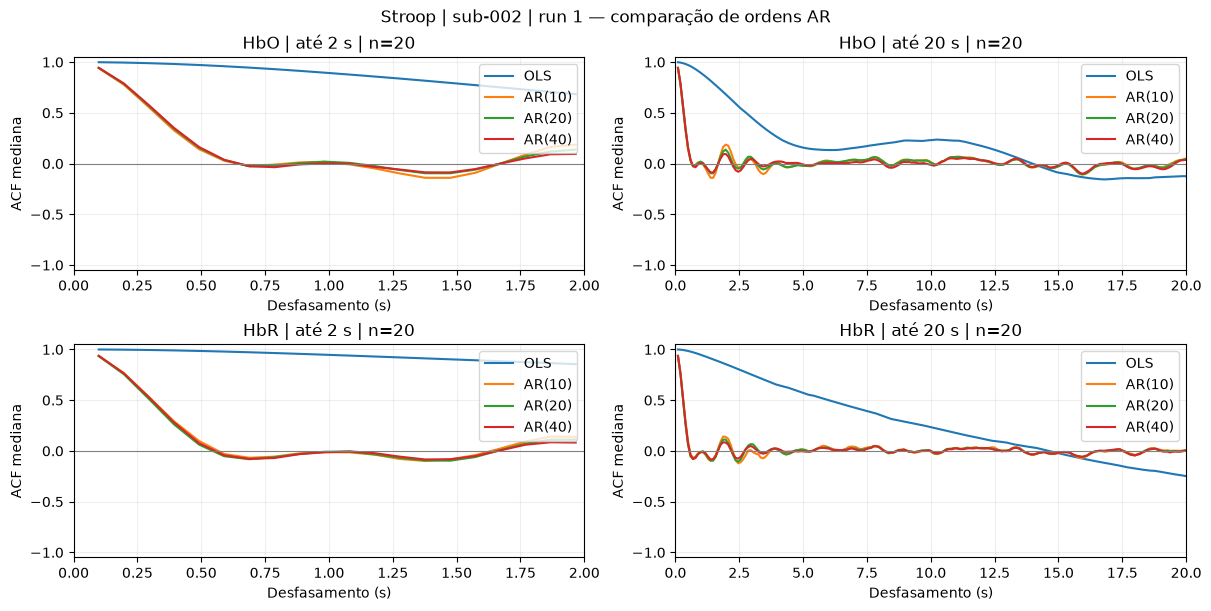

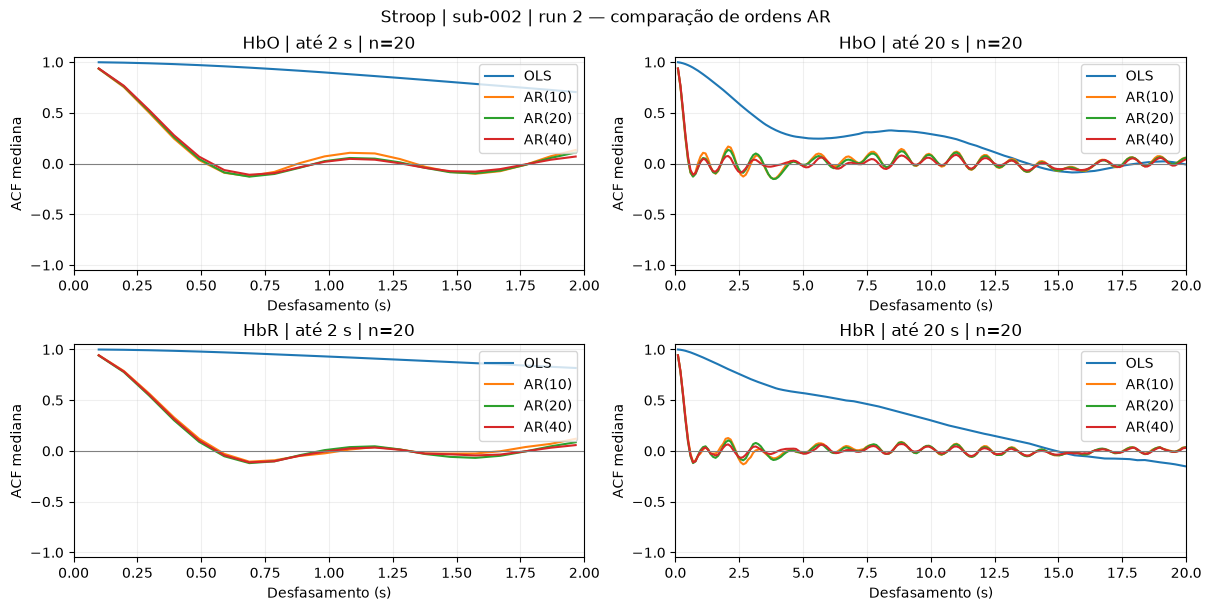


Sem testes inferenciais, SSR, WINGS ou ficheiros escritos.


In [26]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import solve_toeplitz
from scipy.signal import lfilter

ORDENS_15 = (0, 10, 20, 40)
CORTE_15 = max(ORDENS_15)
COLUNAS_15 = ["Congruente", "Incongruente", "constant"]
NOMES_15 = {0: "OLS", 10: "AR(10)", 20: "AR(20)", 40: "AR(40)"}

registos_15, falhas_15 = [], []
curvas_15, tempos_acf_15 = {}, {}

for chave, raw in sorted(piloto_stroop_haemo_filtrado.items()):
    sujeito, run = chave
    dados = df_stroop_14_comparacao
    dados = dados.loc[dados["sujeito"].eq(sujeito) & dados["run"].eq(run)]
    canais = dados["canal"].tolist()
    dm = piloto_stroop_matrizes_11[chave]["referencia"]

    if (
        not canais or len(canais) != len(set(canais))
        or not set(canais).issubset(set(raw.ch_names) - set(raw.info["bads"]))
        or list(dm.columns) != COLUNAS_15
        or not np.array_equal(dm.index.to_numpy(), raw.times)
    ):
        raise RuntimeError(f"{chave}: canais ou matriz incompatíveis.")

    x = dm.to_numpy(dtype=float)
    y = raw.get_data(picks=canais).T * 1e6
    if not (np.isfinite(x).all() and np.isfinite(y).all()):
        raise ValueError(f"{chave}: valores não finitos.")

    sfreq = float(raw.info["sfreq"])
    lag_1s = max(1, round(sfreq))
    lag_max = min(int(20 * sfreq), len(x) - CORTE_15 - 1)
    if lag_max < lag_1s:
        raise RuntimeError(f"{chave}: janela insuficiente para a ACF.")

    tempos_acf_15[chave] = np.arange(lag_max + 1) / sfreq
    b_full, _, posto_full, _ = np.linalg.lstsq(x, y, rcond=None)
    if posto_full != len(COLUNAS_15):
        raise RuntimeError(f"{chave}: OLS da série completa sem posto completo.")

    e_full = y - x @ b_full
    e_full -= e_full.mean(axis=0, keepdims=True)
    print(f"A comparar modelos: {sujeito} | Stroop run {run}...", flush=True)

    for j, linha in enumerate(dados.itertuples(index=False)):
        e = e_full[:, j]
        gamma = np.array([
            np.dot(e[k:], e[:len(e) - k]) / len(e)
            for k in range(CORTE_15 + 1)
        ])
        contrastes = {}

        for p in ORDENS_15:
            ids = {
                "sujeito": sujeito, "run": run, "canal": linha.canal,
                "cromoforo": linha.cromoforo, "ordem": p,
                "modelo": NOMES_15[p],
            }
            try:
                raiz_max = np.nan
                if p == 0:
                    xx, yy = x[CORTE_15:], y[CORTE_15:, j]
                else:
                    if not np.isfinite(gamma).all() or gamma[0] <= 0:
                        raise ValueError("Autocovariância inicial inválida.")
                    rho = gamma[:p + 1] / gamma[0]
                    phi = solve_toeplitz(rho[:-1], rho[1:])
                    if not np.isfinite(phi).all():
                        raise ValueError("Coeficientes AR não finitos.")
                    filtro = np.r_[1.0, -phi]
                    raiz_max = float(np.max(np.abs(np.roots(filtro))))
                    if not np.isfinite(raiz_max) or raiz_max >= 1:
                        raise ValueError(f"AR instável: raiz máxima = {raiz_max:.8g}")
                    xx = lfilter(filtro, [1.0], x, axis=0)[CORTE_15:]
                    yy = lfilter(filtro, [1.0], y[:, j])[CORTE_15:]

                b, _, posto, sv = np.linalg.lstsq(xx, yy, rcond=None)
                if posto != len(COLUNAS_15) or not np.isfinite(b).all():
                    raise ValueError("Ajuste inválido ou matriz sem posto completo.")

                acf = acf_12((yy - xx @ b)[:, None], lag_max)[:, 0]
                if not np.isfinite(acf).all():
                    raise ValueError("ACF residual indefinida.")

            except (ValueError, np.linalg.LinAlgError) as erro:
                if p == 0:
                    raise RuntimeError(f"{chave} / {linha.canal}: OLS inválido.") from erro
                falhas_15.append({**ids, "motivo": str(erro)})
                continue

            contraste = float(b[1] - b[0])
            contrastes[p] = contraste
            ref = contrastes[0]
            registos_15.append({
                **ids,
                "n_amostras": len(yy),
                "janela_ar_s": p / sfreq,
                "raiz_max_ar": raiz_max,
                "condicao_matriz": float(sv[0] / sv[-1]),
                "contraste_uM": contraste,
                "delta_vs_ols_uM": contraste - ref,
                "delta_abs_vs_ols_uM": abs(contraste - ref),
                "inversao_vs_ols": (contraste < 0 < ref) or (ref < 0 < contraste),
                "acf_lag1": acf[1],
                "acf_1s": acf[lag_1s],
                "abs_acf_1s": abs(acf[lag_1s]),
                "pico_abs_acf": np.max(np.abs(acf[1:])),
            })
            curvas_15[(chave, linha.cromoforo, linha.canal, p)] = acf

df_stroop_15_canais = pd.DataFrame(registos_15)
df_stroop_15_falhas = pd.DataFrame(
    falhas_15,
    columns=["sujeito", "run", "canal", "cromoforo", "ordem", "modelo", "motivo"],
)

# Resumos e figuras usam só canais com ajuste válido nos quatro modelos.
ids_canal_15 = ["sujeito", "run", "cromoforo", "canal"]
n_modelos_15 = df_stroop_15_canais.groupby(ids_canal_15)["ordem"].transform("nunique")
comuns_15 = df_stroop_15_canais.loc[n_modelos_15.eq(len(ORDENS_15))].copy()

df_stroop_15_resumo = comuns_15.groupby(
    ["sujeito", "run", "cromoforo", "ordem", "modelo"], as_index=False
).agg(
    n_canais=("canal", "size"),
    n_amostras=("n_amostras", "first"),
    janela_ar_s=("janela_ar_s", "first"),
    acf_lag1_med=("acf_lag1", "median"),
    acf_1s_med=("acf_1s", "median"),
    abs_acf_1s_med=("abs_acf_1s", "median"),
    pico_abs_acf_med=("pico_abs_acf", "median"),
    condicao_max=("condicao_matriz", "max"),
    raiz_max=("raiz_max_ar", "max"),
    delta_abs_med_uM=("delta_abs_vs_ols_uM", "median"),
    delta_abs_max_uM=("delta_abs_vs_ols_uM", "max"),
    inversoes=("inversao_vs_ols", "sum"),
)

print("\nETAPA 15 — DIAGNÓSTICOS NA MESMA JANELA, BLOCOS DE 10 s")
print(df_stroop_15_resumo.round(4).to_string(index=False))
print(f"\nAjustes AR não válidos: {len(df_stroop_15_falhas)}")
if not df_stroop_15_falhas.empty:
    print(df_stroop_15_falhas.to_string(index=False))
    print("Os canais com falhas foram excluídos do resumo e das figuras de todos os modelos.")

for chave, lags in tempos_acf_15.items():
    sujeito, run = chave
    fig, axs = plt.subplots(2, 2, figsize=(12, 6), layout="constrained")

    for i, tipo in enumerate(("hbo", "hbr")):
        canais_tipo = comuns_15.loc[
            comuns_15["sujeito"].eq(sujeito)
            & comuns_15["run"].eq(run)
            & comuns_15["cromoforo"].eq(tipo)
            & comuns_15["ordem"].eq(0), "canal"
        ].tolist()

        for ax, limite in zip(axs[i], (2, 20)):
            dentro = (lags > 0) & (lags <= limite)
            for p in ORDENS_15:
                if canais_tipo:
                    acfs = np.stack([curvas_15[(chave, tipo, c, p)] for c in canais_tipo])
                    ax.plot(lags[dentro], np.median(acfs[:, dentro], axis=0), label=NOMES_15[p])
            ax.axhline(0, color="0.5", linewidth=0.8)
            ax.set(
                xlim=(0, limite), ylim=(-1.05, 1.05),
                title=f"{'HbO' if tipo == 'hbo' else 'HbR'} | até {limite} s | n={len(canais_tipo)}",
                xlabel="Desfasamento (s)", ylabel="ACF mediana",
            )
            ax.grid(alpha=0.2)
            if canais_tipo:
                ax.legend(loc="upper right")

    fig.suptitle(f"Stroop | {sujeito} | run {run} — comparação de ordens AR")
    plt.show()
    plt.close(fig)

print("\nSem testes inferenciais, SSR, WINGS ou ficheiros escritos.")

## Etapa 16A — Stroop: identificar a saída HbO/HbR anterior ao filtro

### Objetivo
Localizar no notebook o conjunto de quatro runs da Etapa 7,
para o emparelhar com o sinal filtrado da Etapa 8.

### Verificações
Procurar objetos Raw organizados por (participante, run).
Comparar canais, tipos, canais maus, frequência de amostragem,
primeira amostra e grelha temporal. Assinalar se o candidato é
o mesmo objeto ou tem dados idênticos ao sinal pós-filtro.

### Limites
Um candidato compatível é apenas uma pista: é necessário confirmar
na célula que o criou que corresponde à saída da Etapa 7 antes
do filtro. Não modificar dados, escolher candidatos automaticamente,
ajustar modelos nem escrever ficheiros.

In [27]:
import numpy as np
import pandas as pd
from mne.io import BaseRaw

def inventario_stroop_16a(namespace, pos):
    linhas = []

    for nome, candidato in namespace:
        if not isinstance(candidato, dict) or not set(pos).issubset(candidato):
            continue
        if not all(isinstance(candidato[k], BaseRaw) for k in pos):
            continue

        for sujeito, run in sorted(pos):
            chave = (sujeito, run)
            a, b = candidato[chave], pos[chave]
            tipos_a = a.get_channel_types()
            canais_ok = (
                a.ch_names == b.ch_names
                and tipos_a == b.get_channel_types()
                and set(tipos_a) == {"hbo", "hbr"}
            )
            grelha_ok = (
                a.n_times == b.n_times
                and a.first_samp == b.first_samp
                and a.info["sfreq"] == b.info["sfreq"]
                and np.array_equal(a.times, b.times)
            )

            if not (canais_ok and grelha_ok):
                iguais = None
            elif a is b:
                iguais = True
            else:
                iguais = bool(np.array_equal(a.get_data(), b.get_data()))

            linhas.append({
                "objeto": nome,
                "sujeito": sujeito,
                "run": run,
                "n_amostras": a.n_times,
                "canais_ok": canais_ok,
                "grelha_ok": grelha_ok,
                "bads_ok": set(a.info["bads"]) == set(b.info["bads"]),
                "mesmo_objeto_pos": a is b,
                "dados_identicos_pos": iguais,
            })

    return pd.DataFrame(linhas)

df_stroop_16a_inventario = inventario_stroop_16a(
    list(globals().items()), piloto_stroop_haemo_filtrado
)
print(df_stroop_16a_inventario.to_string(index=False))

                      objeto sujeito  run  n_amostras  canais_ok  grelha_ok  bads_ok  mesmo_objeto_pos dados_identicos_pos
           piloto_stroop_raw sub-001    1        4000      False       True    False             False                None
           piloto_stroop_raw sub-001    2        3823      False       True    False             False                None
           piloto_stroop_raw sub-002    1        3938      False       True    False             False                None
           piloto_stroop_raw sub-002    2        3691      False       True    False             False                None
            piloto_stroop_od sub-001    1        4000      False       True    False             False                None
            piloto_stroop_od sub-001    2        3823      False       True    False             False                None
            piloto_stroop_od sub-002    1        3938      False       True    False             False                None
            pilo

## Etapa 16B — Stroop: diagnóstico OLS antes e depois do filtro

### Objetivo
Comparar a autocorrelação residual em dois ramos emparelhados:
HbO/HbR antes do filtro com o desenho não filtrado (Etapa 10),
e HbO/HbR depois do filtro com o desenho filtrado (Etapa 11).

### Procedimento
1. Confirmar que a saída da Etapa 7 e o sinal da Etapa 8 têm
   os mesmos canais, marcações de qualidade e grelha temporal.
2. Reaplicar o filtro da Etapa 8 a uma cópia do sinal pré-filtro
   e confirmar que reproduz os canais analisados no pós-filtro.
3. Ajustar OLS nos mesmos canais longos válidos, com os blocos
   de referência de 10 s e a janela comum da Etapa 15.
4. Comparar a ACF residual por canal, a uma amostra, a cerca
   de 1 s e ao longo dos desfasamentos até 20 s.

### Saídas
- `df_stroop_16b_canais`: diagnósticos emparelhados por canal.
- `df_stroop_16b_resumo`: medianas por run e cromóforo.
- Quatro figuras da ACF residual, uma por run.

### Limites
Comparam-se dois ramos completos de sinal e desenho. O resultado
não isola a filtragem do sinal como causa única das diferenças.
Não se ajusta AR, não se corrigem épocas pela baseline local,
não se usa WINGS, não se faz inferência e não se escrevem ficheiros.

ETAPA 16B — OLS PRÉ/PÓS-FILTRO, MESMA JANELA
sujeito  run cromoforo  n_canais  n_amostras  acf_lag1_pre  acf_lag1_pos  delta_acf_lag1_med  abs_acf_1s_pre  abs_acf_1s_pos  pico_abs_pre  pico_abs_pos
sub-001    1       hbo        19        3960        0.9700        0.9988              0.0291          0.9033          0.9007        0.9719        0.9988
sub-001    1       hbr        19        3960        0.9950        0.9993              0.0044          0.9775          0.9587        0.9950        0.9993
sub-001    2       hbo        19        3783        0.9700        0.9988              0.0288          0.8984          0.8944        0.9709        0.9988
sub-001    2       hbr        19        3783        0.9940        0.9990              0.0052          0.9571          0.9172        0.9940        0.9990
sub-002    1       hbo        20        3898        0.8242        0.9988              0.1745          0.8555          0.8956        0.8555        0.9988
sub-002    1       hbr        20     

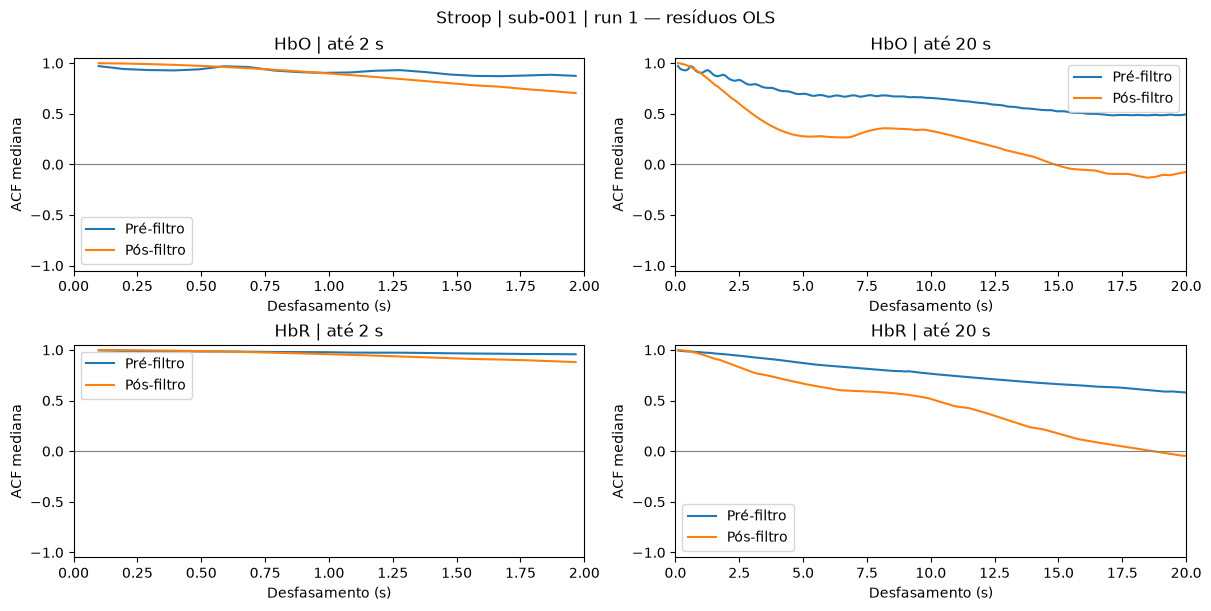

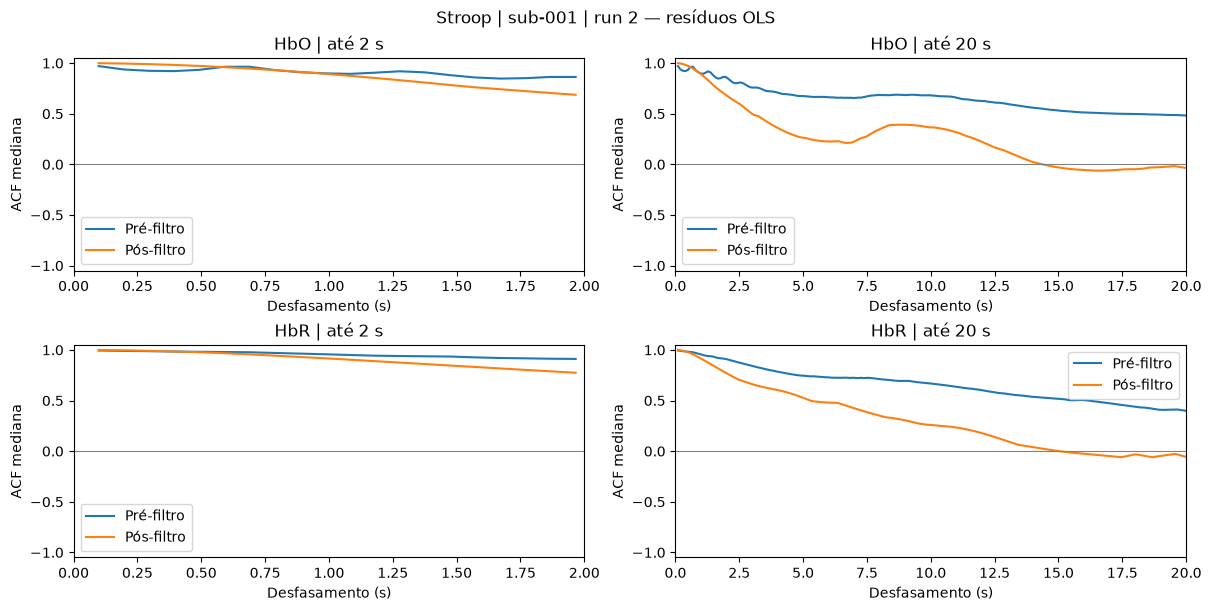

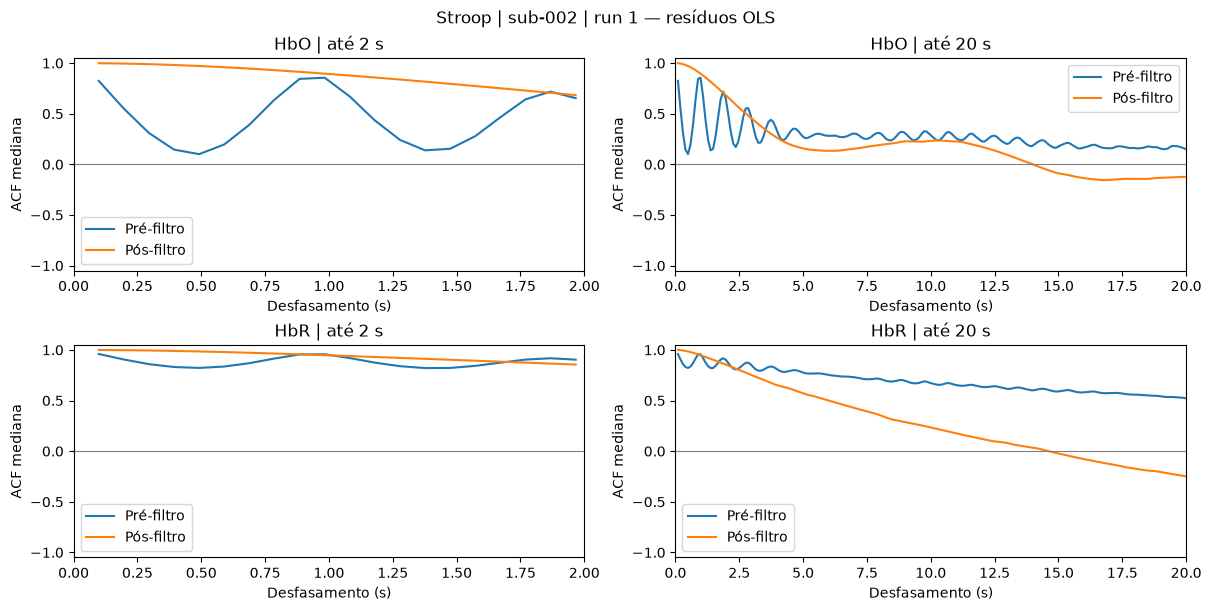

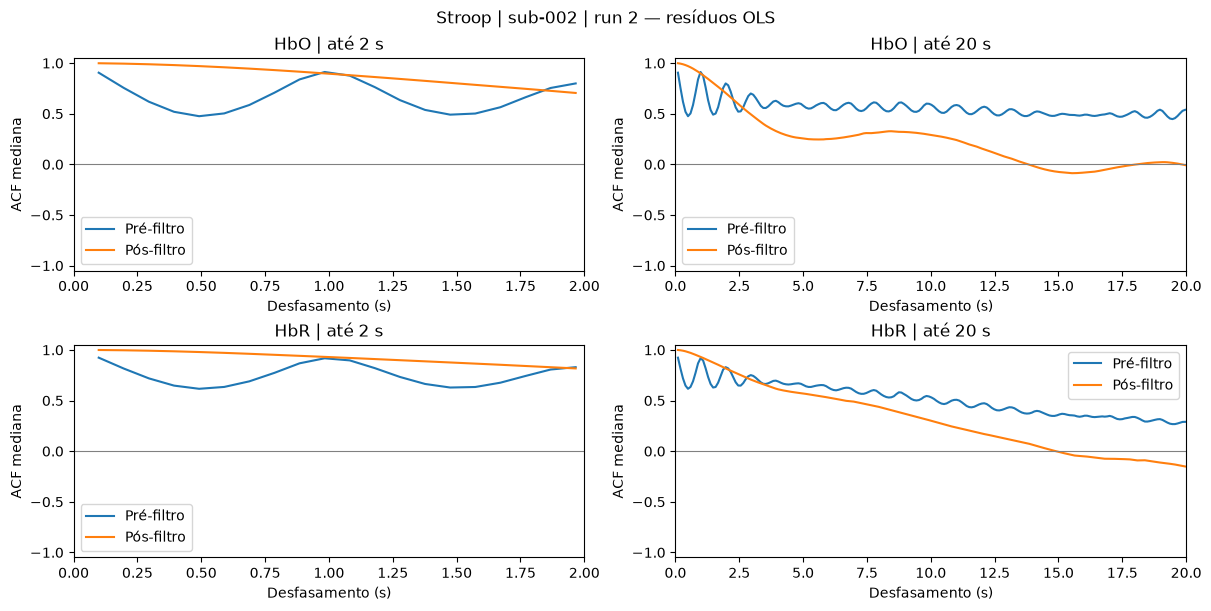

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CORTE_16B = 40
COLS_16B = ["Congruente", "Incongruente", "constant"]
pre_16b = piloto_stroop_haemo
pos_16b = piloto_stroop_haemo_filtrado
canais_16b = df_stroop_14_comparacao
linhas_16b, curvas_16b = [], {}

if set(pre_16b) != set(pos_16b) or len(pos_16b) != 4:
    raise RuntimeError("Esperavam-se as mesmas quatro runs nos dois ramos.")

for chave in sorted(pos_16b):
    sujeito, run = chave
    pre, pos = pre_16b[chave], pos_16b[chave]

    if (
        pre is pos
        or pre.ch_names != pos.ch_names
        or pre.get_channel_types() != pos.get_channel_types()
        or set(pre.info["bads"]) != set(pos.info["bads"])
        or pre.first_samp != pos.first_samp
        or pre.info["sfreq"] != pos.info["sfreq"]
        or not np.array_equal(pre.times, pos.times)
    ):
        raise RuntimeError(f"{chave}: sinais pré e pós incompatíveis.")

    if any(
        str(s).casefold().startswith(("edge", "bad_acq_skip"))
        for raw in (pre, pos) for s in raw.annotations.description
    ):
        raise RuntimeError(f"{chave}: rever segmentação do filtro por anotações.")

    selecao = canais_16b.loc[
        canais_16b["sujeito"].eq(sujeito) & canais_16b["run"].eq(run)
    ]
    nomes = selecao["canal"].tolist()
    tipos = selecao["cromoforo"].to_numpy()
    if (
        not nomes
        or len(nomes) != len(set(nomes))
        or not set(nomes).issubset(set(pre.ch_names) - set(pre.info["bads"]))
    ):
        raise RuntimeError(f"{chave}: seleção de canais inválida.")

    teste = pre.copy().load_data().filter(
        l_freq=BANDA_STROOP_08[0],
        h_freq=BANDA_STROOP_08[1],
        method="iir",
        iir_params=IIR_STROOP_08.copy(),
        phase="zero",
        verbose=False,
    )
    y_recriado = teste.get_data(picks=nomes) * 1e6
    y_pos = pos.get_data(picks=nomes) * 1e6
    if not np.allclose(y_recriado, y_pos, rtol=1e-6, atol=1e-8):
        erro = np.max(np.abs(y_recriado - y_pos))
        raise RuntimeError(
            f"{chave}: filtro não reproduziu a Etapa 8 "
            f"(erro máximo: {erro:.6g} µM). Rever antes do ajuste."
        )
    del teste, y_recriado

    sfreq = float(pos.info["sfreq"])
    lag_1s = max(1, round(sfreq))
    lag_max = min(int(20 * sfreq), pos.n_times - CORTE_16B - 1)
    if lag_max < lag_1s:
        raise RuntimeError(f"{chave}: janela insuficiente.")

    acfs = {}
    for ramo, matriz, y in (
        ("pre", piloto_stroop_matrizes_10[chave]["referencia"],
         pre.get_data(picks=nomes) * 1e6),
        ("pos", piloto_stroop_matrizes_11[chave]["referencia"], y_pos),
    ):
        if (
            list(matriz.columns) != COLS_16B
            or not np.array_equal(matriz.index.to_numpy(), pos.times)
        ):
            raise RuntimeError(f"{chave} / {ramo}: desenho incompatível.")

        x = matriz.to_numpy(dtype=float)[CORTE_16B:]
        yy = y.T[CORTE_16B:]
        if not (np.isfinite(x).all() and np.isfinite(yy).all()):
            raise RuntimeError(f"{chave} / {ramo}: valores não finitos.")

        b, _, posto, _ = np.linalg.lstsq(x, yy, rcond=None)
        if posto != len(COLS_16B):
            raise RuntimeError(f"{chave} / {ramo}: posto incompleto.")

        acfs[ramo] = acf_12(yy - x @ b, lag_max)
        if not np.isfinite(acfs[ramo]).all():
            raise RuntimeError(f"{chave} / {ramo}: ACF indefinida.")

    curvas_16b[chave] = (np.arange(lag_max + 1) / sfreq, tipos, acfs)
    for j, canal in enumerate(nomes):
        linha = {
            "sujeito": sujeito, "run": run, "canal": canal,
            "cromoforo": tipos[j], "n_amostras": pos.n_times - CORTE_16B,
        }
        for ramo, acf in acfs.items():
            linha[f"acf_lag1_{ramo}"] = acf[1, j]
            linha[f"abs_acf_1s_{ramo}"] = abs(acf[lag_1s, j])
            linha[f"pico_abs_{ramo}"] = np.max(np.abs(acf[1:, j]))
        linha["delta_acf_lag1"] = linha["acf_lag1_pos"] - linha["acf_lag1_pre"]
        linhas_16b.append(linha)

df_stroop_16b_canais = pd.DataFrame(linhas_16b)
df_stroop_16b_resumo = df_stroop_16b_canais.groupby(
    ["sujeito", "run", "cromoforo"], as_index=False
).agg(
    n_canais=("canal", "size"),
    n_amostras=("n_amostras", "first"),
    acf_lag1_pre=("acf_lag1_pre", "median"),
    acf_lag1_pos=("acf_lag1_pos", "median"),
    delta_acf_lag1_med=("delta_acf_lag1", "median"),
    abs_acf_1s_pre=("abs_acf_1s_pre", "median"),
    abs_acf_1s_pos=("abs_acf_1s_pos", "median"),
    pico_abs_pre=("pico_abs_pre", "median"),
    pico_abs_pos=("pico_abs_pos", "median"),
)

print("ETAPA 16B — OLS PRÉ/PÓS-FILTRO, MESMA JANELA")
print(df_stroop_16b_resumo.round(4).to_string(index=False))

for (sujeito, run), (t, tipos, acfs) in curvas_16b.items():
    fig, axs = plt.subplots(2, 2, figsize=(12, 6), layout="constrained")
    for i, (tipo, titulo) in enumerate((("hbo", "HbO"), ("hbr", "HbR"))):
        canais_tipo = tipos == tipo
        for ax, limite in zip(axs[i], (2, 20)):
            janela = (t > 0) & (t <= limite)
            for ramo, label in (("pre", "Pré-filtro"), ("pos", "Pós-filtro")):
                med = np.median(acfs[ramo][:, canais_tipo], axis=1)
                ax.plot(t[janela], med[janela], label=label)
            ax.axhline(0, color="0.5", linewidth=0.8)
            ax.set(
                xlim=(0, limite), ylim=(-1.05, 1.05),
                title=f"{titulo} | até {limite} s",
                xlabel="Desfasamento (s)", ylabel="ACF mediana",
            )
            ax.legend()
    fig.suptitle(f"Stroop | {sujeito} | run {run} — resíduos OLS")
    plt.show()
    plt.close(fig)

## Etapa 17 — Stroop: comparação das ordens AR antes e depois do filtro

### Objetivo
Verificar se a dependência residual observada após AR(10), AR(20)
e AR(40) no ramo pós-filtro também persiste no ramo pré-filtro.

### Entradas
- `piloto_stroop_haemo`: HbO/HbR pré-filtro, verificado na Etapa 16B.
- `piloto_stroop_matrizes_10`: desenhos não filtrados, versão de 10 s.
- `df_stroop_16b_canais`: canais e diagnóstico OLS emparelhado.
- `df_stroop_15_canais`, `curvas_15`, `tempos_acf_15`: pós-filtro.
- `acf_12`: função de cálculo da ACF residual.

### Procedimento
1. Estimar AR(10), AR(20) e AR(40) por Yule–Walker, por canal e run,
   a partir dos resíduos OLS da série pré-filtro completa.
2. Aplicar cada transformação ao sinal e a todas as colunas da
   matriz, incluindo a constante. Ajustar a partir do índice 40.
3. Confirmar que o OLS pré-filtro reproduz a Etapa 16B.
4. Emparelhar pré e pós por participante, run, canal, cromóforo e
   ordem. Resumir apenas canais com os quatro ajustes nos dois ramos.
5. Comparar a ACF a uma amostra, a cerca de 1 s e até 20 s.
   Guardar também condicionamento, estabilidade e contraste.

### Saídas
- `df_stroop_17_pre`: ajustes válidos no ramo pré-filtro.
- `df_stroop_17_comparacao`: diagnóstico emparelhado por canal e ordem.
- `df_stroop_17_resumo`: medianas por run, cromóforo e modelo.
- `df_stroop_17_falhas`: ajustes AR pré-filtro que não passaram as verificações.
- Quatro figuras: curvas residuais pré/pós-filtro por run.

### Limites
A comparação é entre dois ramos completos (sinal e desenho).
Não se escolhe um modelo pela direção do contraste. Não se fazem
testes inferenciais, análise por épocas, SSR ou WINGS. Nenhum
ficheiro é escrito.

A ajustar o ramo pré-filtro: sub-001 | run 1...
A ajustar o ramo pré-filtro: sub-001 | run 2...
A ajustar o ramo pré-filtro: sub-002 | run 1...
A ajustar o ramo pré-filtro: sub-002 | run 2...

ETAPA 17 — ACF RESIDUAL PRÉ/PÓS-FILTRO, POR ORDEM
sujeito  run cromoforo  ordem modelo  n_canais  acf_lag1_pre  acf_lag1_pos  delta_lag1_med  abs_acf_1s_pre  abs_acf_1s_pos  pico_abs_pre  pico_abs_pos  condicao_max_pre  raiz_max_pre
sub-001    1       hbo      0    OLS        19        0.9700        0.9988          0.0291          0.9033          0.9007        0.9719        0.9988            2.3274           NaN
sub-001    1       hbo     10 AR(10)        19       -0.0101        0.9705          0.9799          0.0532          0.1886        0.1200        0.9705            4.0288        0.9971
sub-001    1       hbo     20 AR(20)        19       -0.0157        0.9707          0.9794          0.0052          0.1477        0.0615        0.9707            3.4752        0.9967
sub-001    1       hbo   

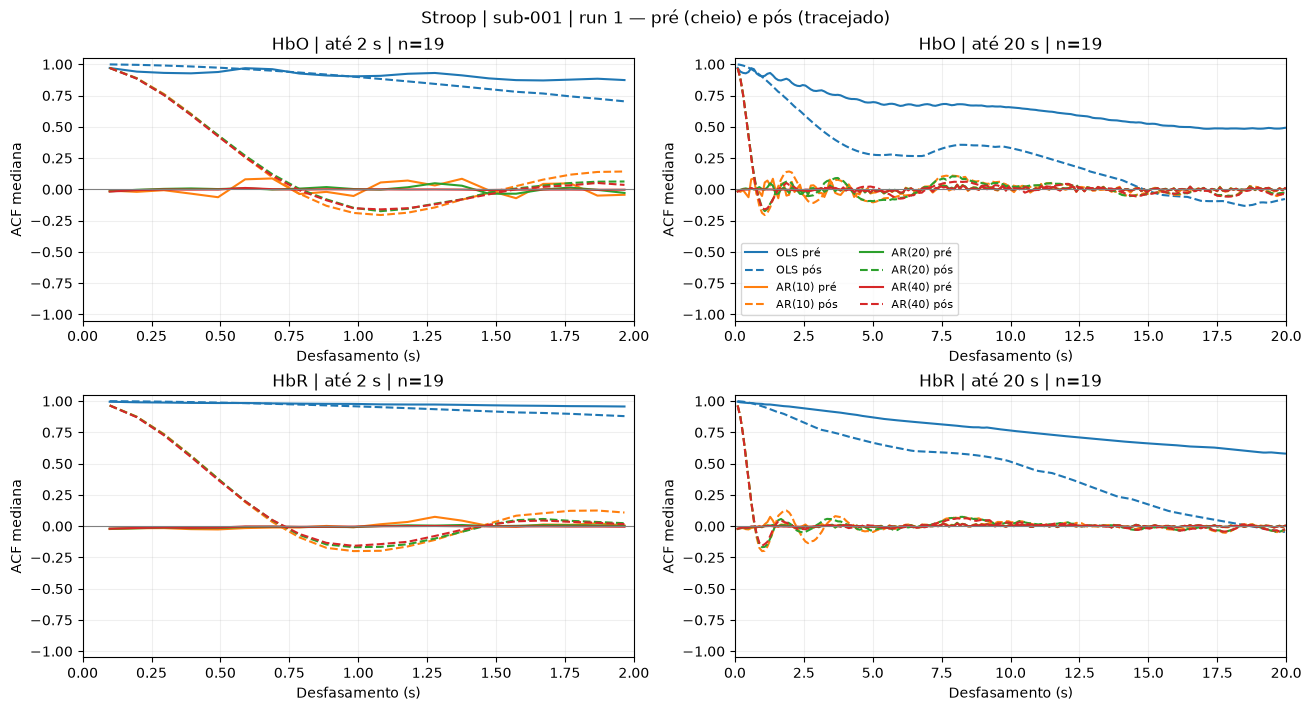

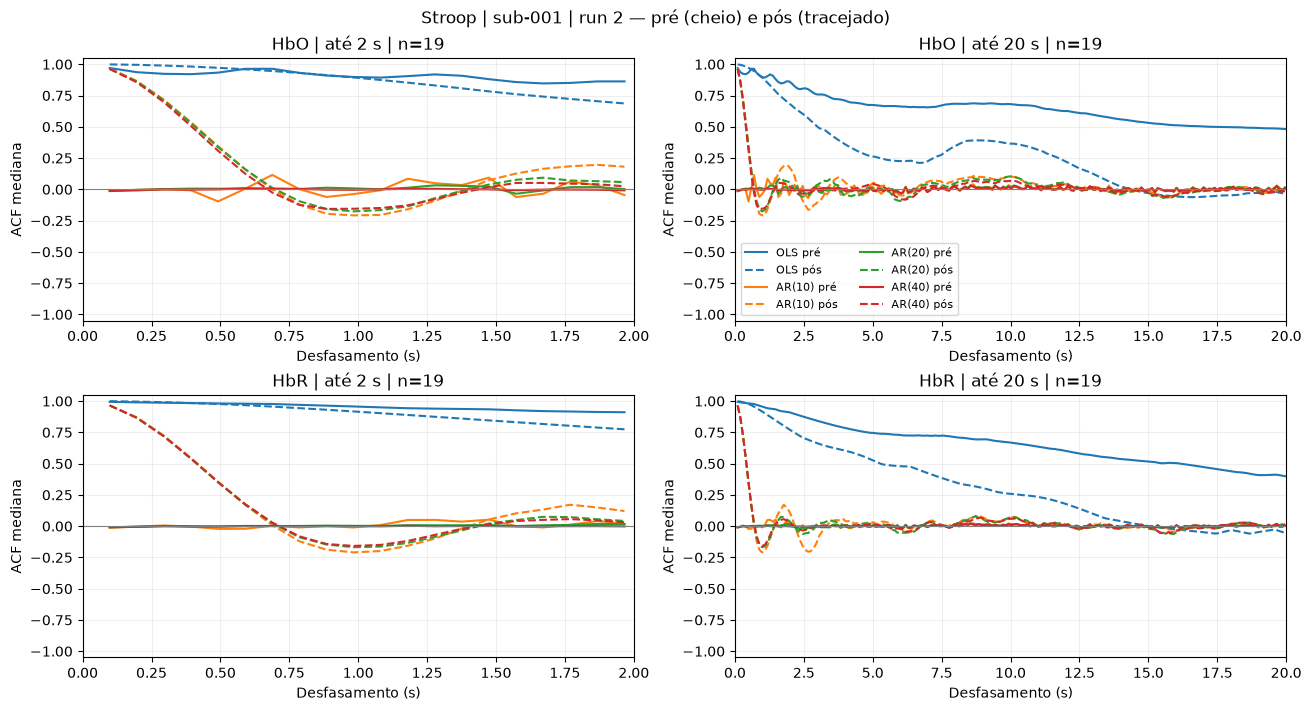

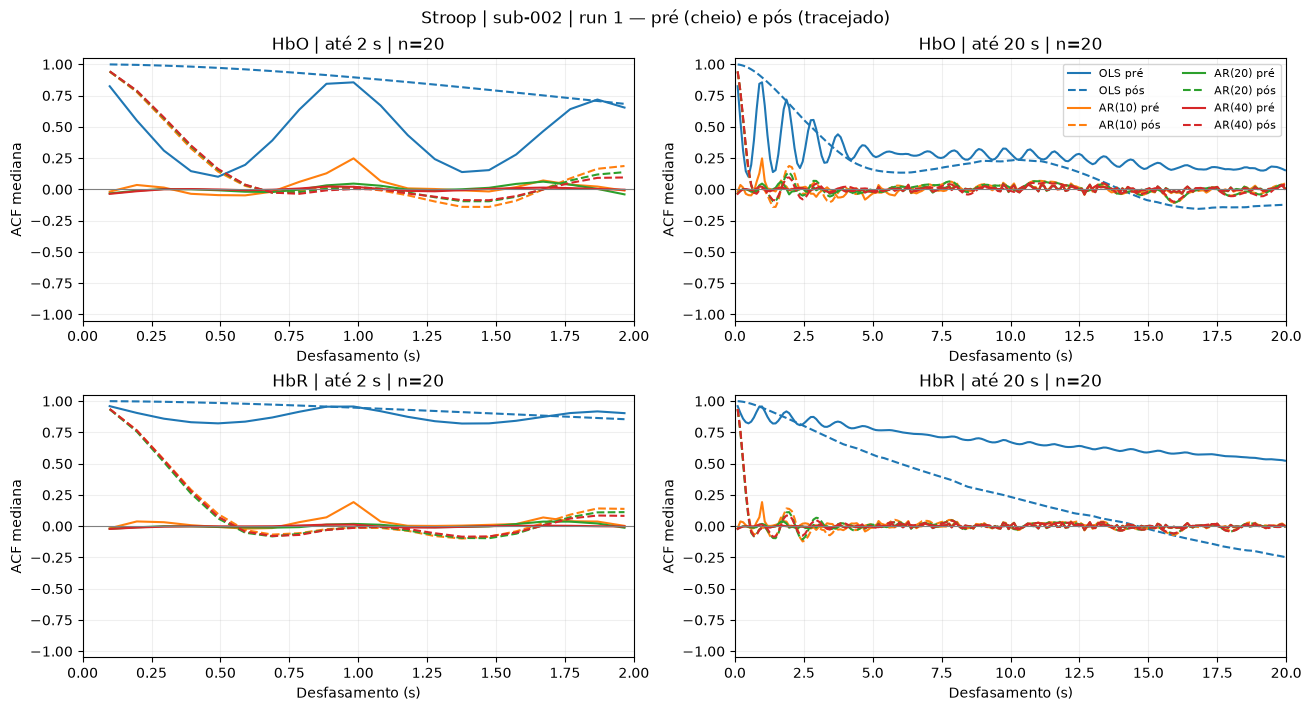

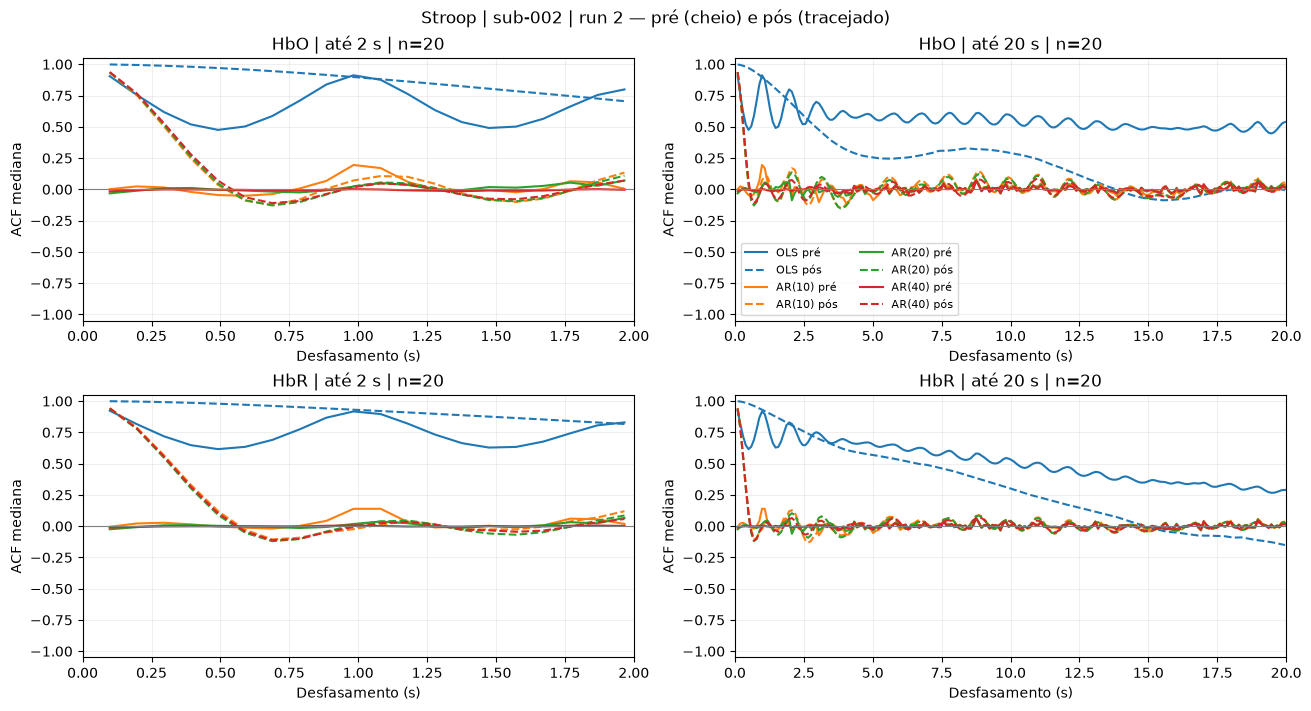

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import solve_toeplitz
from scipy.signal import lfilter

ORDENS_17 = (0, 10, 20, 40)
CORTE_17 = 40
COLUNAS_17 = ["Congruente", "Incongruente", "constant"]
IDS_17 = ["sujeito", "run", "cromoforo", "canal"]
NOMES_17 = {0: "OLS", 10: "AR(10)", 20: "AR(20)", 40: "AR(40)"}

linhas_17, falhas_17 = [], []
curvas_pre_17 = {}

for chave, raw in sorted(piloto_stroop_haemo.items()):
    sujeito, run = chave
    dados = df_stroop_16b_canais
    dados = dados.loc[dados["sujeito"].eq(sujeito) & dados["run"].eq(run)]
    canais = dados["canal"].tolist()
    dm = piloto_stroop_matrizes_10[chave]["referencia"]

    if (
        not canais or len(canais) != len(set(canais))
        or not set(canais).issubset(set(raw.ch_names) - set(raw.info["bads"]))
        or list(dm.columns) != COLUNAS_17
        or not np.array_equal(dm.index.to_numpy(), raw.times)
        or not dados["n_amostras"].eq(raw.n_times - CORTE_17).all()
    ):
        raise RuntimeError(f"{chave}: canais, desenho ou janela incompatíveis.")

    x = dm.to_numpy(dtype=float)
    y = raw.get_data(picks=canais).T * 1e6
    if not (np.isfinite(x).all() and np.isfinite(y).all()):
        raise RuntimeError(f"{chave}: entrada não finita.")

    sfreq = float(raw.info["sfreq"])
    lag_1s = max(1, round(sfreq))
    lag_max = min(int(20 * sfreq), raw.n_times - CORTE_17 - 1)
    t = np.arange(lag_max + 1) / sfreq
    if lag_max < lag_1s or not np.array_equal(t, tempos_acf_15[chave]):
        raise RuntimeError(f"{chave}: grelhas de ACF pré/pós incompatíveis.")

    b_full, _, posto, _ = np.linalg.lstsq(x, y, rcond=None)
    if posto != len(COLUNAS_17):
        raise RuntimeError(f"{chave}: OLS da série completa sem posto completo.")
    e_full = y - x @ b_full
    e_full -= e_full.mean(axis=0, keepdims=True)

    print(f"A ajustar o ramo pré-filtro: {sujeito} | run {run}...", flush=True)

    for j, linha in enumerate(dados.itertuples(index=False)):
        e = e_full[:, j]
        gamma = np.array([
            np.dot(e[k:], e[:len(e) - k]) / len(e)
            for k in range(CORTE_17 + 1)
        ])

        for p in ORDENS_17:
            ids = {
                "sujeito": sujeito, "run": run, "cromoforo": linha.cromoforo,
                "canal": linha.canal, "ordem": p,
            }
            try:
                raiz = np.nan
                if p == 0:
                    xx, yy = x[CORTE_17:], y[CORTE_17:, j]
                else:
                    if not np.isfinite(gamma).all() or gamma[0] <= 0:
                        raise ValueError("Autocovariância inicial inválida.")
                    rho = gamma[:p + 1] / gamma[0]
                    phi = solve_toeplitz(rho[:-1], rho[1:])
                    if not np.isfinite(phi).all():
                        raise ValueError("Coeficientes AR não finitos.")
                    filtro = np.r_[1.0, -phi]
                    raiz = float(np.max(np.abs(np.roots(filtro))))
                    if not np.isfinite(raiz) or raiz >= 1:
                        raise ValueError(f"AR instável: raiz máxima = {raiz:.8g}.")
                    xx = lfilter(filtro, [1.0], x, axis=0)[CORTE_17:]
                    yy = lfilter(filtro, [1.0], y[:, j])[CORTE_17:]

                b, _, posto, sv = np.linalg.lstsq(xx, yy, rcond=None)
                if posto != len(COLUNAS_17) or not np.isfinite(b).all():
                    raise ValueError("Ajuste inválido ou posto incompleto.")

                acf = acf_12((yy - xx @ b)[:, None], lag_max)[:, 0]
                if not np.isfinite(acf).all():
                    raise ValueError("ACF residual indefinida.")

                pico = np.max(np.abs(acf[1:]))
                if p == 0 and not np.allclose(
                    [acf[1], abs(acf[lag_1s]), pico],
                    [linha.acf_lag1_pre, linha.abs_acf_1s_pre, linha.pico_abs_pre],
                    rtol=0, atol=1e-8,
                ):
                    raise ValueError("O OLS pré-filtro não reproduz a Etapa 16B.")

            except (ValueError, np.linalg.LinAlgError) as erro:
                if p == 0:
                    raise RuntimeError(f"{chave} / {linha.canal}: {erro}") from erro
                falhas_17.append({**ids, "motivo": str(erro)})
                continue

            linhas_17.append({
                **ids, "n_amostras": len(yy), "raiz_max_ar": raiz,
                "condicao_matriz": float(sv[0] / sv[-1]),
                "contraste_uM": float(b[1] - b[0]),
                "acf_lag1": acf[1], "acf_1s": acf[lag_1s],
                "abs_acf_1s": abs(acf[lag_1s]), "pico_abs_acf": pico,
            })
            curvas_pre_17[(chave, linha.cromoforo, linha.canal, p)] = acf

df_stroop_17_pre = pd.DataFrame(linhas_17)
df_stroop_17_falhas = pd.DataFrame(
    falhas_17, columns=IDS_17 + ["ordem", "motivo"]
)

chaves_17 = IDS_17 + ["ordem"]
metricas_17 = [
    "n_amostras", "raiz_max_ar", "condicao_matriz", "contraste_uM",
    "acf_lag1", "acf_1s", "abs_acf_1s", "pico_abs_acf",
]
d17 = df_stroop_17_pre.merge(
    df_stroop_15_canais[chaves_17 + metricas_17],
    on=chaves_17, how="inner", validate="one_to_one",
    suffixes=("_pre", "_pos"),
)
if not d17["n_amostras_pre"].eq(d17["n_amostras_pos"]).all():
    raise RuntimeError("Há ajustes emparelhados com janelas diferentes.")

# Mesmo conjunto de canais para comparar todas as ordens e os dois ramos.
n_ordens = d17.groupby(IDS_17)["ordem"].transform("nunique")
d17 = d17.loc[n_ordens.eq(len(ORDENS_17))].copy()
d17["modelo"] = d17["ordem"].map(NOMES_17)
d17["delta_lag1_pos_menos_pre"] = d17["acf_lag1_pos"] - d17["acf_lag1_pre"]
d17["delta_contraste_pos_menos_pre_uM"] = (
    d17["contraste_uM_pos"] - d17["contraste_uM_pre"]
)
df_stroop_17_comparacao = d17

df_stroop_17_resumo = d17.groupby(
    ["sujeito", "run", "cromoforo", "ordem", "modelo"], as_index=False
).agg(
    n_canais=("canal", "size"),
    acf_lag1_pre=("acf_lag1_pre", "median"),
    acf_lag1_pos=("acf_lag1_pos", "median"),
    delta_lag1_med=("delta_lag1_pos_menos_pre", "median"),
    abs_acf_1s_pre=("abs_acf_1s_pre", "median"),
    abs_acf_1s_pos=("abs_acf_1s_pos", "median"),
    pico_abs_pre=("pico_abs_acf_pre", "median"),
    pico_abs_pos=("pico_abs_acf_pos", "median"),
    condicao_max_pre=("condicao_matriz_pre", "max"),
    raiz_max_pre=("raiz_max_ar_pre", "max"),
)

print("\nETAPA 17 — ACF RESIDUAL PRÉ/PÓS-FILTRO, POR ORDEM")
print(df_stroop_17_resumo.round(4).to_string(index=False))
print(f"\nAjustes AR pré-filtro não válidos: {len(df_stroop_17_falhas)}")
print(f"Canais–run comuns aos oito ajustes: {len(d17) // len(ORDENS_17)}")
if not df_stroop_17_falhas.empty:
    print(df_stroop_17_falhas.to_string(index=False))

for chave, t in tempos_acf_15.items():
    sujeito, run = chave
    fig, axs = plt.subplots(2, 2, figsize=(13, 7), layout="constrained")
    for i, tipo in enumerate(("hbo", "hbr")):
        canais = d17.loc[
            d17["sujeito"].eq(sujeito) & d17["run"].eq(run)
            & d17["cromoforo"].eq(tipo) & d17["ordem"].eq(0), "canal"
        ].tolist()
        for ax, limite in zip(axs[i], (2, 20)):
            mask = (t > 0) & (t <= limite)
            if canais:
                for p, cor in zip(ORDENS_17, ("C0", "C1", "C2", "C3")):
                    for curvas, estilo, ramo in (
                        (curvas_pre_17, "-", "pré"),
                        (curvas_15, "--", "pós"),
                    ):
                        a = np.stack([curvas[(chave, tipo, c, p)] for c in canais])
                        ax.plot(t[mask], np.median(a[:, mask], axis=0),
                                color=cor, linestyle=estilo,
                                label=f"{NOMES_17[p]} {ramo}")
            ax.axhline(0, color="0.5", linewidth=0.8)
            ax.set(
                xlim=(0, limite), ylim=(-1.05, 1.05),
                title=f"{'HbO' if tipo == 'hbo' else 'HbR'} | até {limite} s | n={len(canais)}",
                xlabel="Desfasamento (s)", ylabel="ACF mediana",
            )
            ax.grid(alpha=0.2)
    if axs[0, 1].get_legend_handles_labels()[0]:
        axs[0, 1].legend(ncol=2, fontsize=8)
    fig.suptitle(f"Stroop | {sujeito} | run {run} — pré (cheio) e pós (tracejado)")
    plt.show()
    plt.close(fig)

## Etapa 18 — Stroop: sensibilidade do contraste à ordem AR e ao ramo

### Objetivo
Quantificar quanto muda o contraste Incongruente − Congruente
ao passar de AR(20) para AR(40) no pré-filtro e ao passar de
pré para pós-filtro mantendo fixa a ordem AR.

### Entrada
- `df_stroop_17_comparacao`: resultados emparelhados da Etapa 17,
  com os mesmos canais, blocos de 10 s e janela após 40 amostras.

### Procedimento
1. Emparelhar AR(20) e AR(40) por participante, run, canal
   e cromóforo, sem combinar runs.
2. Calcular diferenças com sinal, diferenças absolutas e inversões
   estritas de sinal para as três comparações.
3. Resumir as diferenças por run e cromóforo e mostrar os cinco
   canais com maior alteração absoluta em cada comparação.
4. Inspecionar a distribuição por canal de |ACF| a uma amostra,
   |ACF| a cerca de 1 s e o pico absoluto da ACF até 20 s.
   Reportar a mediana, o percentil 90 e o máximo.

### Saídas
- `df_stroop_18_contrastes`: diferenças por canal e comparação.
- `df_stroop_18_resumo`: síntese por run, cromóforo e comparação.
- `df_stroop_18_acf`: distribuição da ACF por ramo e ordem.

### Limites
Diagnóstico descritivo de quatro runs de dois participantes.
Não se voltam a ajustar modelos, não se fazem testes inferenciais,
não se escolhe um modelo pelo sinal do contraste e não se escrevem
ficheiros. A baseline local de 1 s pertence à análise por épocas,
não a este contraste do GLM.

In [31]:
import numpy as np
import pandas as pd

IDS_18 = ["sujeito", "run", "cromoforo", "canal"]
GRUPOS_18 = IDS_18[:3]
METRICAS_18 = [
    "contraste_uM", "acf_lag1", "abs_acf_1s", "pico_abs_acf",
    "n_amostras",
]
COLUNAS_18 = [
    f"{metrica}_{ramo}"
    for metrica in METRICAS_18
    for ramo in ("pre", "pos")
]

base_18 = df_stroop_17_comparacao.loc[
    df_stroop_17_comparacao["ordem"].isin([20, 40]),
    IDS_18 + ["ordem"] + COLUNAS_18,
].copy()

if base_18.empty or base_18.duplicated(IDS_18 + ["ordem"]).any():
    raise RuntimeError("Etapa 17: faltam ajustes ou há chaves duplicadas.")
if not np.isfinite(base_18[COLUNAS_18].to_numpy(dtype=float)).all():
    raise RuntimeError("Etapa 17: há resultados não finitos.")

pares_18 = base_18.pivot(index=IDS_18, columns="ordem", values=COLUNAS_18)
esperadas_18 = pd.MultiIndex.from_product([COLUNAS_18, [20, 40]])
pares_18 = pares_18.reindex(columns=esperadas_18)
if pares_18.isna().any().any():
    raise RuntimeError("Há canais sem o par completo AR(20)/AR(40).")

janelas_18 = pares_18["n_amostras_pre"][20]
if not all(
    janelas_18.eq(pares_18[f"n_amostras_{ramo}"][p]).all()
    for ramo in ("pre", "pos") for p in (20, 40)
):
    raise RuntimeError("As janelas de ajuste não coincidem.")

comparacoes_18 = [
    ("AR40 pré − AR20 pré", ("contraste_uM_pre", 20), ("contraste_uM_pre", 40)),
    ("AR20 pós − AR20 pré", ("contraste_uM_pre", 20), ("contraste_uM_pos", 20)),
    ("AR40 pós − AR40 pré", ("contraste_uM_pre", 40), ("contraste_uM_pos", 40)),
]

tabelas_18 = []
for nome, chave_a, chave_b in comparacoes_18:
    a = pares_18[chave_a]
    b = pares_18[chave_b]
    t = pd.DataFrame({
        "comparacao": nome,
        "contraste_a_uM": a,
        "contraste_b_uM": b,
        "delta_uM": b - a,
        "delta_abs_uM": (b - a).abs(),
        "inversao_sinal": (a.lt(0) & b.gt(0)) | (a.gt(0) & b.lt(0)),
    }).reset_index()
    tabelas_18.append(t)

df_stroop_18_contrastes = pd.concat(tabelas_18, ignore_index=True)

df_stroop_18_resumo = df_stroop_18_contrastes.groupby(
    ["comparacao"] + GRUPOS_18, as_index=False, sort=False
).agg(
    n_canais=("canal", "size"),
    delta_med_uM=("delta_uM", "median"),
    delta_abs_med_uM=("delta_abs_uM", "median"),
    delta_abs_p90_uM=("delta_abs_uM", lambda s: s.quantile(0.90)),
    delta_abs_max_uM=("delta_abs_uM", "max"),
    inversoes=("inversao_sinal", "sum"),
)

tabelas_acf_18 = []
for ramo in ("pre", "pos"):
    t = base_18[IDS_18 + ["ordem"]].copy()
    t["ramo"] = ramo
    t["abs_lag1"] = base_18[f"acf_lag1_{ramo}"].abs()
    t["abs_1s"] = base_18[f"abs_acf_1s_{ramo}"]
    t["pico_abs_20s"] = base_18[f"pico_abs_acf_{ramo}"]
    tabelas_acf_18.append(t)

acf_long_18 = pd.concat(tabelas_acf_18, ignore_index=True).melt(
    id_vars=IDS_18 + ["ordem", "ramo"],
    value_vars=["abs_lag1", "abs_1s", "pico_abs_20s"],
    var_name="metrica",
    value_name="valor",
)

df_stroop_18_acf = acf_long_18.groupby(
    GRUPOS_18 + ["ordem", "ramo", "metrica"], as_index=False
).agg(
    n_canais=("canal", "size"),
    mediana=("valor", "median"),
    p90=("valor", lambda s: s.quantile(0.90)),
    maximo=("valor", "max"),
)

print(f"ETAPA 18 — {len(pares_18)} canais–run emparelhados por comparação")
print("\nDIFERENÇAS DO CONTRASTE (B − A), EM µM")
print(df_stroop_18_resumo.round(4).to_string(index=False))

for nome, _, _ in comparacoes_18:
    top = df_stroop_18_contrastes.loc[
        df_stroop_18_contrastes["comparacao"].eq(nome)
    ].nlargest(5, "delta_abs_uM")
    print(f"\n{nome} — CINCO MAIORES ALTERAÇÕES")
    print(top[IDS_18 + [
        "contraste_a_uM", "contraste_b_uM", "delta_uM", "inversao_sinal"
    ]].round(4).to_string(index=False))

print("\nPICO ABSOLUTO DA ACF ATÉ 20 s — DISTRIBUIÇÃO POR CANAL")
picos_18 = df_stroop_18_acf.loc[
    df_stroop_18_acf["metrica"].eq("pico_abs_20s")
]
print(picos_18.drop(columns="metrica").round(4).to_string(index=False))
print("\nAs três métricas da ACF estão em df_stroop_18_acf.")

ETAPA 18 — 156 canais–run emparelhados por comparação

DIFERENÇAS DO CONTRASTE (B − A), EM µM
         comparacao sujeito  run cromoforo  n_canais  delta_med_uM  delta_abs_med_uM  delta_abs_p90_uM  delta_abs_max_uM  inversoes
AR40 pré − AR20 pré sub-001    1       hbo        19        0.0352            0.0352            0.0594            0.0598          1
AR40 pré − AR20 pré sub-001    1       hbr        19       -0.0001            0.0023            0.0288            0.0318          1
AR40 pré − AR20 pré sub-001    2       hbo        19       -0.0331            0.0331            0.0568            0.0878          0
AR40 pré − AR20 pré sub-001    2       hbr        19        0.0004            0.0023            0.0128            0.0140          0
AR40 pré − AR20 pré sub-002    1       hbo        20       -0.0036            0.0050            0.0145            0.0236          0
AR40 pré − AR20 pré sub-002    1       hbr        20       -0.0000            0.0008            0.0016            